# Huấn luyện và đánh giá PhoBERT

**CO5087 – Cách tiếp cận hiện đại trong xử lý ngôn ngữ tự nhiên**

Notebook nhận dataset sạch từ `Dataset_VietNamNet.ipynb`, tiền xử lý tiếng Việt,
mã hóa Head–Tail, fine-tune PhoBERT-base-v2 và xuất kết quả phục vụ báo cáo cùng ứng dụng.


## Môi trường thực thi

Chọn kernel **Python 3.14** trên máy có GPU NVIDIA và bấm **Run All**.
Notebook đọc dataset sạch trong `dataset/` và lưu đầu ra ngay trong thư mục dự án.
Cell đầu kiểm tra Python, PyTorch CUDA, GPU và kết nối tải backbone.

- Chia phân tầng **70% train / 15% validation / 15% test**, seed 42, sau khi loại văn bản trùng.
- Trọng số balanced tính từ số mẫu của từng class trong train: `N_train / (20 × n_class)`.
- Một GPU xử lý batch 32; tích lũy gradient 2 tạo effective batch 64.
  Kiểm định dùng batch 64. RTX A3000 sử dụng BF16 và TF32.
- Tối đa **7 epoch**, early stopping theo Macro-F1 validation, patience **2**, ngưỡng **0,001**.
- Learning rate `2e-5`, weight decay `0.01`, warmup **200 bước**.
- Validation chọn checkpoint và fit calibration; test chỉ dùng đánh giá cuối.
- Mặc định `fresh` khởi tạo model từ backbone. `continue` nạp trọng số tương thích;
  `evaluate` chỉ đánh giá. Train tiếp khởi tạo optimizer/scheduler mới.
- Cache tiền xử lý và tensor được tái sử dụng khi fingerprint khớp dataset và ba tập.
- Tiến độ cập nhật tại chỗ bằng văn bản. Mỗi biểu đồ là một PNG độc lập 300 dpi.

Kết quả nằm trong `model/`, `result/`, `report/source_latex/assets/` và `app/artifacts/`.
Cache nằm trong `temp/`; model đã fine-tune không được nạp trong chế độ `fresh`.

Tài liệu kỹ thuật: [PyTorch](https://pytorch.org/get-started/locally/),
[Hugging Face Trainer](https://huggingface.co/docs/transformers/en/main_classes/trainer).


In [1]:
from pathlib import Path
import os
import sys
import torch
from urllib.request import urlopen

LOCAL_READY = False
if not torch.cuda.is_available():
    raise RuntimeError("Chọn Python có PyTorch CUDA và GPU NVIDIA trước khi Run All.")
GPU_INDEX = 0
torch.cuda.set_device(GPU_INDEX)
gpu = torch.cuda.get_device_properties(GPU_INDEX)
print(f"# GPU: {gpu.name} | {gpu.total_memory / 2**30:.1f} GiB | CUDA {torch.version.cuda}.")
try:
    with urlopen(
        "https://huggingface.co/vinai/phobert-base-v2/resolve/main/config.json",
        timeout=20,
    ) as response:
        if response.status != 200:
            raise RuntimeError(f"HTTP {response.status}")
except Exception as error:
    raise RuntimeError("Kiểm tra Internet để tải backbone PhoBERT.") from error
LOCAL_READY = True
print(f"# Môi trường sẵn sàng; Python {sys.version.split()[0]}, PyTorch {torch.__version__}.")


# GPU: NVIDIA RTX A3000 12GB Laptop GPU | 12.0 GiB | CUDA 12.8.
# Môi trường sẵn sàng; Python 3.14.7, PyTorch 2.11.0+cu128.


## Kiểm tra thư viện


In [2]:
import importlib
import importlib.metadata
from packaging.requirements import Requirement
from packaging.version import Version

if not LOCAL_READY:
    raise RuntimeError("Chạy cell kiểm tra môi trường trước.")
NOTEBOOK_PACKAGES = [
    "torch>=2.6",
    "transformers==5.17.0",
    "accelerate==1.15.0",
    "pyvi==0.1.1",
    "sentencepiece>=0.2.1",
    "pyarrow>=15",
    "pandas>=2.2",
    "scikit-learn>=1.4",
    "matplotlib>=3.10",
    "scipy>=1.11",
    "ipykernel>=7",
]
missing_packages = []
for specification in NOTEBOOK_PACKAGES:
    requirement = Requirement(specification)
    try:
        installed = importlib.metadata.version(requirement.name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed is None or installed not in requirement.specifier:
        missing_packages.append(specification)
if missing_packages:
    raise RuntimeError(
        "Thư viện chưa tương thích: " + ", ".join(missing_packages)
        + ". Cài requirements-notebook.txt vào kernel đang chọn rồi khởi động lại kernel."
    )
print("# Thư viện tiền xử lý, huấn luyện và xuất hình sẵn sàng.")


# Thư viện tiền xử lý, huấn luyện và xuất hình sẵn sàng.


In [3]:
import os
import sys
import json
import time
import datetime
import hashlib
import re
from pathlib import Path
from urllib.parse import urljoin, urlparse

NOTEBOOK_FILENAME = "PhoBERT_Classification.ipynb"


def find_project_root(start):
    start = Path(start).resolve()
    candidates = [start, start / "BTL_NLP_VietnamNet", *start.parents]
    for candidate in candidates:
        if (candidate / NOTEBOOK_FILENAME).is_file() and (candidate / "dataset").is_dir():
            return candidate
    raise FileNotFoundError("Mở notebook từ thư mục dự án có folder dataset.")


RUN_ROOT = find_project_root(Path.cwd())
DATASET_DIR = str(RUN_ROOT / "dataset")
NOTEBOOK_SOURCE_PATH = RUN_ROOT / NOTEBOOK_FILENAME
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
print("# Dataset đầu vào: " + DATASET_DIR)
print("# Thư mục dự án: " + str(RUN_ROOT))


from IPython.core.getipython import get_ipython
from IPython.display import display


class TextProgress:
    """One plain-text display per process, updated in place without widgets."""

    def __init__(
        self, iterable=None, total=None, desc="Tiến độ", interval=1.0, **kwargs
    ):
        self.iterable = iterable
        self.total = total if total is not None else self._length(iterable)
        self.description = desc.strip().replace("_", " ")
        self.interval = interval
        self.count = 0
        self.started = time.monotonic()
        self.last_print = self.started
        self.closed = False
        self.details = ""
        self.handle = None
        self.last_width = 0
        shell = get_ipython()
        self.in_notebook = (
            shell is not None and getattr(shell, "kernel", None) is not None
        )
        self._print()

    @staticmethod
    def _length(iterable):
        try:
            return len(iterable)
        except (TypeError, AttributeError):
            return None

    def _print(self):
        elapsed = time.monotonic() - self.started
        if self.total is not None and self.total > 0:
            ratio = min(self.count / self.total, 1)
            filled = int(24 * ratio)
            bar = "#" * filled + "-" * (24 - filled)
            status = f"[{bar}] {self.count:,}/{self.total:,} ({ratio:.1%})"
        else:
            status = f"{self.count:,} mục"
        speed = self.count / elapsed if elapsed > 0 else 0
        message = f"# {self.description}: {status} | {elapsed:.0f} giây | {speed:.1f} mục/giây"
        if self.details:
            message += " | " + self.details
        if self.in_notebook:
            content = {"text/plain": message}
            if self.handle is None:
                self.handle = display(content, raw=True, display_id=True)
            else:
                self.handle.update(content, raw=True)
        else:
            print("\r" + message.ljust(self.last_width), end="", flush=True)
            self.last_width = len(message)
        self.last_print = time.monotonic()

    def update(self, amount=1, details=None, force=False):
        self.count += amount
        if details is not None:
            self.details = details
        if force or time.monotonic() - self.last_print >= self.interval:
            self._print()

    def close(self):
        if not self.closed:
            self._print()
            if not self.in_notebook:
                print(flush=True)
            self.closed = True

    def __iter__(self):
        iterable = self.iterable
        if iterable is None:
            raise TypeError("Tiến độ dạng vòng lặp cần một iterable.")
        try:
            for item in iterable:
                yield item
                self.update()
        finally:
            self.close()

    def __enter__(self):
        return self

    def __exit__(self, *args):
        self.close()


def log(message, level="INFO"):
    labels = {
        "INFO": "Thông tin",
        "OK": "Hoàn tất",
        "WARN": "Lưu ý",
        "SAVE": "Lưu kết quả",
        "GPU": "Bộ nhớ GPU",
    }
    print(f"# {labels.get(level, level)}: {message}", flush=True)


class timer:
    def __init__(self, label):
        self.label = label

    def __enter__(self):
        self.started = time.monotonic()
        return self

    def __exit__(self, *args):
        log(f"{self.label}: {time.monotonic() - self.started:.1f} giây", "OK")


def _atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    pending = path.with_name(path.name + f".{os.getpid()}.tmp")
    pending.write_text(
        json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    for attempt in range(7):
        try:
            os.replace(pending, path)
            break
        except PermissionError:
            if attempt == 6:
                raise
            time.sleep(0.05 * 2**attempt)

# Dataset đầu vào: C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\dataset
# Thư mục dự án: C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet


## Kiểm tra dataset đầu vào


In [4]:
import pyarrow.parquet as pq
from datetime import datetime, timezone

CATEGORY_LABELS = {
    "chinh-tri": "Chính trị",
    "thoi-su": "Thời sự",
    "kinh-doanh": "Kinh doanh",
    "dan-toc-ton-giao": "Dân tộc - Tôn giáo",
    "the-thao": "Thể thao",
    "giao-duc": "Giáo dục",
    "the-gioi": "Thế giới",
    "doi-song": "Đời sống",
    "van-hoa-giai-tri": "Văn hóa - Giải trí",
    "suc-khoe": "Sức khỏe",
    "cong-nghe": "Công nghệ",
    "oto-xe-may": "Ô tô - Xe máy",
    "du-lich": "Du lịch",
    "bat-dong-san": "Bất động sản",
    "ban-doc": "Bạn đọc",
    "tuan-viet-nam": "Tuần Việt Nam",
    "nong-thon-moi": "Nông thôn mới",
    "noi-dung-chuyen-de": "Nội dung chuyên đề",
    "dan-toc-thieu-so-va-mien-nui": "Dân tộc thiểu số và miền núi",
    "cong-nghiep-ho-tro": "Công nghiệp hỗ trợ",
}
CATEGORY_PATHS = {key: key for key in CATEGORY_LABELS}
CATEGORY_PATHS["cong-nghiep-ho-tro"] = "hop-tac/cong-nghiep-ho-tro"
CANONICAL_CLASSES = sorted(CATEGORY_LABELS.values())


CATEGORIES = list(CATEGORY_LABELS)
CLEANING_VERSION = "editorial-breadcrumb"
POLICY_SIGNATURE = hashlib.sha256(
    json.dumps(
        [CLEANING_VERSION, CATEGORY_LABELS, CATEGORY_PATHS],
        sort_keys=True,
        ensure_ascii=False,
    ).encode()
).hexdigest()


def normalize_url(url, base="https://vietnamnet.vn"):
    if not isinstance(url, str) or not url.strip():
        return None
    parsed = urlparse(urljoin(base, url.strip()))
    if parsed.scheme not in {"http", "https"} or parsed.hostname not in {
        "vietnamnet.vn",
        "www.vietnamnet.vn",
    }:
        return None
    return "https://vietnamnet.vn" + (parsed.path.rstrip("/") or "/")


def category_from_url(url):
    url = normalize_url(url)
    if not url:
        return None
    path = urlparse(url).path.strip("/")
    routes = {**CATEGORY_PATHS, "politics_alias": "thoi-su/chinh-tri"}
    for category, route in sorted(
        routes.items(), key=lambda x: len(x[1]), reverse=True
    ):
        if path == route or path.startswith(route + "/"):
            return "chinh-tri" if category == "politics_alias" else category
    return None


def verify_clean_dataset(dataset_dir):
    dataset_dir = Path(dataset_dir)
    marker = dataset_dir / "data_URLs_meta.json"
    if not marker.exists():
        raise RuntimeError("Chưa chạy bước chuẩn hóa dataset làm sạch nhãn dataset.")
    audit = json.loads(marker.read_text(encoding="utf-8")).get("dataset_cleaning", {})
    if not audit.get("complete") or audit.get("policy_signature") != POLICY_SIGNATURE:
        raise RuntimeError(
            "Dataset chưa làm sạch xong hoặc chính sách nhãn thay đổi; chạy notebook dataset."
        )
    clean_name = (
        json.loads(marker.read_text(encoding="utf-8"))
        .get("url_files", {})
        .get("clean", "data_URLs_clean.json")
    )
    if Path(clean_name).name != clean_name:
        raise RuntimeError("Metadata có tên file URL không hợp lệ.")
    clean_path = dataset_dir / clean_name
    if not clean_path.exists():
        clean_path = dataset_dir / "data_URLs.json"
    urls = json.loads(clean_path.read_text(encoding="utf-8"))
    if set(urls) != set(CATEGORY_LABELS) or set(audit.get("after", {})) != set(
        CATEGORY_LABELS
    ):
        raise RuntimeError("Danh sách URL/audit không khớp bộ 20 class hiện tại.")
    seen = set()
    for cat in CATEGORY_LABELS:
        expected = set(urls.get(cat, []))
        if len(expected) != len(urls.get(cat, [])):
            raise RuntimeError(f"URL trùng trong class {cat}.")
        actual = set()
        for batch in pq.ParquetFile(dataset_dir / f"{cat}.parquet").iter_batches(
            batch_size=1000
        ):
            for row in batch.to_pylist():
                url = row["url"]
                if (
                    row["class"] != cat
                    or url in seen
                    or not row["title"]
                    or not row["content"]
                ):
                    raise RuntimeError(f"Bản ghi sai class/trùng/thiếu nội dung: {url}")
                if not row.get("category_method"):
                    raise RuntimeError(f"Bài chưa có bằng chứng chuyên mục: {url}")
                if category_from_url(row.get("category_path", "")) != cat:
                    raise RuntimeError(f"Đường dẫn chuyên mục không khớp class: {url}")
                if not normalize_url(url) or not urlparse(url).path.endswith(".html"):
                    raise RuntimeError(
                        f"URL sau làm sạch không phải URL bài viết: {url}"
                    )
                seen.add(url)
                actual.add(url)
        if actual != expected or len(actual) != audit["after"].get(cat):
            raise RuntimeError(f"URL, Parquet và số lượng audit không đồng bộ: {cat}.")
    if len(seen) != sum(audit["after"].values()):
        raise RuntimeError("Tổng số bài không khớp audit.")
    return audit

In [5]:
# Cổng kiểm tra bắt buộc: notebook huấn luyện chỉ nhận dataset đã làm sạch và đồng bộ.

cleaning_audit = verify_clean_dataset(DATASET_DIR)
_missing_training_classes = [
    CATEGORY_LABELS[cat] for cat in CATEGORIES if cleaning_audit["after"][cat] == 0
]
if _missing_training_classes:
    raise RuntimeError(
        f"Không thể vào notebook huấn luyện: class rỗng {_missing_training_classes}."
    )
print(
    f"Dataset sạch: {sum(cleaning_audit['after'].values()):,} bài, "
    f"{len(CATEGORIES)} class; URL và Parquet đã đối chiếu từng bản ghi."
)

Dataset sạch: 200,337 bài, 20 class; URL và Parquet đã đối chiếu từng bản ghi.


---
## Thiết lập môi trường

Chạy phần này mỗi lần mở notebook trước khi huấn luyện hoặc đánh giá.


In [6]:
import pickle
from typing import Any, Callable, cast
from pandas.util import hash_pandas_object as _hash_pandas_object
import warnings
import shutil
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score as _sk_f1_score,
    classification_report as _sk_classification_report,
    confusion_matrix,
    precision_recall_curve,
    average_precision_score,
)
# Public metric APIs accept multiple averaging modes and numeric zero-division rules.
f1_score: Callable[..., Any] = _sk_f1_score
classification_report: Callable[..., Any] = _sk_classification_report
hash_pandas_object: Callable[..., pd.Series] = cast(Callable[..., pd.Series], _hash_pandas_object)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    EarlyStoppingCallback,
    TrainerCallback,
    Trainer,
    set_seed,
)
from transformers.trainer_callback import PrinterCallback
from transformers.utils import logging as transformer_logging
from huggingface_hub.utils import disable_progress_bars, logging as hub_logging
from torch.utils.data import Dataset as TorchDataset
from IPython.display import display

%matplotlib inline
warnings.filterwarnings("ignore", category=DeprecationWarning)
disable_progress_bars()
transformer_logging.disable_progress_bar()
transformer_logging.set_verbosity_error()
hub_logging.set_verbosity_error()
# Semantic palette: primary data, comparison, improvement, neutral/reference.
CHART_COLORS = {
    "primary": "#0072B2",
    "comparison": "#D55E00",
    "positive": "#009E73",
    "neutral": "#64748B",
    "text": "#172B4D",
    "grid": "#CBD5E1",
    "muted": "#E2E8F0",
}
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
        "font.size": 14,
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "axes.labelpad": 8,
        "axes.edgecolor": CHART_COLORS["neutral"],
        "axes.labelcolor": CHART_COLORS["text"],
        "text.color": CHART_COLORS["text"],
        "xtick.color": CHART_COLORS["text"],
        "ytick.color": CHART_COLORS["text"],
        "xtick.labelsize": 12,
        "ytick.labelsize": 13,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "grid.color": CHART_COLORS["grid"],
        "grid.linewidth": 0.6,
        "lines.linewidth": 2.0,
        "lines.markersize": 5,
        "legend.fontsize": 12,
        "legend.frameon": False,
    }
)
device = f"cuda:{GPU_INDEX}"
GPU_COUNT = 1
gpu_name = torch.cuda.get_device_name(GPU_INDEX)
vram_gb = torch.cuda.get_device_properties(GPU_INDEX).total_memory / 1024**3
TF32 = torch.cuda.get_device_properties(GPU_INDEX).major >= 8
torch.backends.cuda.matmul.allow_tf32 = TF32
torch.backends.cudnn.allow_tf32 = TF32
print(f"# GPU: {gpu_name}, bộ nhớ {vram_gb:.1f} GB, CUDA {torch.version.cuda}.")


# GPU: NVIDIA RTX A3000 12GB Laptop GPU, bộ nhớ 12.0 GB, CUDA 12.8.


In [7]:


def temperature_probabilities(logits, temperature: float) -> np.ndarray:
    z = np.asarray(logits, dtype=np.float64)
    if not np.isfinite(temperature) or temperature <= 0 or not np.isfinite(z).all():
        raise ValueError(
            "Logits and temperature must be finite; temperature must be positive"
        )
    z = z / temperature
    z = z - np.max(z, axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)


def calibrated_prediction(
    logits, classes: list[str], temperature: float, thresholds, top_k: int = 3
) -> dict:
    p = temperature_probabilities(logits, temperature)
    t = np.asarray(thresholds, dtype=np.float64)
    if p.shape != (len(classes),) or t.shape != p.shape:
        raise ValueError(
            "Logits, thresholds and taxonomy must have the same number of classes"
        )
    if not np.isfinite(t).all() or np.any(t <= 0):
        raise ValueError("All class thresholds must be positive and finite")
    scores = p / t
    # Stable order also matches numpy.argmax when decision scores are tied.
    order = np.argsort(-scores, kind="stable")
    q = scores / scores.sum()
    selected = int(order[0])
    margin = float(q[order[0]] - q[order[1]]) if len(order) > 1 else 1.0
    return {
        "label": classes[selected],
        "confidence": float(p[selected]),
        "margin": margin,
        "candidates": [
            {
                "label": classes[int(i)],
                "score": float(p[i]),
                "decision_score": float(scores[i]),
            }
            for i in order[: max(1, min(int(top_k), 5))]
        ],
    }


def expected_calibration_error(logits, labels, temperature=1.0, n_bins=15) -> float:
    """The bin boundaries intentionally reproduce the notebook's [lo, hi) rule."""
    p = temperature_probabilities(logits, temperature)
    confidence, prediction = p.max(axis=1), p.argmax(axis=1)
    labels = np.asarray(labels)
    total, error = 0, 0.0
    for b in range(n_bins):
        mask = (confidence >= b / n_bins) & (confidence < (b + 1) / n_bins)
        count = int(mask.sum())
        if count:
            error += count * abs(
                float((prediction[mask] == labels[mask]).mean())
                - float(confidence[mask].mean())
            )
            total += count
    return error / total if total else 0.0


from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
import importlib.metadata
import platform



def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
    )


def save_figure(fig, root, name):
    """Export one PNG at 300 dpi to results and report assets."""
    if not name or ".." in Path(name).parts or Path(name).is_absolute():
        raise ValueError("Invalid figure name")
    if len([ax for ax in fig.axes if ax.get_label() != "<colorbar>"]) != 1:
        raise ValueError(
            "Each figure must contain one plot (plus an optional colorbar)."
        )
    root = Path(root)
    import textwrap

    # Legends occupy a dedicated strip below the axes, never the data area.
    plot_axes = [ax for ax in fig.axes if ax.get_label() != "<colorbar>"]
    handles, labels = [], []
    for ax in plot_axes:
        old_legend = ax.get_legend()
        if old_legend is not None:
            for text, handle in zip(old_legend.get_texts(), old_legend.legend_handles):
                if text.get_text() not in labels:
                    handles.append(handle)
                    labels.append(text.get_text())
            old_legend.remove()
    for old_legend in list(fig.legends):
        old_legend.remove()
    if handles:
        wrapped = [textwrap.fill(label, width=38) for label in labels]
        columns = min(2, len(handles))
        rows = (len(handles) + columns - 1) // columns
        lines = max(label.count("\n") + 1 for label in wrapped)
        legend_inches = 0.28 * rows * lines + 0.25
        bottom = min(0.34, legend_inches / fig.get_figheight())
        legend = fig.legend(
            handles,
            wrapped,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.01),
            ncol=columns,
            columnspacing=1.5,
            handlelength=2.4,
            frameon=False,
        )
        fig.tight_layout(rect=(0, bottom, 1, 1), pad=1.2)
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        legend_box = legend.get_window_extent(renderer)
        if any(legend_box.overlaps(ax.get_window_extent(renderer)) for ax in plot_axes):
            raise RuntimeError("Legend overlaps the plot area; increase figure height.")
    else:
        fig.tight_layout(pad=1.2)
    for folder in [root / "result/figures", root / "report/source_latex/assets"]:
        output = folder / name
        output.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output.with_suffix(".png"), dpi=300, bbox_inches="tight")
    manifest = root / "result/figure_manifest.json"
    entries = (
        json.loads(manifest.read_text(encoding="utf-8")) if manifest.exists() else {}
    )
    entries[name] = {
        "source": "PhoBERT_Classification.ipynb",
        "png": "result/figures/" + name + ".png",
        "report_asset": "report/source_latex/assets/" + name + ".png",
    }
    write_json(manifest, entries)
    plt.show()
    plt.close(fig)


def matrix_figure(matrix, normalized=False):
    matrix = np.asarray(matrix)
    values = (
        matrix / np.maximum(matrix.sum(1, keepdims=True), 1) if normalized else matrix
    )
    fig, ax = plt.subplots(figsize=(10.5, 10))
    im = ax.imshow(values, cmap="Blues", vmin=0, vmax=float(1 if normalized else values.max()))
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            if matrix[i, j]:
                label = (
                    f"{100 * values[i, j]:.0f}"
                    if normalized
                    else str(int(values[i, j]))
                )
                ax.text(
                    j,
                    i,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9.5,
                    color="white"
                    if sum(
                        a * b
                        for a, b in zip(
                            im.get_cmap()(im.norm(values[i, j]))[:3], [0.2126, 0.7152, 0.0722]
                        )
                    )
                    < 0.45
                    else CHART_COLORS["text"],
                )
    ax.set(
        xticks=range(len(matrix)),
        yticks=range(len(matrix)),
        xlabel="ID nhãn dự đoán",
        ylabel="ID nhãn dữ liệu",
    )
    fig.colorbar(
        im,
        ax=ax,
        label="Tỷ lệ trong lớp" if normalized else "Số bài báo",
        fraction=0.045,
        pad=0.025,
    )
    return fig


def reliability_figure(logits, labels, temperature):
    probs = temperature_probabilities(logits, temperature)
    conf = probs.max(1)
    correct = probs.argmax(1) == labels
    xs = []
    ys = []
    for lo, hi in zip(np.linspace(0, 1, 16)[:-1], np.linspace(0, 1, 16)[1:]):
        selected = (conf >= lo) & (conf < hi)
        if selected.any():
            xs.append(conf[selected].mean())
            ys.append(correct[selected].mean())
    fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.plot(
        [0, 1], [0, 1], "--", color=CHART_COLORS["neutral"], label="Hiệu chỉnh lý tưởng"
    )
    ax.plot(xs, ys, "o-", color=CHART_COLORS["primary"], label="15 khoảng xác suất")
    ax.set(
        xlim=(0, 1),
        ylim=(0, 1),
        xlabel="Xác suất cực đại trung bình",
        ylabel="Tỷ lệ đúng trong khoảng",
    )
    ax.legend()
    ax.grid(alpha=0.15)
    return fig


def distribution(values):
    values = np.asarray(values)
    return {
        "count": len(values),
        "min": int(values.min()),
        "max": int(values.max()),
        "mean": float(values.mean()),
        "median": float(np.median(values)),
        **{f"p{q}": float(np.percentile(values, q)) for q in [90, 95, 99]},
    }


def duplicate_audit(keys, labels, test_mask):
    groups = defaultdict(list)
    for i, key in enumerate(keys):
        groups[key].append(i)
    repeated = [v for v in groups.values() if len(v) > 1]
    overlap = [v for v in repeated if test_mask[v].any() and not test_mask[v].all()]
    return {
        "unique": len(groups),
        "repeated_groups": len(repeated),
        "extra_rows": len(keys) - len(groups),
        "cross_category_groups": sum(len(set(labels[v])) > 1 for v in repeated),
        "train_test_overlap_groups": len(overlap),
        "test_rows_in_overlap_groups": sum(int(test_mask[v].sum()) for v in overlap),
        "train_rows_in_overlap_groups": sum(
            int((~test_mask[v]).sum()) for v in overlap
        ),
    }


def export_run(
    root,
    raw,
    processed,
    classes,
    train_indices,
    test_indices,
    token_lengths,
    class_weights,
    logits,
    history,
    train_time,
    temperature,
    thresholds,
    seed,
    test_size,
    precision,
    inference_seconds=None,
    *,
    val_indices,
    validation_logits,
    val_size,
    split_manifest,
):
    """Build report evidence from this kernel's crawl, split, training and logits."""
    root = Path(root)
    out = root / "result/evaluation"
    out.mkdir(parents=True, exist_ok=True)
    ids = {c: i for i, c in enumerate(classes)}
    all_labels = processed.label.map(ids).to_numpy()
    labels = all_labels[test_indices]
    logits = np.asarray(logits, dtype=np.float32)
    if logits.shape != (len(labels), len(classes)):
        raise ValueError("Logit/split mismatch")
    test_mask = np.zeros(len(processed), dtype=bool)
    test_mask[test_indices] = True
    train_mask = np.zeros(len(processed), dtype=bool)
    train_mask[train_indices] = True
    val_mask = np.zeros(len(processed), dtype=bool)
    val_mask[val_indices] = True
    assert np.all(
        train_mask.astype(int) + val_mask.astype(int) + test_mask.astype(int) == 1
    )
    val_labels = all_labels[val_indices]
    if np.asarray(validation_logits).shape != (len(val_indices), len(classes)):
        raise ValueError("Validation logit/split mismatch")
    # A key merge preserves alignment even when preprocessing drops empty strings.
    if len(raw) != len(processed) or not np.array_equal(
        (raw.title + " " + raw.content).to_numpy(), processed.full_text.to_numpy()
    ):
        raise ValueError("Raw/processed rows differ; rebuild the data caches.")
    text_hash = lambda s: hashlib.sha256(str(s).encode("utf-8")).hexdigest()
    metadata = pd.DataFrame(
        {
            "article_index": np.arange(len(raw)),
            "label_id": all_labels,
            "url": raw.url,
            "title_chars": raw.title.str.len(),
            "content_chars": raw.content.str.len(),
            "text_sha256": [
                text_hash(t + "\x1f" + c) for t, c in zip(raw.title, raw.content)
            ],
            "clean_sha256": processed.clean_text.map(text_hash),
            "split": np.where(
                train_mask, "train", np.where(val_mask, "validation", "test")
            ),
        }
    )
    words = processed.clean_text.str.split().map(len).to_numpy()
    metadata.to_parquet(out / "article_metadata.parquet", index=False)
    rows = []
    for i, c in enumerate(classes):
        mask = all_labels == i
        nt = int((mask & train_mask).sum())
        nv = int((mask & val_mask).sum())
        ne = int((mask & test_mask).sum())
        rows.append(
            {
                "label_id": i,
                "label": c,
                "total": int(mask.sum()),
                "train": nt,
                "validation": nv,
                "test": ne,
                "balanced_weight": len(train_indices) / (len(classes) * nt),
                "weighting_strategy": "balanced_train_frequency",
                "final_weight": float(class_weights[i]),
                "content_chars": distribution(metadata.loc[mask, "content_chars"]),
                "clean_words": distribution(words[mask]),
            }
        )
    audit = {
        "total": len(raw),
        "train_count": len(train_indices),
        "validation_count": len(val_indices),
        "validation_size": val_size,
        "train_size": 1 - val_size - test_size,
        "selection_split": "validation",
        "calibration_fit_split": "validation",
        "evaluation_split": "test",
        "test_count": len(test_indices),
        "split_seed": seed,
        "test_size": test_size,
        "classes": rows,
        "empty_fields": {
            "title": int((raw.title.str.strip() == "").sum()),
            "content": int((raw.content.str.strip() == "").sum()),
        },
        "title_chars": distribution(metadata.title_chars),
        "content_chars": distribution(metadata.content_chars),
        "clean_words": distribution(words),
        "token_sample": {
            "sample_count": len(token_lengths),
            "seed": seed,
            "includes_special_tokens": True,
            **distribution(token_lengths),
            "over_256_fraction": float((token_lengths > 256).mean()),
            "mean_retained_fraction": float(
                (
                    np.minimum(token_lengths - 2, 254)
                    / np.maximum(token_lengths - 2, 1)
                ).mean()
            ),
        },
        "url_duplicates": duplicate_audit(metadata.url, all_labels, test_mask),
        "raw_text_duplicates": duplicate_audit(
            metadata.text_sha256, all_labels, test_mask
        ),
        "clean_text_duplicates": duplicate_audit(
            metadata.clean_sha256, all_labels, test_mask
        ),
    }
    audit["split_overlap"] = {}
    split_ids = {
        "train": train_indices,
        "validation": val_indices,
        "test": test_indices,
    }
    for left, right in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]:
        overlap = {}
        for key, column in [
            ("url", "url"),
            ("raw_text", "text_sha256"),
            ("clean_text", "clean_sha256"),
        ]:
            overlap[key] = len(
                set(metadata[column].iloc[split_ids[left]])
                & set(metadata[column].iloc[split_ids[right]])
            )
        audit["split_overlap"][left + "/" + right] = overlap
    if any(
        value for pair in audit["split_overlap"].values() for value in pair.values()
    ):
        raise ValueError("Data leakage detected between splits")
    audit["pre_split_deduplication"] = {
        "conflicting_rows_removed": _removed_ambiguous,
        "duplicate_rows_removed": _before_dedup - len(processed),
    }
    write_json(out / "dataset_audit.json", audit)
    write_json(out / "split_manifest.json", split_manifest)
    np.savez_compressed(
        out / "validation_logits.npz", logits=validation_logits, labels=val_labels
    )
    val_p = temperature_probabilities(validation_logits, temperature)
    pd.DataFrame(
        {
            "article_index": val_indices,
            "label_id": val_labels,
            "pred_before": np.asarray(validation_logits).argmax(1),
            "pred_after": (val_p / thresholds).argmax(1),
        }
    ).to_parquet(out / "validation_predictions.parquet", index=False)
    write_json(
        out / "validation_metrics.json",
        {
            "selection_split": "validation",
            "calibration_fit_split": "validation",
            "samples": len(val_indices),
            "metrics": validation_metrics,
        },
    )
    np.savez_compressed(
        out / "dataset_lengths.npz",
        title_chars=metadata.title_chars,
        content_chars=metadata.content_chars,
        clean_words=words,
        label_ids=all_labels,
        train_indices=train_indices,
        val_indices=val_indices,
        test_indices=test_indices,
        token_sample=token_lengths,
    )
    p0 = temperature_probabilities(logits, 1)
    p = temperature_probabilities(logits, temperature)
    before = logits.argmax(1)
    after = (p / thresholds).argmax(1)
    metrics = {
        "evaluation_split": "test",
        "calibration_fit_split": "validation",
        "test_samples": len(labels),
        "validation_samples": len(val_indices),
        "split_signature": split_manifest["signature"],
    }
    for name, pred in [("before", before), ("after", after)]:
        metrics[name] = {
            "accuracy": float(accuracy_score(labels, pred)),
            "f1_weighted": float(
                f1_score(labels, pred, average="weighted", zero_division=0)
            ),
            "f1_macro": float(
                f1_score(
                    labels,
                    pred,
                    average="macro",
                    labels=range(len(classes)),
                    zero_division=0,
                )
            ),
        }
        write_json(
            out / f"classification_report_{name}.json",
            classification_report(
                labels,
                pred,
                labels=range(len(classes)),
                target_names=classes,
                output_dict=True,
                zero_division=0,
            ),
        )
        cm = confusion_matrix(labels, pred, labels=range(len(classes)))
        write_json(
            out / f"confusion_matrix_{name}.json",
            {"labels": classes, "matrix": cm.tolist(), "support": len(labels)},
        )
    metrics["calibration"] = {
        "temperature": temperature,
        "nll_before": float(-np.log(p0[np.arange(len(labels)), labels] + 1e-10).mean()),
        "nll_after_temperature": float(
            -np.log(p[np.arange(len(labels)), labels] + 1e-10).mean()
        ),
        "ece_before": expected_calibration_error(logits, labels),
        "ece_after_temperature": expected_calibration_error(
            logits, labels, temperature
        ),
        "ece_bins": 15,
    }
    metrics["notebook_reference"] = {k: metrics[k] for k in ["before", "after"]}
    metrics["delta_from_notebook"] = {
        k: {m: 0.0 for m in metrics[k]} for k in ["before", "after"]
    }
    write_json(out / "metrics.json", metrics)
    write_json(out / "test_metrics.json", metrics)
    write_json(
        out / "training_history.json",
        {"log_history": history, "train_time_sec": train_time},
    )
    np.savez_compressed(out / "logits.npz", logits=logits, labels=labels)
    predictions = pd.DataFrame(
        {
            "test_position": np.arange(len(labels)),
            "article_index": test_indices,
            "label_id": labels,
            "pred_before": before,
            "pred_after": after,
            "confidence_before": p0.max(1),
            "confidence_after_temperature_argmax": p.max(1),
            "selected_label_probability": p[np.arange(len(labels)), after],
        }
    )
    predictions.to_parquet(out / "predictions.parquet", index=False)
    weight_path = root / "model/model.safetensors"
    write_json(
        root / "app/artifacts/active.json",
        {
            "schema_version": 1,
            "run_id": "phobert_headtail_seed42",
            "artifact_path": "model",
            "model_sha256": text_hash_bytes(weight_path),
        },
    )
    import torch

    env = {
        "source": "notebook_current_run",
        "evaluation_only": TRAINING_MODE == "evaluate",
        "evaluation_split": "test",
        "calibration_fit_split": "validation",
        "validation_samples": len(val_indices),
        "split_signature": split_manifest["signature"],
        "sample_count": len(labels),
        "classes": classes,
        "device": "cuda",
        "device_name": [torch.cuda.get_device_name(i) for i in range(GPU_COUNT)],
        "gpu_count": GPU_COUNT,
        "parallelism": "single_gpu",
        "per_device_train_batch": BATCH_SIZE,
        "global_train_batch": GLOBAL_BATCH_SIZE,
        "effective_train_batch": EFFECTIVE_BATCH_SIZE,
        "cuda_version": torch.version.cuda,
        "peak_allocated_vram_gb": [
            torch.cuda.max_memory_allocated(i) / 1024**3 for i in range(GPU_COUNT)
        ],
        "peak_reserved_vram_gb": [
            torch.cuda.max_memory_reserved(i) / 1024**3 for i in range(GPU_COUNT)
        ],
        "precision": precision,
        "python": platform.python_version(),
        "versions": {
            name: importlib.metadata.version(name)
            for name in [
                "torch",
                "transformers",
                "numpy",
                "pandas",
                "scikit-learn",
                "pyarrow",
                "pyvi",
            ]
        },
        "created_at": datetime.now(timezone.utc).isoformat(),
        "model_sha256": text_hash_bytes(weight_path),
        "test_cache_sha256": text_hash_bytes(root / "temp/headtail_test.pkl"),
        "notebook_sha256": text_hash_bytes(NOTEBOOK_SOURCE_PATH)
        if NOTEBOOK_SOURCE_PATH
        else None,
        "elapsed_seconds": inference_seconds,
        "includes_model_loading": False,
    }
    write_json(out / "evaluation_manifest.json", env)
    examples = []

    chosen = {}
    for i in range(len(classes)):
        group = predictions[(predictions.label_id == i) & (predictions.pred_after == i)]
        if len(group):
            chosen[int(group.iloc[0].test_position)] = "class_example"
    errors = cast(pd.DataFrame, predictions.loc[predictions.label_id != predictions.pred_after])
    for position in errors.sort_values("selected_label_probability", ascending=False).head(20).test_position:
        chosen[int(position)] = "confident_error"
    for position, purpose in chosen.items():
        article = int(test_indices[position])
        r = raw.iloc[article]
        examples.append(
            {
                "article_index": article,
                "purpose": purpose,
                "source_url": r.url,
                "title": r.title,
                "content": r.content,
                "source_label": r.label,
                "test_position": position,
                "prediction": calibrated_prediction(
                    logits[position], classes, temperature, thresholds, 3
                ),
                "clean_excerpt": processed.iloc[article].clean_text[:1200],
            }
        )
    write_json(out / "error_examples.json", examples)

    update_manifest(root)
    return audit, metrics


def text_hash_bytes(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def update_manifest(root):
    root = Path(root)
    files = []
    for folder in ["model", "result", "report/source_latex/assets", "app/artifacts"]:
        for path in sorted((root / folder).rglob("*")):
            if path.is_file() and path.suffix not in {".partial", ".tmp"}:
                files.append(
                    {
                        "path": path.relative_to(root).as_posix(),
                        "size": path.stat().st_size,
                        "sha256": text_hash_bytes(path),
                        "role": folder,
                    }
                )
    inputs = [
        {"name": p.name, "size": p.stat().st_size}
        for p in sorted(Path(DATASET_DIR).iterdir())
        if p.is_file()
    ]
    write_json(
        root / "artifact_manifest.json",
        {
            "schema_version": 3,
            "canonical_run_id": "phobert_headtail_seed42",
            "status": "trained"
            if (root / "model/thresholds.json").exists()
            else "awaiting_full_run",
            "dataset_signature": RAW_SIGNATURE,
            "dataset_files": inputs,
            "files": files,
        },
    )


def class_metric_figure(report, metric, name, comparison=None):
    fig, ax = plt.subplots(figsize=(8.5, 9))
    positions = np.arange(N_CLASSES)
    series = (
        [(-0.18, report, "Trước", "primary"), (0.18, comparison, "Sau", "comparison")]
        if comparison is not None
        else [(0, report, None, "primary")]
    )
    for offset, values, label, color in series:
        ax.barh(
            positions + offset,
            [values[c][metric] for c in classes],
            height=0.35 if comparison is not None else 0.7,
            color=CHART_COLORS[color],
            label=label,
        )
    ax.set(
        yticks=positions,
        yticklabels=classes,
        xlim=(0, 1.04),
        xlabel="F1" if metric == "f1-score" else metric.capitalize(),
    )
    ax.invert_yaxis()
    if comparison is not None:
        ax.legend()
    save_fig(fig, name)


def history_figure(key, name, ylabel, xkey="epoch", ylim=None):
    points = [record for record in log_history if key in record and xkey in record]
    if not points:
        print("# Chưa có dữ liệu để vẽ: " + ylabel + ".")
        return
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    ax.plot(
        [p[xkey] for p in points],
        [p[key] for p in points],
        color=CHART_COLORS["primary"],
        marker="o" if len(points) < 30 else None,
    )
    ax.set(xlabel="Epoch" if xkey == "epoch" else "Bước cập nhật", ylabel=ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(alpha=0.2)
    save_fig(fig, name)

In [8]:
# Đường dẫn
NOTEBOOK_DIR = str(RUN_ROOT)
DATASET_FOLDER = DATASET_DIR
TEMP_DIR = os.path.join(NOTEBOOK_DIR, "temp")
RESULTS_DIR = os.path.join(NOTEBOOK_DIR, "result")
MODEL_DIR = os.path.join(NOTEBOOK_DIR, "model")

for _d in [TEMP_DIR, RESULTS_DIR, MODEL_DIR]:
    os.makedirs(_d, exist_ok=True)

PROCESSED_DATA_PATH = os.path.join(TEMP_DIR, "processed_data.pkl")
TRAIN_HISTORY_PATH = os.path.join(MODEL_DIR, "train_history.pkl")
LABEL_CONFIG_PATH = os.path.join(MODEL_DIR, "label_config.json")

MODEL_NAME = "vinai/phobert-base-v2"
MAX_LENGTH = 256
BATCH_SIZE = 32
GRAD_ACCUM = 2
EVAL_BATCH = 64
LR = 2e-5
NUM_EPOCHS = 7
EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_THRESHOLD = 0.001
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 200
BF16 = torch.cuda.is_bf16_supported()
FP16 = not BF16
GLOBAL_BATCH_SIZE = BATCH_SIZE * GPU_COUNT
EFFECTIVE_BATCH_SIZE = GLOBAL_BATCH_SIZE * GRAD_ACCUM
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
TRAINING_MODE = "fresh"  # fresh, continue, evaluate
RANDOM_STATE = 42


# Label map
LABEL_MAP = CATEGORY_LABELS.copy()
assert LABEL_MAP == CATEGORY_LABELS


# Helpers
def save_fig(fig, name):
    save_figure(fig, RUN_ROOT, name)
    log("Xuất hình: " + name.rsplit("/", 1)[-1].replace("_", " "), "SAVE")


def gpu_status():
    for gpu_id in range(GPU_COUNT):
        used = torch.cuda.memory_allocated(gpu_id) / 1024**3
        reserved = torch.cuda.memory_reserved(gpu_id) / 1024**3
        total = torch.cuda.get_device_properties(gpu_id).total_memory / 1024**3
        log(
            f"GPU {gpu_id}: {used:.1f} GB đã dùng / {reserved:.1f} GB dự trữ / {total:.1f} GB tổng",
            "GPU",
        )


print(f"# Mô hình: PhoBERT-base-v2; {len(LABEL_MAP)} nhãn; đầu vào {MAX_LENGTH} token.")
print(
    f"# Huấn luyện: batch mỗi GPU {BATCH_SIZE}, batch tổng {GLOBAL_BATCH_SIZE}, tích lũy gradient {GRAD_ACCUM}, tối đa {NUM_EPOCHS} epoch."
)
print(
    f"# Chia dữ liệu: train {TRAIN_SIZE:.0%}, validation {VAL_SIZE:.0%}, test {TEST_SIZE:.0%}."
)
if TRAINING_MODE not in {"continue", "fresh", "evaluate"}:
    raise ValueError("Chế độ huấn luyện phải là continue, fresh hoặc evaluate.")
set_seed(RANDOM_STATE)
PREPROCESS_WORKERS = min(4, max(1, (os.cpu_count() or 2) // 2))


# Mô hình: PhoBERT-base-v2; 20 nhãn; đầu vào 256 token.
# Huấn luyện: batch mỗi GPU 32, batch tổng 32, tích lũy gradient 2, tối đa 7 epoch.
# Chia dữ liệu: train 70%, validation 15%, test 15%.


In [9]:
# Kiểm tra điều kiện trước huấn luyện.
_missing_classes = [
    LABEL_MAP[category]
    for category, count in cleaning_audit["after"].items()
    if count < 7
]
if _missing_classes:
    raise RuntimeError(
        "Mỗi chuyên mục cần ít nhất bảy bài. Chưa đủ dữ liệu: "
        + ", ".join(_missing_classes)
    )
if vram_gb < 8:
    log(f"GPU có {vram_gb:.1f} GB; giảm batch nếu thiếu bộ nhớ khi huấn luyện.", "WARN")
print(f"# Dataset hợp lệ: {len(LABEL_MAP)} chuyên mục, mỗi chuyên mục có dữ liệu.")

# Dataset hợp lệ: 20 chuyên mục, mỗi chuyên mục có dữ liệu.


---
## Đọc dữ liệu thô

Đọc toàn bộ **20 file parquet** từ thư mục `dataset`.


In [10]:
# Load dữ liệu thô
log(f"Đọc dữ liệu từ {len(LABEL_MAP)} chuyên mục.")
_records: list[pd.DataFrame] = []
for _fname in sorted(os.listdir(DATASET_FOLDER)):
    if not _fname.endswith(".parquet"):
        continue
    _lbl = LABEL_MAP.get(_fname.replace(".parquet", ""))
    if _lbl is None:
        continue
    _dfc = cast(pd.DataFrame, pd.read_parquet(os.path.join(DATASET_FOLDER, _fname)))
    _dfc["label"] = _lbl
    log(f"{_lbl}: {len(_dfc):,} bài.")
    _records.append(_dfc)

df_raw = cast(pd.DataFrame, pd.concat(_records, ignore_index=True))
del _records, _dfc
log(f"Tổng dữ liệu: {len(df_raw):,} bài | {df_raw['label'].nunique()} chủ đề", "OK")

_miss_t = df_raw["title"].isna() | (df_raw["title"].astype(str).str.strip() == "")
_miss_c = df_raw["content"].isna() | (df_raw["content"].astype(str).str.strip() == "")
_miss_both = _miss_t & _miss_c

print(f"\n   [Kiểm tra chất lượng dữ liệu]")
print(f"   Thiếu tiêu đề          : {_miss_t.sum():,} bài")
print(f"   Thiếu nội dung        : {_miss_c.sum():,} bài")
print(f"   Thiếu cả 2 (bị loại) : {_miss_both.sum():,} bài")

if _miss_both.any():
    print(f"\n   Phân bố bài bị loại theo chủ đề:\n")
    print(f"   {'Chủ đề':<38}  {'Bài bị loại':>12}")
    print(f"   {'-' * 52}")
    for _cls, _cnt in df_raw.loc[_miss_both, "label"].value_counts().sort_index().items():
        print(f"   {_cls:<38}  {_cnt:>12,}")
    df_raw = cast(pd.DataFrame, df_raw.loc[~_miss_both].reset_index(drop=True))
    log(f"Sau khi loại: {len(df_raw):,} bài còn lại", "OK")
else:
    print(f"\n# Không có bài thiếu cả tiêu đề lẫn nội dung.")

df_raw["title"] = df_raw["title"].fillna("").astype(str).str.strip()
df_raw["content"] = df_raw["content"].fillna("").astype(str).str.strip()
df_raw["text_len"] = (df_raw["title"] + " " + df_raw["content"]).str.split().map(len)

print("# Các trường dữ liệu: URL, nhãn, tiêu đề, nội dung và bằng chứng chuyên mục.")
print(f"   Tổng cuối   : {len(df_raw):,} bài")
import hashlib

RAW_SIGNATURE = hashlib.sha256(
    hash_pandas_object(df_raw[["url", "title", "content", "label"]], index=True)
    .to_numpy()
    .tobytes()
    + json.dumps(LABEL_MAP, ensure_ascii=False, sort_keys=True).encode("utf-8")
    + b"pyvi-unicode-lower-punct-digits"
).hexdigest()

# Thông tin: Đọc dữ liệu từ 20 chuyên mục.
# Thông tin: Bạn đọc: 12,310 bài.
# Thông tin: Bất động sản: 12,311 bài.
# Thông tin: Chính trị: 12,243 bài.
# Thông tin: Công nghệ: 11,062 bài.
# Thông tin: Công nghiệp hỗ trợ: 1,297 bài.
# Thông tin: Dân tộc thiểu số và miền núi: 1,088 bài.
# Thông tin: Dân tộc - Tôn giáo: 3,700 bài.
# Thông tin: Đời sống: 11,905 bài.
# Thông tin: Du lịch: 10,980 bài.
# Thông tin: Giáo dục: 12,261 bài.
# Thông tin: Kinh doanh: 12,649 bài.
# Thông tin: Nội dung chuyên đề: 12,569 bài.
# Thông tin: Nông thôn mới: 969 bài.
# Thông tin: Ô tô - Xe máy: 12,300 bài.
# Thông tin: Sức khỏe: 12,385 bài.
# Thông tin: Thế giới: 11,889 bài.
# Thông tin: Thể thao: 12,401 bài.
# Thông tin: Thời sự: 12,420 bài.
# Thông tin: Tuần Việt Nam: 11,280 bài.
# Thông tin: Văn hóa - Giải trí: 12,318 bài.
# Hoàn tất: Tổng dữ liệu: 200,337 bài | 20 chủ đề

   [Kiểm tra chất lượng dữ liệu]
   Thiếu tiêu đề          : 0 bài
   Thiếu nội dung        : 0 bài
   Thiếu cả 2 (bị loại) : 0 bài


---
## Khám phá dữ liệu

Phân tích phân bố class, độ dài văn bản và các thống kê tổng hợp.


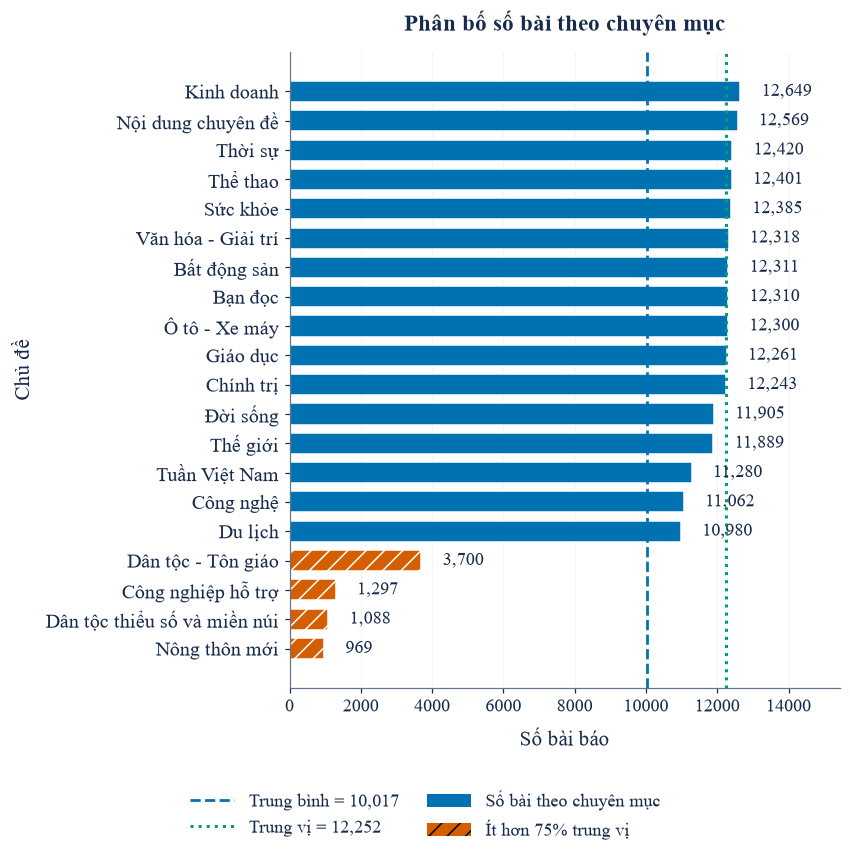

# Lưu kết quả: Xuất hình: class distribution
  Nhiều nhất : Kinh doanh                            12,649
  Ít nhất    : Nông thôn mới                            969
  Imbalance  : 13.05x


In [11]:
# Phân bố class
_vc = df_raw["label"].value_counts().sort_values(ascending=False)
_total = int(_vc.sum())
_mean = float(_vc.mean())
_median = float(_vc.median())
_warn_thr = _median * 0.75

_colors = [
    CHART_COLORS["comparison"] if v < _warn_thr else CHART_COLORS["primary"]
    for v in _vc.values
]

fig, ax = plt.subplots(figsize=(8, 8))
_bars = ax.barh(_vc.index, _vc.to_numpy(), color=_colors, edgecolor="white", height=0.72)
ax.invert_yaxis()

if len(_vc) <= 25:
    for bar, n in zip(_bars, _vc.values):
        ax.text(
            bar.get_width() + _total * 0.003,
            bar.get_y() + bar.get_height() / 2,
            f"{n:,}",
            va="center",
            fontsize=12,
        )

ax.axvline(
    _mean,
    color=CHART_COLORS["primary"],
    ls="--",
    lw=1.8,
    label=f"Trung bình = {_mean:,.0f}",
)
ax.axvline(
    _median,
    color=CHART_COLORS["positive"],
    ls=":",
    lw=2.0,
    label=f"Trung vị = {_median:,.0f}",
)
ax.set_xlim(0, _vc.max() * 1.22)
ax.set_xlabel("Số bài báo")
ax.set_ylabel("Chủ đề")
ax.set_title("Phân bố số bài theo chuyên mục", fontweight="bold")
ax.grid(axis="x", alpha=0.25)
from matplotlib.patches import Patch

_handles, _labels = ax.get_legend_handles_labels()
_handles.extend(
    [
        Patch(facecolor=CHART_COLORS["primary"]),
        Patch(facecolor=CHART_COLORS["comparison"], hatch="//"),
    ]
)
_labels.extend(["Số bài theo chuyên mục", "Ít hơn 75% trung vị"])
for bar, value in zip(_bars, _vc.values):
    if value < _warn_thr:
        bar.set_hatch("//")
ax.legend(_handles, _labels)
fig.tight_layout()
save_fig(fig, "dataset/class_distribution")

_ir = _vc.max() / _vc.min()
print(f"  Nhiều nhất : {_vc.idxmax():<35} {_vc.max():>8,}")
print(f"  Ít nhất    : {_vc.idxmin():<35} {_vc.min():>8,}")
print(f"  Imbalance  : {_ir:.2f}x")

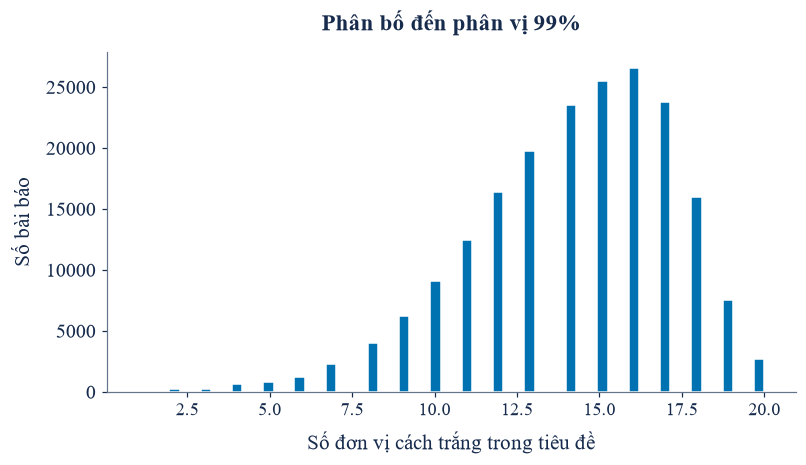

# Lưu kết quả: Xuất hình: title length
count    200337.000000
mean         14.259732
std           3.152651
min           1.000000
50%          15.000000
90%          18.000000
95%          19.000000
99%          20.000000
max          50.000000
Name: title, dtype: float64


In [12]:
lengths = df_raw["title"].str.split().map(len)
cap = lengths.quantile(0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(
    lengths[lengths <= cap], bins=60, color=CHART_COLORS["primary"], edgecolor="white"
)
ax.set(
    xlabel="Số đơn vị cách trắng trong tiêu đề",
    ylabel="Số bài báo",
    title="Phân bố đến phân vị 99%",
)
save_fig(fig, "dataset/title_length")
print(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

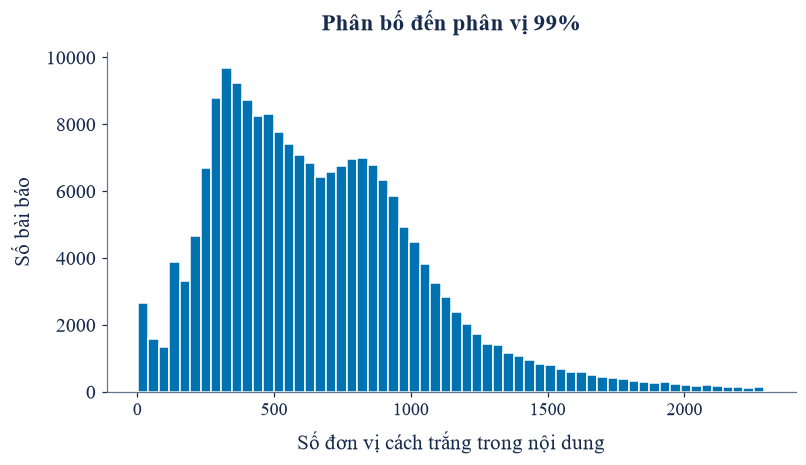

# Lưu kết quả: Xuất hình: content word length
count    200337.000000
mean        693.276898
std         486.113908
min           2.000000
50%         617.000000
90%        1181.000000
95%        1450.000000
99%        2292.000000
max       28147.000000
Name: content, dtype: float64


In [13]:
lengths = df_raw["content"].str.split().map(len)
cap = lengths.quantile(0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(
    lengths[lengths <= cap], bins=60, color=CHART_COLORS["primary"], edgecolor="white"
)
ax.set(
    xlabel="Số đơn vị cách trắng trong nội dung",
    ylabel="Số bài báo",
    title="Phân bố đến phân vị 99%",
)
save_fig(fig, "dataset/content_word_length")
print(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

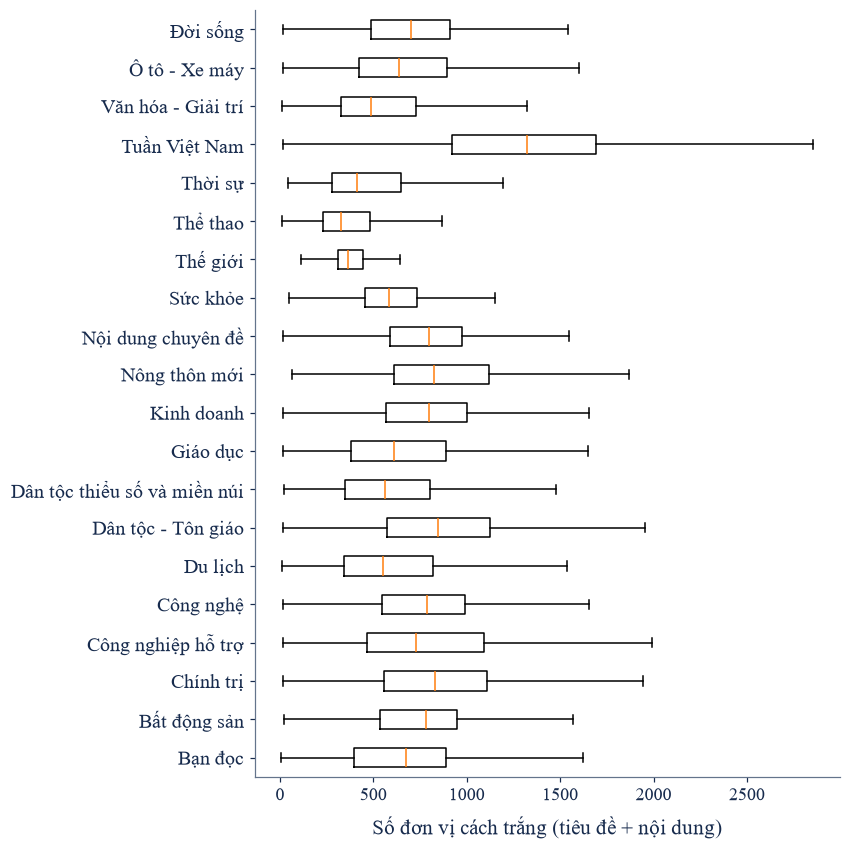

# Lưu kết quả: Xuất hình: length by class


In [14]:
fig, ax = plt.subplots(figsize=(8, 8))
order = sorted(df_raw.label.unique())
boxplot = cast(Callable[..., Any], ax.boxplot)
boxplot(
    [df_raw.loc[df_raw.label == c, "text_len"].to_numpy() for c in order],
    tick_labels=order,
    orientation="horizontal",
    showfliers=False,
)
ax.set(xlabel="Số đơn vị cách trắng (tiêu đề + nội dung)")
save_fig(fig, "dataset/length_by_class")

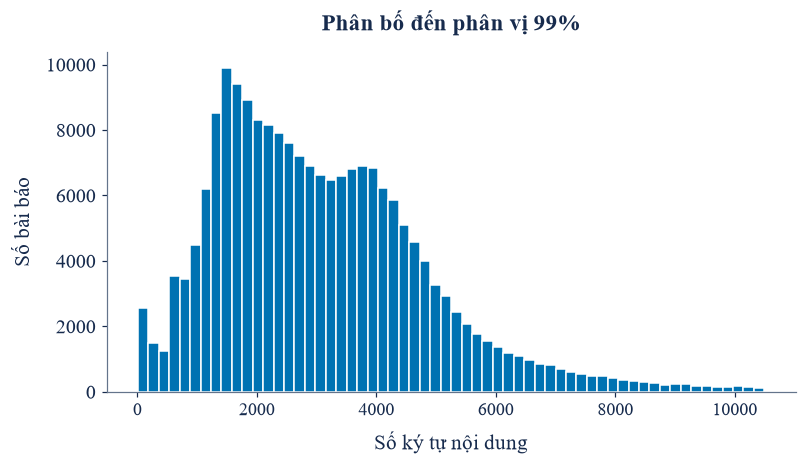

# Lưu kết quả: Xuất hình: content length


In [15]:
lengths = df_raw.content.str.len()
cap = lengths.quantile(0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(
    lengths[lengths <= cap], bins=60, color=CHART_COLORS["primary"], edgecolor="white"
)
ax.set(xlabel="Số ký tự nội dung", ylabel="Số bài báo", title="Phân bố đến phân vị 99%")
save_fig(fig, "dataset/content_length")

In [16]:
_rows = []
for _cls in sorted(df_raw["label"].unique()):
    _sub = df_raw.loc[df_raw["label"] == _cls, "text_len"]
    _rows.append(
        {
            "Chủ đề": _cls,
            "Số bài": len(_sub),
            "Tỷ lệ %": round(len(_sub) / len(df_raw) * 100, 2),
            "TB từ": round(_sub.mean(), 0),
            "Median từ": round(float(np.median(_sub)), 0),
            "Max từ": int(np.asarray(_sub).max()),
        }
    )
_df_sum = (
    pd.DataFrame(_rows).sort_values("Số bài", ascending=False).reset_index(drop=True)
)
_df_sum.index += 1
print("BẢNG TỔNG HỢP DỮ LIỆU\n")
display(
    _df_sum.style.background_gradient(subset=["Số bài"], cmap="Blues")
    .background_gradient(subset=["TB từ"], cmap="Greens")
    .format(
        {
            "Số bài": "{:,}",
            "Tỷ lệ %": "{:.2f}%",
            "TB từ": "{:.0f}",
            "Median từ": "{:.0f}",
        }
    )
)

BẢNG TỔNG HỢP DỮ LIỆU



,Chủ đề,Số bài,Tỷ lệ %,TB từ,Median từ,Max từ
1,Kinh doanh,"12,649",6.31%,803,796,4322
2,Nội dung chuyên đề,"12,569",6.27%,817,799,13656
3,Thời sự,"12,420",6.20%,497,412,11821
4,Thể thao,"12,401",6.19%,387,325,2907
5,Sức khỏe,"12,385",6.18%,615,582,3350
6,Văn hóa - Giải trí,"12,318",6.15%,557,487,5786
7,Bất động sản,"12,311",6.15%,755,780,2817
8,Bạn đọc,"12,310",6.14%,690,675,11363
9,Ô tô - Xe máy,"12,300",6.14%,684,637,5081
10,Giáo dục,"12,261",6.12%,659,608,5218


## Tiền xử lý văn bản

Ghép tiêu đề và nội dung, chuyển chữ thường, thay dấu câu và chữ số,
phân đoạn bằng PyVi rồi chuẩn hóa khoảng trắng. Không loại stopwords.
Mỗi tiến trình xử lý có tokenizer riêng; dữ liệu đã xử lý được lưu để tái sử dụng.


In [17]:
# Tokenize + lưu cache
_processed_sig = Path(TEMP_DIR) / "processed_signature.json"
_cache_valid = (
    _processed_sig.exists()
    and json.loads(_processed_sig.read_text(encoding="utf-8")).get("signature")
    == RAW_SIGNATURE
)
if os.path.exists(PROCESSED_DATA_PATH) and _cache_valid:
    log("Dữ liệu tiền xử lý hợp lệ, sẵn sàng mã hóa.", "OK")
else:
    log("Bắt đầu tiền xử lý văn bản...")

    _df_proc = pd.DataFrame({"label": df_raw["label"]})
    _df_proc["article_index"] = np.arange(len(df_raw))
    _df_proc["full_text"] = df_raw["title"] + " " + df_raw["content"]
    _df_proc = _df_proc.loc[_df_proc["full_text"].str.strip() != ""].reset_index(drop=True)
    log(f"Văn bản hợp lệ: {len(_df_proc):,}", "OK")

    from concurrent.futures import ProcessPoolExecutor
    from pyvi import ViTokenizer

    def prepare_for_segmentation(text):
        # Regex Python giữ nguyên các chữ cái Unicode của tiếng Việt.
        text = re.sub(r"[^\w\s]", " ", text.lower())
        return re.sub(r"\d+", " ", text)

    prepared_texts = _df_proc["full_text"].map(prepare_for_segmentation).tolist()
    map_options = (
        {"buffersize": PREPROCESS_WORKERS * 2} if sys.version_info >= (3, 14) else {}
    )
    log(f"Phân đoạn {len(prepared_texts):,} bài bằng {PREPROCESS_WORKERS} tiến trình.")
    with ProcessPoolExecutor(max_workers=PREPROCESS_WORKERS) as pool:
        segmented_texts = pool.map(
            ViTokenizer.tokenize, prepared_texts, chunksize=64, **map_options
        )
        _df_proc["clean_text"] = [
            re.sub(r"\s+", " ", text).strip()
            for text in TextProgress(
                segmented_texts,
                total=len(prepared_texts),
                desc="Phân đoạn từ tiếng Việt",
            )
        ]
    del prepared_texts, segmented_texts
    _df_proc = _df_proc.loc[_df_proc["clean_text"].str.strip() != ""].reset_index(drop=True)
    log(f"Sau tokenization: {len(_df_proc):,} bài", "OK")

    _classes = sorted(_df_proc["label"].unique().tolist())
    _label2id = {l: i for i, l in enumerate(_classes)}
    _id2label = {i: l for l, i in _label2id.items()}
    _df_proc["label_id"] = _df_proc["label"].map(_label2id)

    with timer("Lưu dữ liệu tiền xử lý"):
        with open(PROCESSED_DATA_PATH, "wb") as _f:
            pickle.dump(
                {"df": _df_proc, "label2id": _label2id, "id2label": _id2label}, _f
            )
    log(f"Đã lưu ({os.path.getsize(PROCESSED_DATA_PATH) / 1e6:.1f} MB)", "SAVE")
    _atomic_json(_processed_sig, {"signature": RAW_SIGNATURE})
if "_df_proc" in globals():
    del _df_proc

# Thông tin: Bắt đầu tiền xử lý văn bản...
# Hoàn tất: Văn bản hợp lệ: 200,337
# Thông tin: Phân đoạn 200,337 bài bằng 4 tiến trình.


# Phân đoạn từ tiếng Việt: [########################] 200,337/200,337 (100.0%) | 362 giây | 554.1 mục/giây

# Hoàn tất: Sau tokenization: 200,337 bài
# Hoàn tất: Lưu dữ liệu tiền xử lý: 1.7 giây
# Lưu kết quả: Đã lưu (1694.9 MB)


In [18]:
# Load processed data
with timer("Nạp dữ liệu tiền xử lý"):
    with open(PROCESSED_DATA_PATH, "rb") as f:
        _s = pickle.load(f)

df = _s["df"].copy()
_ambiguous = df.groupby("clean_text")["label"].transform("nunique") > 1
_removed_ambiguous = int(_ambiguous.sum())
df = df.loc[~_ambiguous]
_before_dedup = len(df)
df = df.drop_duplicates("clean_text").reset_index(drop=True)
log(
    f"Văn bản xung đột nhãn: {_removed_ambiguous:,}; bài trùng cùng nhãn: {_before_dedup - len(df):,}."
)
if df.label.value_counts().min() < 7:
    raise ValueError("Mỗi chuyên mục cần ít nhất bảy văn bản khác nhau để chia ba tập.")
label2id = _s["label2id"]
id2label = _s["id2label"]
classes = sorted(df["label"].unique().tolist())
N_CLASSES = len(classes)
assert classes == sorted(LABEL_MAP.values()), "Processed cache không khớp bộ 20 nhãn."
if "article_index" in df.columns:
    df_raw = df_raw.iloc[df.article_index.to_numpy()].reset_index(drop=True)

_vc3 = df["label"].value_counts()
print(f"# Dữ liệu sau tiền xử lý: {len(df):,} bài | {N_CLASSES} chủ đề\n")
print(f"   {'Chủ đề':<38}  {'Bài':>8}  {'%':>5}  TB tokens (ViTokenizer)")
print(f"   {'-' * 62}")
for _cls in classes:
    _n = _vc3.get(_cls, 0)
    _tl = df[df["label"] == _cls]["clean_text"].str.split().map(len).mean()
    print(f"   {_cls:<38}  {_n:>8,}  {_n / len(df) * 100:>4.1f}%  {_tl:>6.0f}")
del _s


# Hoàn tất: Nạp dữ liệu tiền xử lý: 0.5 giây
# Thông tin: Văn bản xung đột nhãn: 8; bài trùng cùng nhãn: 364.
# Dữ liệu sau tiền xử lý: 199,965 bài | 20 chủ đề

   Chủ đề                                       Bài      %  TB tokens (ViTokenizer)
   --------------------------------------------------------------
   Bạn đọc                                   12,119   6.1%     551
   Bất động sản                              12,309   6.2%     550
   Chính trị                                 12,242   6.1%     637
   Công nghiệp hỗ trợ                         1,292   0.6%     552
   Công nghệ                                 11,061   5.5%     582
   Du lịch                                   10,979   5.5%     479
   Dân tộc - Tôn giáo                         3,700   1.9%     664
   Dân tộc thiểu số và miền núi               1,088   0.5%     404
   Giáo dục                                  12,259   6.1%     480
   Kinh doanh                                12,643   6.3%     579
   Nông thôn mới   

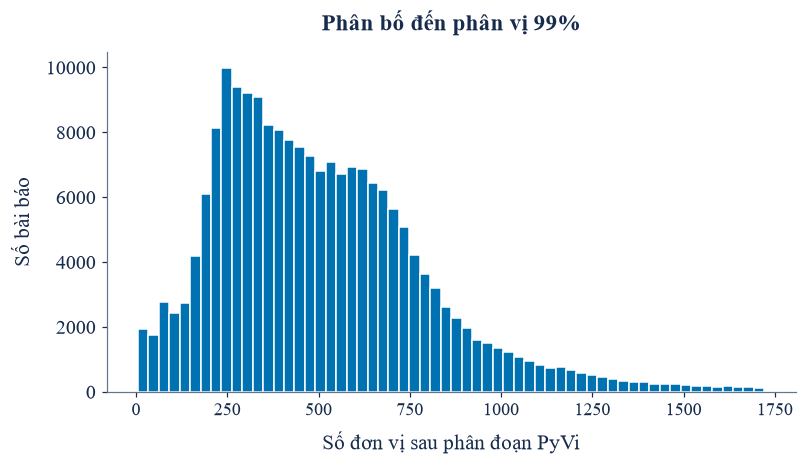

# Lưu kết quả: Xuất hình: clean length


In [19]:
lengths = df.clean_text.str.split().map(len)
cap = lengths.quantile(0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(
    lengths[lengths <= cap], bins=60, color=CHART_COLORS["primary"], edgecolor="white"
)
ax.set(
    xlabel="Số đơn vị sau phân đoạn PyVi",
    ylabel="Số bài báo",
    title="Phân bố đến phân vị 99%",
)
save_fig(fig, "dataset/clean_length")

---
## Tokenize Head-Tail và chia train, validation và test

**Chiến lược Head-Tail**: lấy 127 token đầu và 127 token cuối để tạo tổng 256 token, bao gồm cả `[CLS]` và `[SEP]`.
Cách làm này phù hợp với bài báo dài vì vẫn giữ được thông tin ở cả phần mở đầu lẫn phần kết.

Chia phân tầng 70/15/15 sau khi loại văn bản trùng; ba tập không giao nhau theo URL hoặc văn bản sạch.


In [20]:
class HeadTailDataset(TorchDataset):
    """Head+Tail: 127 token đầu + 127 token cuối (+ [CLS] + [SEP] = 256)."""

    def __init__(self, texts, labels, tokenizer, label2id):
        self.labels = [label2id[l] for l in labels]
        self.input_ids = []
        self.attn_masks = []
        half = (MAX_LENGTH - 2) // 2
        cls_id = tokenizer.cls_token_id
        sep_id = tokenizer.sep_token_id
        pad_id = tokenizer.pad_token_id

        for text in TextProgress(
            texts.tolist(), desc="  Mã hóa Head–Tail", ncols=80, leave=True
        ):
            tokens = tokenizer.encode(text, add_special_tokens=False, truncation=False)
            if len(tokens) <= MAX_LENGTH - 2:
                enc = tokenizer(
                    text, truncation=True, padding="max_length", max_length=MAX_LENGTH
                )
                ids = enc["input_ids"]
                attn = enc["attention_mask"]
            else:
                head = tokens[:half]
                tail = tokens[-half:]
                ids = [cls_id] + head + tail + [sep_id]
                attn = [1] * len(ids)
                pad_n = MAX_LENGTH - len(ids)
                ids += [pad_id] * pad_n
                attn += [0] * pad_n
            self.input_ids.append(ids)
            self.attn_masks.append(attn)

        # Chuyển list -> stacked tensors ngay sau tokenize
        # __getitem__ chỉ cần tensor indexing, không tạo tensor mới mỗi sample
        self._to_tensors()

    def _to_tensors(self):
        """Chuyển Python lists -> stacked tensors. Phục vụ truy xuất batch bằng tensor."""
        if isinstance(self.input_ids, list):
            self.input_ids = torch.tensor(self.input_ids, dtype=torch.long)
            self.attn_masks = torch.tensor(self.attn_masks, dtype=torch.long)
            self.labels = torch.tensor(self.labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attn_masks[idx],
            "labels": self.labels[idx],
        }


def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_weighted": f1_score(
            labels, predictions, average="weighted", zero_division=0
        ),
        "f1_macro": f1_score(
            labels,
            predictions,
            average="macro",
            labels=np.arange(N_CLASSES),
            zero_division=0,
        ),
    }


class LocalGPUTrainer(Trainer):
    """Huấn luyện và suy luận trên một GPU NVIDIA."""

    def _wrap_model(self, model, training=True, dataloader=None):
        wrapped = super()._wrap_model(model, training=training, dataloader=dataloader)
        if self.args.n_gpu != 1 or isinstance(wrapped, torch.nn.DataParallel):
            raise RuntimeError("Chọn kernel sử dụng một GPU NVIDIA cho notebook này.")
        if not getattr(self, "_device_reported", False):
            log(f"Model xử lý batch trên {gpu_name}.", "OK")
            self._device_reported = True
        return wrapped


class WeightedTrainer(LocalGPUTrainer):
    """Trainer với weighted cross-entropy để xử lý mất cân bằng class."""

    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = (
            self.class_weights.to(logits.device)
            if self.class_weights is not None
            else None
        )
        loss = torch.nn.functional.cross_entropy(logits.float(), labels, weight=weight)
        return (loss, outputs) if return_outputs else loss


class EpochCallback(TrainerCallback):
    """Ghi tiến độ huấn luyện và chỉ số validation bằng văn bản."""

    def __init__(self, initial_validation_f1=None):
        self.initial_validation_f1 = initial_validation_f1
        self._train_start = None
        self._epoch_start = None
        self._total_steps = None
        self._validation_progress = None

    def on_train_begin(self, args, state, control, **kwargs):
        self._train_start = time.time()
        if self.initial_validation_f1 is not None:
            state.best_metric = self.initial_validation_f1
        self._total_steps = state.max_steps
        self.progress = TextProgress(total=state.max_steps, desc="Huấn luyện PhoBERT")
        log(
            f"Tổng bước: {self._total_steps:,}  |  tối đa {NUM_EPOCHS} epoch  |  "
            f"~{self._total_steps // NUM_EPOCHS:,} bước/epoch",
            "OK",
        )

    def on_step_end(self, args, state, control, **kwargs):
        self.progress.update(state.global_step - self.progress.count)

    def on_train_end(self, args, state, control, **kwargs):
        self.progress.close()
        if state.global_step < state.max_steps:
            log(f"Dừng sớm tại epoch {state.epoch:.2f}; nạp checkpoint tốt nhất.", "OK")
        if state.best_metric is not None:
            log(f"Macro-F1 validation tốt nhất: {state.best_metric:.4f}.", "OK")

    def on_epoch_begin(self, args, state, control, **kwargs):
        self._epoch_start = time.time()
        ep = int(state.epoch) + 1
        elapsed = time.time() - self._train_start if self._train_start else 0
        log(f"{'-' * 50}")
        log(f"Epoch {ep}/{NUM_EPOCHS} — bắt đầu  |  Đã chạy: {elapsed / 60:.1f} phút")
        gpu_status()

    def on_log(self, args, state, control, logs=None, **kwargs):
        if not logs or "loss" not in logs:
            return
        self.progress.update(
            amount=0,
            details=f"Loss {logs['loss']:.4f} | LR {logs.get('learning_rate', 0):.2e}",
            force=True,
        )

    def on_prediction_step(self, args, state, control, **kwargs):
        if self._validation_progress is None:
            import math
            self._validation_progress = TextProgress(
                total=math.ceil(len(val_dataset) / args.eval_batch_size), desc="Kiểm định PhoBERT"
            )
        self._validation_progress.update()

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if self._validation_progress is not None:
            self._validation_progress.close()
            self._validation_progress = None
        if not metrics or self._train_start is None or state.epoch is None:
            return
        acc = metrics.get("eval_accuracy", 0)
        f1_w = metrics.get("eval_f1_weighted", 0)
        f1_m = metrics.get("eval_f1_macro", 0)
        eloss = metrics.get("eval_loss", 0)
        ep_t = time.time() - self._epoch_start if self._epoch_start else 0
        state.log_history.append(
            {
                "epoch": state.epoch,
                "step": state.global_step,
                "epoch_duration_seconds": ep_t,
            }
        )
        total_t = time.time() - self._train_start if self._train_start else 0
        log(
            f"Epoch {state.epoch:.2f} hoàn tất  |  Loss={eloss:.4f}  Accuracy={acc:.4f}  "
            f"F1-w={f1_w:.4f}  F1-m={f1_m:.4f}  "
            f"(epoch {ep_t / 60:.1f}m  /  tổng {total_t / 60:.1f}m)",
            "OK",
        )


print("# Bộ mã hóa Head–Tail và Trainer sẵn sàng.")

class PredictionProgressCallback(TrainerCallback):
    def __init__(self, progress):
        self.progress = progress

    def on_prediction_step(self, args, state, control, **kwargs):
        self.progress.update()


def predict_with_progress(trainer, dataset, description):
    import math
    with TextProgress(total=math.ceil(len(dataset) / trainer.args.eval_batch_size), desc=description) as progress:
        callback = PredictionProgressCallback(progress)
        trainer.add_callback(callback)
        try:
            return trainer.predict(dataset)
        finally:
            trainer.remove_callback(callback)


# Bộ mã hóa Head–Tail và Trainer sẵn sàng.


In [21]:
log("Chia phân tầng train, validation và test.")
if not np.isclose(TRAIN_SIZE + VAL_SIZE + TEST_SIZE, 1.0):
    raise ValueError("Tổng tỷ lệ ba tập phải bằng 1.")
train_indices, holdout_indices = train_test_split(
    np.arange(len(df)),
    test_size=VAL_SIZE + TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df.label,
)
val_indices, test_indices = train_test_split(
    holdout_indices,
    test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    random_state=RANDOM_STATE,
    stratify=df.label.iloc[holdout_indices],
)
split_indices = {
    "train": train_indices,
    "validation": val_indices,
    "test": test_indices,
}
for name, indices in split_indices.items():
    if set(df.label.iloc[indices]) != set(classes):
        raise ValueError(f"Tập {name} thiếu nhãn; cần thu thập thêm dữ liệu.")
assert sorted(np.concatenate(list(split_indices.values())).tolist()) == list(
    range(len(df))
)
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert not set(split_indices[left]) & set(split_indices[right])
    assert not set(df.clean_text.iloc[split_indices[left]]) & set(
        df.clean_text.iloc[split_indices[right]]
    )
    assert not set(df_raw.url.iloc[split_indices[left]]) & set(
        df_raw.url.iloc[split_indices[right]]
    )
X_train_raw, X_val_raw, X_test_raw = [
    df.clean_text.iloc[split_indices[s]] for s in split_indices
]
y_train, y_val, y_test = [df.label.iloc[split_indices[s]] for s in split_indices]
log(
    f"Train: {len(y_train):,} | Validation: {len(y_val):,} | Test: {len(y_test):,}",
    "OK",
)
# Tải tokenizer PhoBERT
log(f"Tải tokenizer: {MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

_sample_text = (
    df["clean_text"].sample(min(1000, len(df)), random_state=RANDOM_STATE).tolist()
)
_tlen = np.array(
    [
        len(tokenizer.encode(t, truncation=False))
        for t in TextProgress(_sample_text, desc="  Khảo sát độ dài token", ncols=80)
    ]
)
log(
    f"Token length - mean={_tlen.mean():.1f} | median={np.median(_tlen):.1f} | "
    f"max={_tlen.max()} | >256: {(_tlen > 256).mean():.1%}",
    "OK",
)

# Tính class weights
log("Tính trọng số class từ tập huấn luyện...")
train_class_counts = np.bincount(y_train.map(label2id).to_numpy(), minlength=N_CLASSES)
if np.any(train_class_counts == 0):
    raise RuntimeError("Tập train thiếu class; chưa thể tính trọng số balanced.")
_cw_vals = len(y_train) / (N_CLASSES * train_class_counts.astype(np.float64))
np.testing.assert_allclose(np.dot(_cw_vals, train_class_counts) / len(y_train), 1.0)
class_weights = torch.tensor(_cw_vals, dtype=torch.float32)
print(f"\n   {'Chủ đề':<38}  {'Trọng số':>10}")
print(f"   {'-' * 60}")
for i, cls in enumerate(classes):
    print(f"   {cls:<38}  {_cw_vals[i]:>10.4f}")


split_manifest = {
    "seed": RANDOM_STATE,
    "requested_ratios": {
        "train": TRAIN_SIZE,
        "validation": VAL_SIZE,
        "test": TEST_SIZE,
    },
    "counts": {s: len(v) for s, v in split_indices.items()},
    "actual_ratios": {s: len(v) / len(df) for s, v in split_indices.items()},
    "indices": {s: np.asarray(v).tolist() for s, v in split_indices.items()},
    "deduplication": "clean_text; conflicting labels removed; identical texts kept once",
    "selection_split": "validation",
    "calibration_fit_split": "validation",
    "evaluation_split": "test",
    "pairwise_disjoint": True,
}
_HT_SIGNATURE = hashlib.sha256(
    json.dumps(
        {
            "raw": RAW_SIGNATURE,
            "split": split_manifest,
            "max_length": MAX_LENGTH,
            "model": MODEL_NAME,
        },
        sort_keys=True,
    ).encode("utf-8")
).hexdigest()
split_manifest["signature"] = _HT_SIGNATURE
_ht_sig = Path(TEMP_DIR) / "headtail_signature.json"
_ht_valid = (
    _ht_sig.exists()
    and json.loads(_ht_sig.read_text(encoding="utf-8")).get("signature")
    == _HT_SIGNATURE
)
datasets = {}
for name, indices in split_indices.items():
    cache = Path(TEMP_DIR) / f"headtail_{name}.pkl"
    if cache.exists() and _ht_valid:
        with cache.open("rb") as stream:
            cached = pickle.load(stream)
        cached._to_tensors()
        np.testing.assert_array_equal(
            cached.labels.numpy(), df.label.iloc[indices].map(label2id)
        )
        assert cached.input_ids.shape == (len(indices), MAX_LENGTH)
        datasets[name] = cached
        log(f"Đã nạp tensor {name}: {len(indices):,} bài.", "OK")
    else:
        log(f"Mã hóa tập {name}: {len(indices):,} bài.")
        datasets[name] = HeadTailDataset(
            df.clean_text.iloc[indices], df.label.iloc[indices], tokenizer, label2id
        )
        with cache.open("wb") as stream:
            pickle.dump(datasets[name], stream)
train_dataset, val_dataset, test_dataset = [datasets[s] for s in split_indices]
_atomic_json(_ht_sig, {"signature": _HT_SIGNATURE})
_atomic_json(Path(TEMP_DIR) / "split_manifest.json", split_manifest)
gpu_status()
# Fingerprint gồm dữ liệu và mọi thiết lập quyết định lượt fine-tune.
training_configuration = {
    "model": MODEL_NAME,
    "split_ratios": [TRAIN_SIZE, VAL_SIZE, TEST_SIZE],
    "learning_rate": LR,
    "per_device_batch_size": BATCH_SIZE,
    "gpu_count": GPU_COUNT,
    "global_batch_size": GLOBAL_BATCH_SIZE,
    "effective_batch_size": EFFECTIVE_BATCH_SIZE,
    "parallelism": "single_gpu",
    "class_weighting": "N_train / (N_classes * train_class_count)",
    "train_class_counts": train_class_counts.tolist(),
    "gradient_accumulation": GRAD_ACCUM,
    "max_epochs": NUM_EPOCHS,
    "weight_decay": WEIGHT_DECAY,
    "warmup_steps": WARMUP_STEPS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_threshold": EARLY_STOPPING_THRESHOLD,
    "selection_metric": "f1_macro",
    "tf32": TF32,
    "bf16": BF16,
    "fp16": FP16,
    "optimizer": "adamw_torch_fused",
    "seed": RANDOM_STATE,
    "class_weights": class_weights.tolist(),
}
TRAINING_SIGNATURE = hashlib.sha256(
    (_HT_SIGNATURE + json.dumps(training_configuration, sort_keys=True)).encode("utf-8")
).hexdigest()

write_json(
    RUN_ROOT / "result/evaluation/class_balance.json",
    {
        "strategy": "balanced_train_frequency",
        "formula": "N_train / (N_classes * n_class)",
        "fit_split": "train",
        "random_sampling": True,
        "imbalance_ratio": float(train_class_counts.max() / train_class_counts.min()),
        "classes": [
            {
                "id": i,
                "label": label,
                "train_count": int(train_class_counts[i]),
                "train_share": float(train_class_counts[i] / len(y_train)),
                "loss_weight": float(_cw_vals[i]),
            }
            for i, label in enumerate(classes)
        ],
    },
)

# Thông tin: Chia phân tầng train, validation và test.
# Hoàn tất: Train: 139,975 | Validation: 29,995 | Test: 29,995
# Thông tin: Tải tokenizer: vinai/phobert-base-v2...


# Khảo sát độ dài token: [########################] 1,000/1,000 (100.0%) | 2 giây | 577.9 mục/giây

# Hoàn tất: Token length - mean=573.0 | median=510.5 | max=2590 | >256: 85.4%
# Thông tin: Tính trọng số class từ tập huấn luyện...

   Chủ đề                                    Trọng số
   ------------------------------------------------------------
   Bạn đọc                                     0.8250
   Bất động sản                                0.8123
   Chính trị                                   0.8168
   Công nghiệp hỗ trợ                          7.7334
   Công nghệ                                   0.9039
   Du lịch                                     0.9107
   Dân tộc - Tôn giáo                          2.7022
   Dân tộc thiểu số và miền núi                9.1847
   Giáo dục                                    0.8156
   Kinh doanh                                  0.7908
   Nông thôn mới                              10.3226
   Nội dung chuyên đề                          0.7955
   Sức khỏe                                    0.8072
   Thế giới                                    

# Mã hóa Head–Tail: [########################] 139,975/139,975 (100.0%) | 191 giây | 733.1 mục/giây

# Thông tin: Mã hóa tập validation: 29,995 bài.


# Mã hóa Head–Tail: [########################] 29,995/29,995 (100.0%) | 40 giây | 752.0 mục/giây

# Thông tin: Mã hóa tập test: 29,995 bài.


# Mã hóa Head–Tail: [########################] 29,995/29,995 (100.0%) | 41 giây | 736.2 mục/giây

# Bộ nhớ GPU: GPU 0: 0.0 GB đã dùng / 0.0 GB dự trữ / 12.0 GB tổng


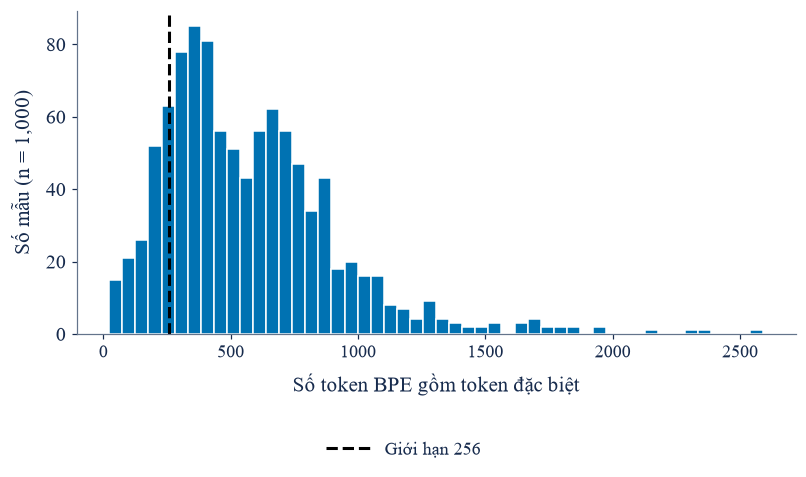

# Lưu kết quả: Xuất hình: token length


In [22]:
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(_tlen, bins=50, color=CHART_COLORS["primary"], edgecolor="white")
ax.axvline(MAX_LENGTH, color="black", ls="--", label="Giới hạn 256")
ax.set(xlabel="Số token BPE gồm token đặc biệt", ylabel=f"Số mẫu (n = {len(_tlen):,})")
ax.legend()
save_fig(fig, "dataset/token_length")

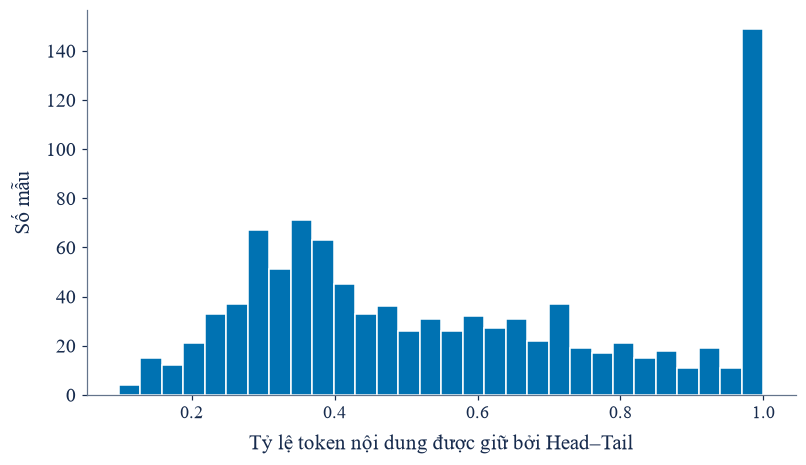

# Lưu kết quả: Xuất hình: token retention


In [23]:
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(
    np.minimum(_tlen - 2, 254) / np.maximum(_tlen - 2, 1),
    bins=30,
    color=CHART_COLORS["primary"],
    edgecolor="white",
)
ax.set(xlabel="Tỷ lệ token nội dung được giữ bởi Head–Tail", ylabel="Số mẫu")
save_fig(fig, "dataset/token_retention")

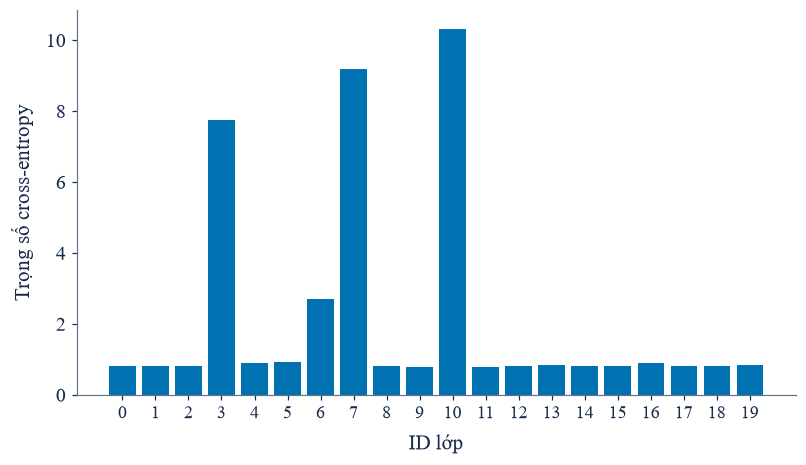

# Lưu kết quả: Xuất hình: class weights


In [24]:
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.bar(range(N_CLASSES), _cw_vals, color=CHART_COLORS["primary"])
ax.set(xticks=range(N_CLASSES), xlabel="ID lớp", ylabel="Trọng số cross-entropy")
save_fig(fig, "training/class_weights")

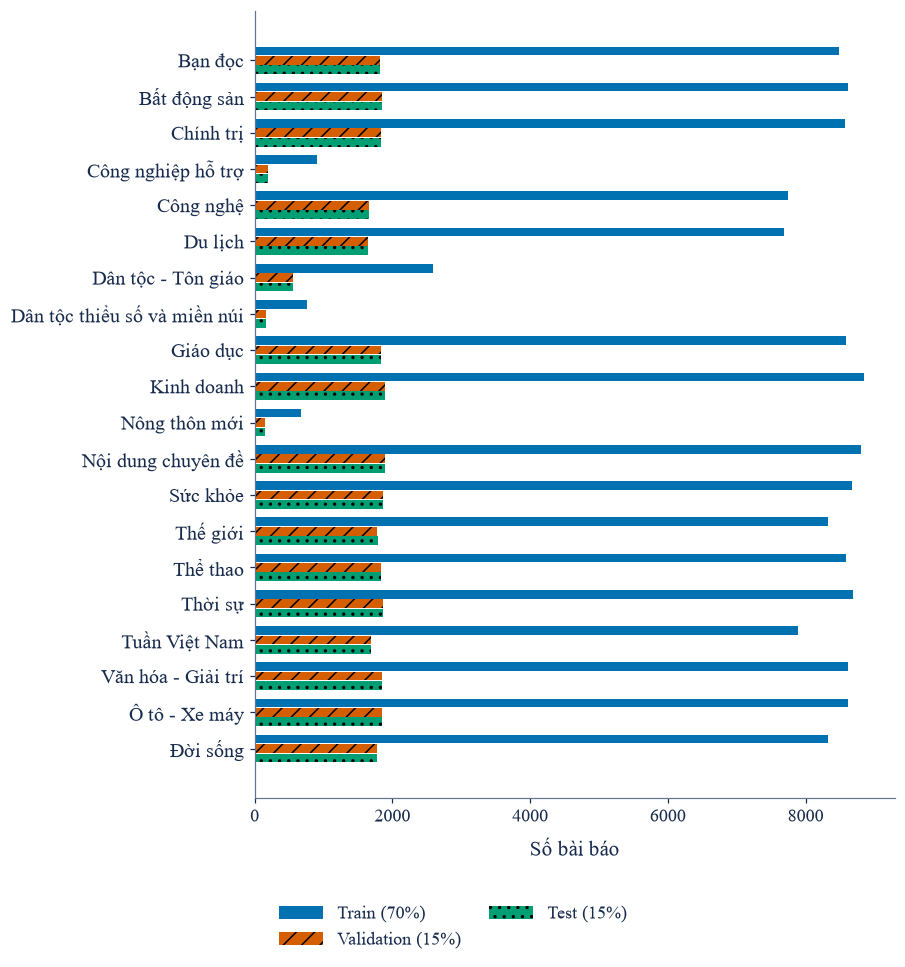

# Lưu kết quả: Xuất hình: split distribution
 ID                         Nhãn
  0                      Bạn đọc
  1                 Bất động sản
  2                    Chính trị
  3           Công nghiệp hỗ trợ
  4                    Công nghệ
  5                      Du lịch
  6           Dân tộc - Tôn giáo
  7 Dân tộc thiểu số và miền núi
  8                     Giáo dục
  9                   Kinh doanh
 10                Nông thôn mới
 11           Nội dung chuyên đề
 12                     Sức khỏe
 13                     Thế giới
 14                     Thể thao
 15                      Thời sự
 16                Tuần Việt Nam
 17           Văn hóa - Giải trí
 18                Ô tô - Xe máy
 19                     Đời sống


In [25]:
fig, ax = plt.subplots(figsize=(8.5, 9))
y = np.arange(N_CLASSES)
for offset, values, name, color, hatch in [
    (-0.26, y_train, "Train (70%)", "primary", ""),
    (0, y_val, "Validation (15%)", "comparison", "//"),
    (0.26, y_test, "Test (15%)", "positive", ".."),
]:
    ax.barh(
        y + offset,
        [int((values == c).sum()) for c in classes],
        0.24,
        label=name,
        color=CHART_COLORS[color],
        hatch=hatch,
    )
ax.set(yticks=y, yticklabels=classes, xlabel="Số bài báo")
ax.invert_yaxis()
ax.legend()
save_fig(fig, "dataset/split_distribution")
print(pd.DataFrame({"ID": range(N_CLASSES), "Nhãn": classes}).to_string(index=False))

## Huấn luyện mô hình

PhoBERT-base-v2 được fine-tune với weighted cross-entropy; trọng số class tính từ tập train.

| Thiết lập | Giá trị |
|---|---|
| Learning rate | 0,00002 |
| Batch / tích lũy gradient | 32 / 2, effective batch 64 |
| Số epoch tối đa | 7 |
| Early stopping | Macro-F1, patience 2, cải thiện tối thiểu 0,001 |
| Warmup | 200 bước cập nhật |
| Kiểm định và lưu checkpoint | Mỗi epoch |
| Checkpoint dùng đánh giá | Macro-F1 tốt nhất |
| Precision | BF16 trên RTX A3000; FP16 nếu GPU không hỗ trợ BF16 |

Mô hình chỉ được nạp để train tiếp khi dữ liệu, tiền xử lý, mapping và toàn bộ ba tập khớp fingerprint.
Mỗi lượt khởi tạo optimizer/scheduler mới và chạy tối đa 7 epoch. Validation đầu vào
là mốc so sánh; giữ mô hình đầu vào nếu lượt mới không cải thiện Macro-F1.
Test không tham gia chọn checkpoint hoặc hiệu chỉnh tham số.

Trọng số `N_train / (20 × n_class)` cân bằng đóng góp kỳ vọng của các lớp trong loss.
Số lượng được tính lại sau tiền xử lý, loại trùng và chia tập; không dùng số đếm hard-code.
Sampler ngẫu nhiên giữ phân bố thật; validation/test không được cân bằng lại.
Temperature và hệ số quyết định chỉ được fit trên validation.


In [26]:
# Nạp trọng số tương thích hoặc khởi tạo từ backbone.
_previous_history = {}
_MODEL_READY = all(
    (Path(MODEL_DIR) / n).is_file()
    for n in ["config.json", "model.safetensors", "train_history.pkl"]
)
if _MODEL_READY and TRAINING_MODE != "fresh":
    try:
        with open(TRAIN_HISTORY_PATH, "rb") as stream:
            _previous_history = pickle.load(stream)
        _saved_config = json.loads(
            (Path(MODEL_DIR) / "config.json").read_text(encoding="utf-8")
        )
        _MODEL_READY = (
            _previous_history.get("dataset_signature") == _HT_SIGNATURE
            and _previous_history.get("split_signature") == _HT_SIGNATURE
            and _saved_config.get("label2id") == label2id
            and _previous_history.get("classes") == classes
        )
    except (OSError, ValueError, EOFError, pickle.UnpicklingError):
        _MODEL_READY = False
if TRAINING_MODE == "evaluate" and not _MODEL_READY:
    raise ValueError(
        "Chế độ evaluate cần mô hình tương thích dữ liệu, mapping và ba tập."
    )

if TRAINING_MODE == "evaluate":
    log("Mô hình tương thích; thực hiện đánh giá.", "OK")
else:
    torch.cuda.empty_cache()
    set_seed(RANDOM_STATE)
    _load_weights = TRAINING_MODE == "continue" and _MODEL_READY
    _source = MODEL_DIR if _load_weights else MODEL_NAME
    log(
        "Nạp trọng số để train tiếp."
        if _load_weights
        else "Khởi tạo PhoBERT từ backbone."
    )
    model_train, load_info = AutoModelForSequenceClassification.from_pretrained(
        _source,
        num_labels=N_CLASSES,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=not _load_weights,
        key_mapping={
            r"LayerNorm\.gamma": "LayerNorm.weight",
            r"LayerNorm\.beta": "LayerNorm.bias",
        },
        output_loading_info=True,
    )
    bad_missing = [
        k for k in load_info.get("missing_keys", []) if not k.startswith("classifier.")
    ]
    bad_unexpected = [
        k
        for k in load_info.get("unexpected_keys", [])
        if not k.startswith(("lm_head.", "roberta.pooler."))
    ]
    if (
        bad_missing
        or bad_unexpected
        or (_load_weights and load_info.get("missing_keys"))
    ):
        raise RuntimeError(f"Mô hình không nạp đầy đủ: {bad_missing}, {bad_unexpected}")
    model_train = model_train.to(device)
    _run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    _CKPT_DIR = str(Path(TEMP_DIR) / "checkpoints" / _run_id)
    training_args = TrainingArguments(
        output_dir=_CKPT_DIR,
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH,
        gradient_accumulation_steps=GRAD_ACCUM,
        learning_rate=LR,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=WARMUP_STEPS,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        tf32=TF32,
        bf16=BF16,
        fp16=FP16,
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
        max_steps=-1,
        logging_steps=100,
        logging_first_step=True,
        disable_tqdm=True,
        save_total_limit=1,
        report_to="none",
        dataloader_num_workers=0,
        dataloader_pin_memory=True,
        gradient_checkpointing=False,
        optim="adamw_torch_fused",
        torch_compile=False,
    )
    if (
        training_args.n_gpu != GPU_COUNT
        or training_args.train_batch_size != GLOBAL_BATCH_SIZE
    ):
        raise RuntimeError("TrainingArguments không khớp GPU và batch đã cấu hình.")
    for gpu_id in range(GPU_COUNT):
        torch.cuda.reset_peak_memory_stats(gpu_id)
    _epoch_callback = EpochCallback()
    trainer = WeightedTrainer(
        model=model_train,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics,
        class_weights=class_weights,
        callbacks=[_epoch_callback],
    )
    trainer.remove_callback(PrinterCallback)
    _initial_f1 = None
    if _load_weights:
        _initial_f1 = float(trainer.evaluate()["eval_f1_macro"])
        _epoch_callback.initial_validation_f1 = _initial_f1
        log(f"Macro-F1 validation của trọng số đầu vào: {_initial_f1:.4f}.", "OK")
    trainer.add_callback(
        EarlyStoppingCallback(
            early_stopping_patience=EARLY_STOPPING_PATIENCE,
            early_stopping_threshold=EARLY_STOPPING_THRESHOLD,
        )
    )
    log("Bắt đầu fine-tuning với optimizer và scheduler mới.")
    _t_start = time.time()
    trainer.train(resume_from_checkpoint=False)
    _train_time = time.time() - _t_start
    gpu_peaks = [torch.cuda.max_memory_allocated(i) for i in range(GPU_COUNT)]
    if any(value == 0 for value in gpu_peaks):
        raise RuntimeError("Có GPU không tham gia huấn luyện.")
    write_json(
        RUN_ROOT / "result/evaluation/gpu_execution.json",
        {
            "parallelism": "single_gpu",
            "device_ids": [GPU_INDEX],
            "per_device_batch_size": BATCH_SIZE,
            "global_batch_size": GLOBAL_BATCH_SIZE,
            "effective_batch_size": EFFECTIVE_BATCH_SIZE,
            "peak_allocated_gib": [value / 1024**3 for value in gpu_peaks],
            "precision": "BF16" if BF16 else "FP16",
        },
    )
    if trainer.state.best_metric is None:
        raise RuntimeError("Huấn luyện chưa có chỉ số validation để chọn model.")
    _selected_f1 = float(trainer.state.best_metric)
    _kept_initial = _load_weights and _initial_f1 is not None and _selected_f1 <= _initial_f1
    if _kept_initial:
        log("Validation không cải thiện; giữ trọng số đầu vào.", "OK")
    else:
        trainer.save_model(MODEL_DIR)
        tokenizer.save_pretrained(MODEL_DIR)
        log("Đã lưu trọng số tốt nhất theo validation.", "SAVE")
    _old = _previous_history if _load_weights else {}
    _epoch_offset = float(_old.get("completed_epochs", 0))
    _step_offset = int(_old.get("optimizer_steps", 0))
    _new_logs = []
    for record in trainer.state.log_history:
        item: dict[str, Any] = dict(record)
        item["run_id"] = _run_id
        if item.get("epoch") is not None:
            item["epoch"] += _epoch_offset
        if item.get("step") is not None:
            item["step"] += _step_offset
        _new_logs.append(item)
    _run_record = {
        "run_id": _run_id,
        "loaded_weights": _load_weights,
        "initial_validation_macro_f1": _initial_f1,
        "selected_validation_macro_f1": _selected_f1,
        "kept_initial_weights": bool(_kept_initial),
        "completed_epochs": float(trainer.state.epoch or 0),
        "optimizer_steps": trainer.state.global_step,
        "train_time_sec": _train_time,
        "optimizer_state_restored": False,
        "configuration": training_configuration,
        "stopped_early": trainer.state.global_step < trainer.state.max_steps,
    }
    _history = {
        "log_history": _old.get("log_history", []) + _new_logs,
        "training_runs": _old.get("training_runs", []) + [_run_record],
        "train_time_sec": _old.get("train_time_sec", 0) + _train_time,
        "dataset_signature": _HT_SIGNATURE,
        "split_signature": _HT_SIGNATURE,
        "training_signature": TRAINING_SIGNATURE,
        "training_configuration": training_configuration,
        "completed_epochs": _epoch_offset + float(trainer.state.epoch or 0),
        "optimizer_steps": _step_offset + trainer.state.global_step,
        "best_validation_macro_f1": _initial_f1 if _kept_initial else _selected_f1,
        "stopped_early": _run_record["stopped_early"],
        "classes": classes,
    }
    _history_temp = Path(TRAIN_HISTORY_PATH).with_suffix(".partial")
    with _history_temp.open("wb") as stream:
        pickle.dump(_history, stream)
    os.replace(_history_temp, TRAIN_HISTORY_PATH)
    log(f"Huấn luyện hoàn tất: {_train_time / 60:.1f} phút.", "OK")
    shutil.rmtree(_CKPT_DIR)
    if not any((Path(TEMP_DIR) / "checkpoints").iterdir()):
        (Path(TEMP_DIR) / "checkpoints").rmdir()
    del model_train, trainer
    torch.cuda.empty_cache()

# Thông tin: Khởi tạo PhoBERT từ backbone.
# Thông tin: Bắt đầu fine-tuning với optimizer và scheduler mới.
# Hoàn tất: Model xử lý batch trên NVIDIA RTX A3000 12GB Laptop GPU.


# Huấn luyện PhoBERT: [########################] 15,316/15,316 (100.0%) | 12430 giây | 1.2 mục/giây | Loss 0.0801 | LR 2.25e-08

# Hoàn tất: Tổng bước: 15,316  |  tối đa 7 epoch  |  ~2,188 bước/epoch
# Thông tin: --------------------------------------------------
# Thông tin: Epoch 1/7 — bắt đầu  |  Đã chạy: 0.0 phút
# Bộ nhớ GPU: GPU 0: 0.5 GB đã dùng / 0.6 GB dự trữ / 12.0 GB tổng


# Kiểm định PhoBERT: [########################] 469/469 (100.0%) | 108 giây | 4.4 mục/giây

# Hoàn tất: Epoch 1.00 hoàn tất  |  Loss=0.4034  Accuracy=0.8819  F1-w=0.8832  F1-m=0.8343  (epoch 30.4m  /  tổng 30.4m)
# Thông tin: --------------------------------------------------
# Thông tin: Epoch 2/7 — bắt đầu  |  Đã chạy: 30.4 phút
# Bộ nhớ GPU: GPU 0: 1.5 GB đã dùng / 5.7 GB dự trữ / 12.0 GB tổng


...

# Hoàn tất: Epoch 5.00 hoàn tất  |  Loss=0.4257  Accuracy=0.9097  F1-w=0.9104  F1-m=0.8718  (epoch 29.8m  /  tổng 148.4m)
# Thông tin: --------------------------------------------------
# Thông tin: Epoch 6/7 — bắt đầu  |  Đã chạy: 148.5 phút
# Bộ nhớ GPU: GPU 0: 1.5 GB đã dùng / 5.7 GB dự trữ / 12.0 GB tổng


# Kiểm định PhoBERT: [########################] 469/469 (100.0%) | 106 giây | 4.4 mục/giây

# Hoàn tất: Epoch 6.00 hoàn tất  |  Loss=0.4592  Accuracy=0.9113  F1-w=0.9119  F1-m=0.8708  (epoch 29.6m  /  tổng 178.0m)
# Thông tin: --------------------------------------------------
# Thông tin: Epoch 7/7 — bắt đầu  |  Đã chạy: 178.1 phút
# Bộ nhớ GPU: GPU 0: 1.5 GB đã dùng / 5.7 GB dự trữ / 12.0 GB tổng


# Kiểm định PhoBERT: [########################] 469/469 (100.0%) | 106 giây | 4.4 mục/giây

# Hoàn tất: Epoch 7.00 hoàn tất  |  Loss=0.4980  Accuracy=0.9126  F1-w=0.9130  F1-m=0.8723  (epoch 29.1m  /  tổng 207.1m)
# Hoàn tất: Macro-F1 validation tốt nhất: 0.8723.
# Lưu kết quả: Đã lưu trọng số tốt nhất theo validation.
# Hoàn tất: Huấn luyện hoàn tất: 207.2 phút.


In [27]:
# Load model + dự đoán tập test
log("Nạp mô hình để đánh giá.")
model_eval = AutoModelForSequenceClassification.from_pretrained(
    MODEL_DIR,
    num_labels=N_CLASSES,
    id2label=id2label,
    label2id=label2id,
).to(device)
model_eval.eval()


_eval_args = TrainingArguments(
    output_dir=TEMP_DIR,
    per_device_eval_batch_size=EVAL_BATCH,
    tf32=TF32,
    bf16=BF16,
    fp16=FP16,
    report_to="none",
    disable_tqdm=True,
    dataloader_num_workers=0,
    dataloader_pin_memory=True,
)
_eval_trainer = LocalGPUTrainer(
    model=model_eval,
    args=_eval_args,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

_eval_trainer.remove_callback(PrinterCallback)

from scipy.optimize import minimize_scalar, OptimizeResult



def fit_calibration(logits, labels):
    logits = np.asarray(logits)
    labels = np.asarray(labels, dtype=int)

    def nll(temperature):
        p = temperature_probabilities(logits, temperature)
        return float(-np.log(p[np.arange(len(labels)), labels] + 1e-10).mean())

    result = cast(OptimizeResult, minimize_scalar(nll, bounds=(0.5, 5.0), method="bounded"))
    # T=1 is a candidate, so calibration never increases validation NLL.
    temperature = (
        float(result.x) if result.success and nll(result.x) < nll(1.0) else 1.0
    )
    p = temperature_probabilities(logits, temperature)
    factors = np.ones(N_CLASSES)
    grid = np.linspace(0.3, 3.5, 200)
    support = np.bincount(labels, minlength=N_CLASSES)

    def macro_f1(pred):
        predicted = np.bincount(pred, minlength=N_CLASSES)
        true_positive = np.bincount(labels[labels == pred], minlength=N_CLASSES)
        return float(np.mean(2 * true_positive / np.maximum(support + predicted, 1)))

    current_f1 = macro_f1(p.argmax(1))
    progress = TextProgress(total=3 * N_CLASSES, desc="Hiệu chỉnh trên validation")
    for _ in range(3):
        for label_id in range(N_CLASSES):
            scores = p / factors
            scores[:, label_id] = -np.inf
            other_ids = scores.argmax(1)
            other_scores = scores[np.arange(len(labels)), other_ids]
            best_factor = factors[label_id]
            best_f1 = current_f1
            for factor in grid:
                own_score = p[:, label_id] / factor
                chosen = (own_score > other_scores) | (
                    (own_score == other_scores) & (label_id < other_ids)
                )
                pred = np.where(chosen, label_id, other_ids)
                candidate_f1 = macro_f1(pred)
                if candidate_f1 > best_f1 + 1e-5:
                    best_f1, best_factor = candidate_f1, float(factor)
            factors[label_id] = best_factor
            current_f1 = best_f1
            progress.update()
    progress.close()
    return temperature, factors


log("Dự đoán validation để hiệu chỉnh xác suất và hệ số quyết định.")
_validation = predict_with_progress(_eval_trainer, val_dataset, "Dự đoán validation")
validation_logits = np.asarray(_validation.predictions)
validation_labels = df.label.iloc[val_indices].map(label2id).to_numpy()
T_OPTIMAL, thresholds = fit_calibration(validation_logits, validation_labels)
validation_metrics = {}
for name, prediction in [
    ("before", validation_logits.argmax(1)),
    (
        "after",
        (temperature_probabilities(validation_logits, T_OPTIMAL) / thresholds).argmax(
            1
        ),
    ),
]:
    validation_metrics[name] = compute_metrics(
        (np.eye(N_CLASSES)[prediction], validation_labels)
    )
log("Tham số hiệu chỉnh đã cố định; đánh giá trên test độc lập.")
_inference_start = time.perf_counter()
with timer("Dự đoán test"):
    _raw = predict_with_progress(_eval_trainer, test_dataset, "Dự đoán test")
inference_seconds = time.perf_counter() - _inference_start
raw_logits = np.asarray(_raw.predictions)
y_true_ids = df.label.iloc[test_indices].map(label2id).tolist()
y_pred_ids = raw_logits.argmax(1).tolist()
model_acc = accuracy_score(y_true_ids, y_pred_ids)
model_f1w = f1_score(y_true_ids, y_pred_ids, average="weighted", zero_division=0)
model_f1m = f1_score(
    y_true_ids, y_pred_ids, average="macro", labels=range(N_CLASSES), zero_division=0
)
f1_per_class = dict(
    zip(
        classes,
        f1_score(
            y_true_ids,
            y_pred_ids,
            labels=range(N_CLASSES),
            average=None,
            zero_division=0,
        ),
    )
)
with open(TRAIN_HISTORY_PATH, "rb") as stream:
    _hist = pickle.load(stream)
log_history = _hist.get("log_history", [])
train_time_sec = _hist.get("train_time_sec", 0)
print(
    f"# Test độc lập: {len(y_true_ids):,} bài; Accuracy {model_acc:.4f}; Macro-F1 {model_f1m:.4f}."
)
gpu_status()

# Thông tin: Nạp mô hình để đánh giá.
# Thông tin: Dự đoán validation để hiệu chỉnh xác suất và hệ số quyết định.


# Dự đoán validation: [########################] 469/469 (100.0%) | 106 giây | 4.4 mục/giây

# Hoàn tất: Model xử lý batch trên NVIDIA RTX A3000 12GB Laptop GPU.


# Hiệu chỉnh trên validation: [########################] 60/60 (100.0%) | 4 giây | 16.5 mục/giây

# Thông tin: Tham số hiệu chỉnh đã cố định; đánh giá trên test độc lập.


# Dự đoán test: [########################] 469/469 (100.0%) | 106 giây | 4.4 mục/giây

# Hoàn tất: Dự đoán test: 106.3 giây
# Test độc lập: 29,995 bài; Accuracy 0.9108; Macro-F1 0.8722.
# Bộ nhớ GPU: GPU 0: 1.0 GB đã dùng / 1.7 GB dự trữ / 12.0 GB tổng


---
## Đánh giá mô hình

Tạo báo cáo phân loại, ma trận nhầm lẫn, biểu đồ F1 theo từng chủ đề và đường cong huấn luyện.


In [28]:
# Báo cáo phân loại
_report_str = classification_report(
    y_true_ids, y_pred_ids, target_names=classes, digits=4, zero_division=0
)

print(f"{'=' * 65}")
print(f"  BÁO CÁO PHÂN LOẠI - PhoBERT Base v2 Head-Tail")
print(f"  {'-' * 62}")
print(f"  Accuracy   : {model_acc:.4f}")
print(f"  F1-weighted: {model_f1w:.4f}")
print(f"  F1-macro   : {model_f1m:.4f}")
print(f"{'=' * 65}")
print(_report_str)

_rp = os.path.join(RESULTS_DIR, "classification_report.txt")
with open(_rp, "w", encoding="utf-8") as f:
    f.write(f"PhoBERT Base v2 - Head-Tail\n")
    f.write(f"Accuracy:    {model_acc:.4f}\n")
    f.write(f"F1-weighted: {model_f1w:.4f}\n")
    f.write(f"F1-macro:    {model_f1m:.4f}\n\n")
    f.write(_report_str)
log("Đã lưu báo cáo phân loại.", "SAVE")

  BÁO CÁO PHÂN LOẠI - PhoBERT Base v2 Head-Tail
  --------------------------------------------------------------
  Accuracy   : 0.9108
  F1-weighted: 0.9112
  F1-macro   : 0.8722
                              precision    recall  f1-score   support

                     Bạn đọc     0.9491    0.9637    0.9563      1818
                Bất động sản     0.9283    0.9404    0.9343      1846
                   Chính trị     0.8983    0.9145    0.9063      1836
          Công nghiệp hỗ trợ     0.8810    0.9536    0.9158       194
                   Công nghệ     0.8902    0.8993    0.8948      1659
                     Du lịch     0.8704    0.9053    0.8875      1647
          Dân tộc - Tôn giáo     0.6552    0.6883    0.6714       555
Dân tộc thiểu số và miền núi     0.6214    0.7853    0.6938       163
                    Giáo dục     0.9359    0.9364    0.9361      1839
                  Kinh doanh     0.8610    0.8324    0.8464      1897
               Nông thôn mới     0.4235    0.4932 

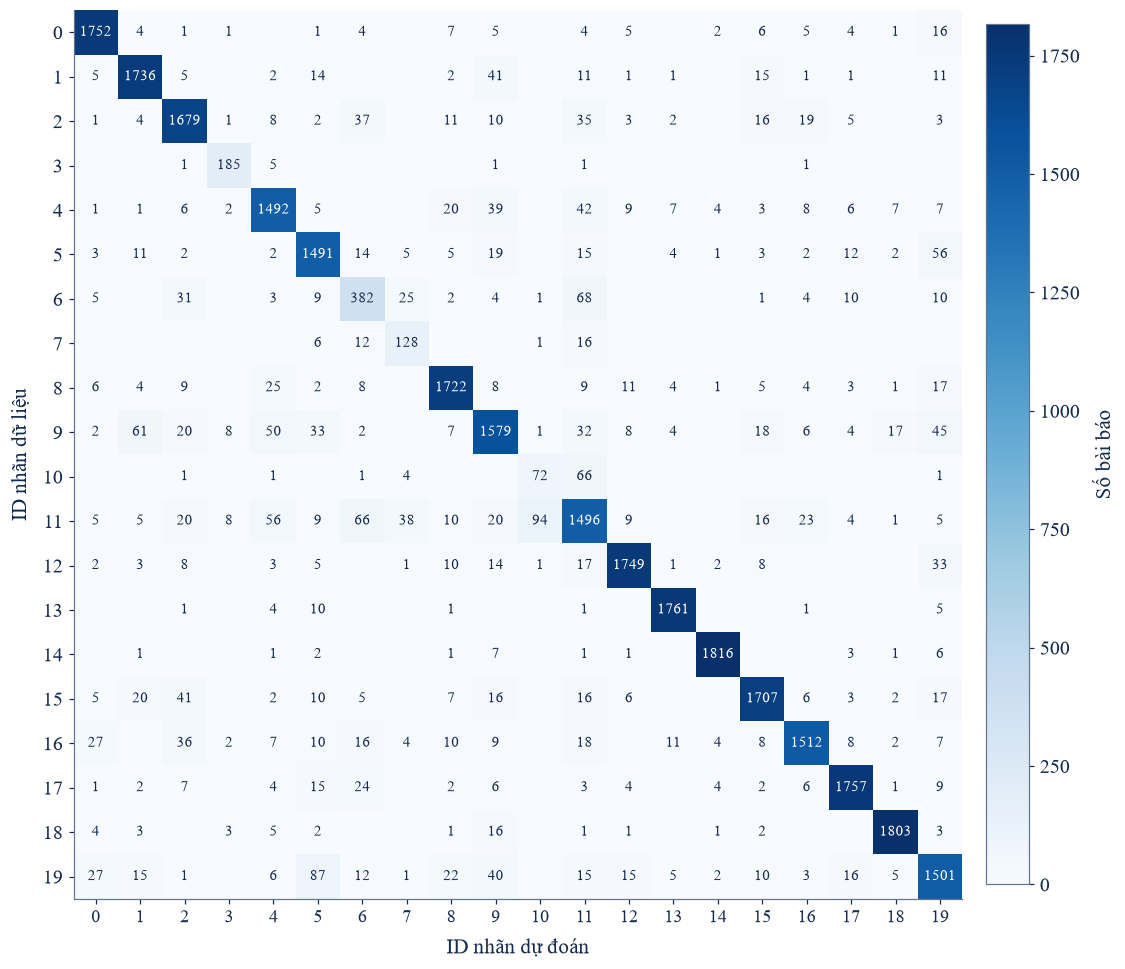

# Lưu kết quả: Xuất hình: confusion before


In [29]:
_cm = confusion_matrix(y_true_ids, y_pred_ids, labels=range(N_CLASSES))
fig = matrix_figure(_cm, normalized=False)
save_fig(fig, "evaluation/confusion_before")

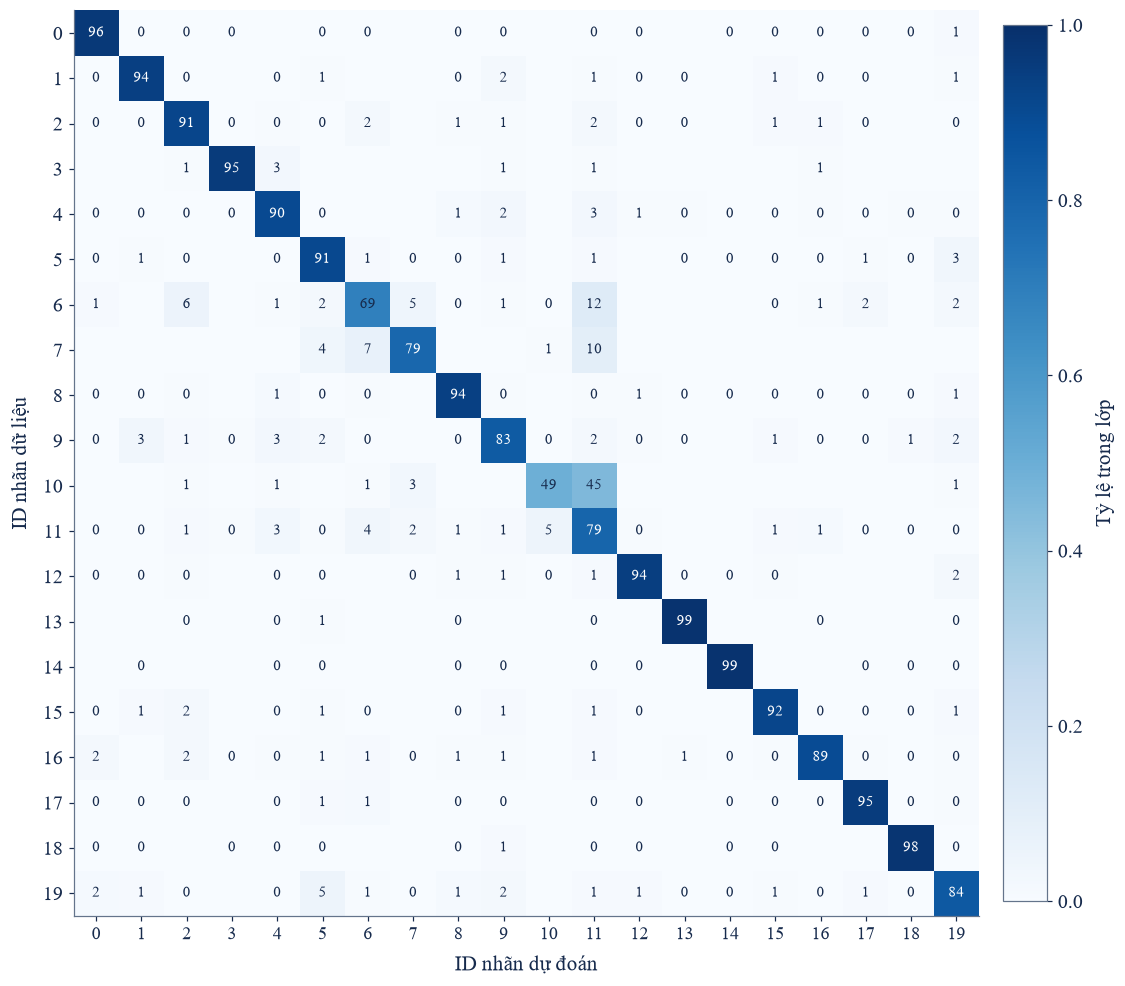

# Lưu kết quả: Xuất hình: confusion before normalized


In [30]:
fig = matrix_figure(_cm, normalized=True)
save_fig(fig, "evaluation/confusion_before_normalized")

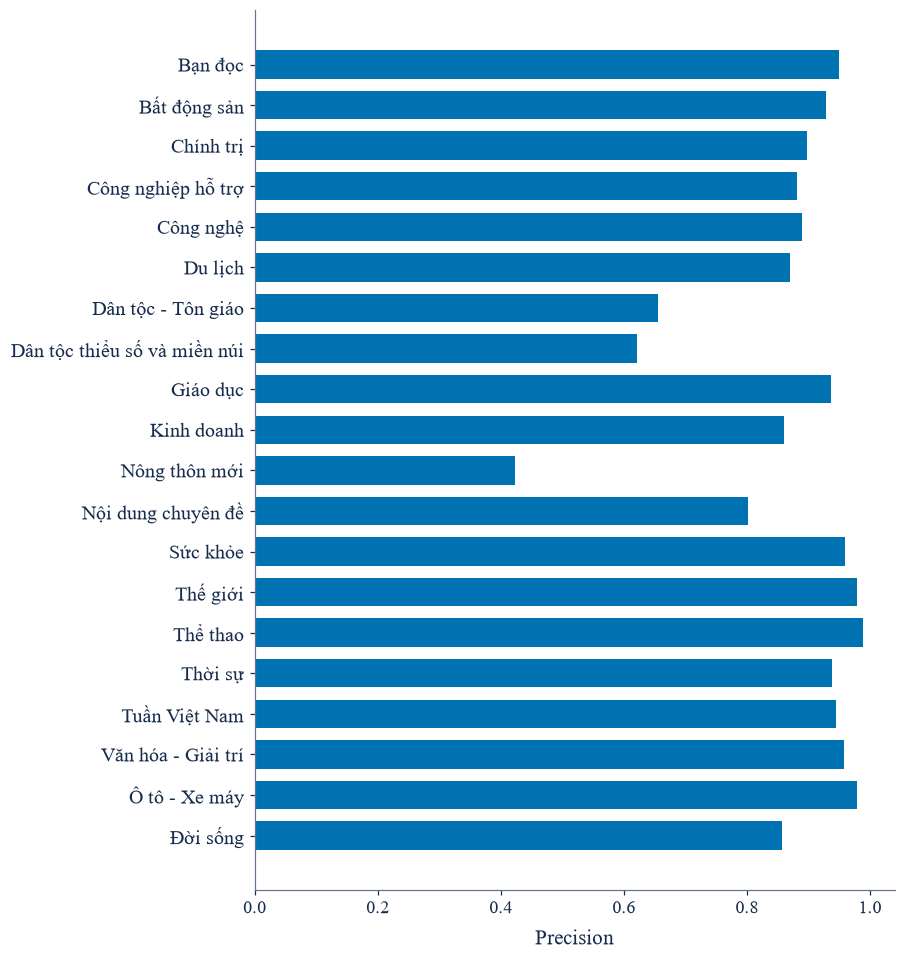

# Lưu kết quả: Xuất hình: precision before


In [31]:
report_before = classification_report(
    y_true_ids,
    y_pred_ids,
    labels=range(N_CLASSES),
    target_names=classes,
    output_dict=True,
    zero_division=0,
)
class_metric_figure(report_before, "precision", "evaluation/precision_before")

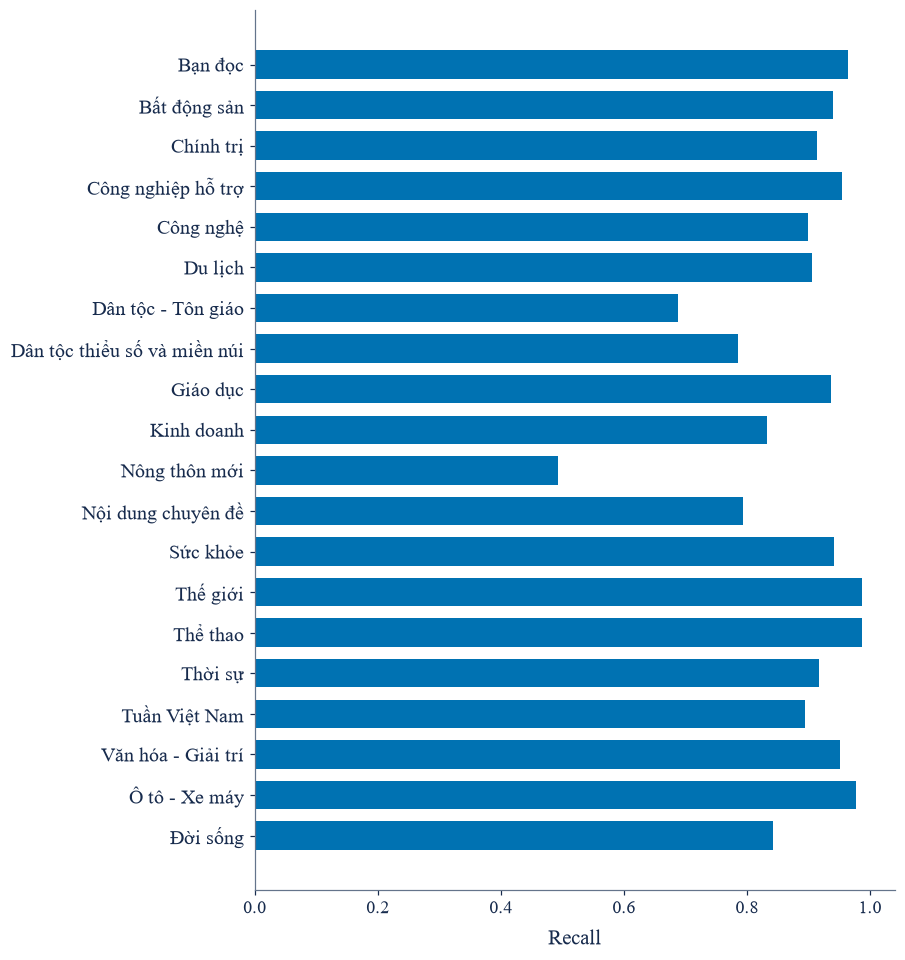

# Lưu kết quả: Xuất hình: recall before


In [32]:
class_metric_figure(report_before, "recall", "evaluation/recall_before")

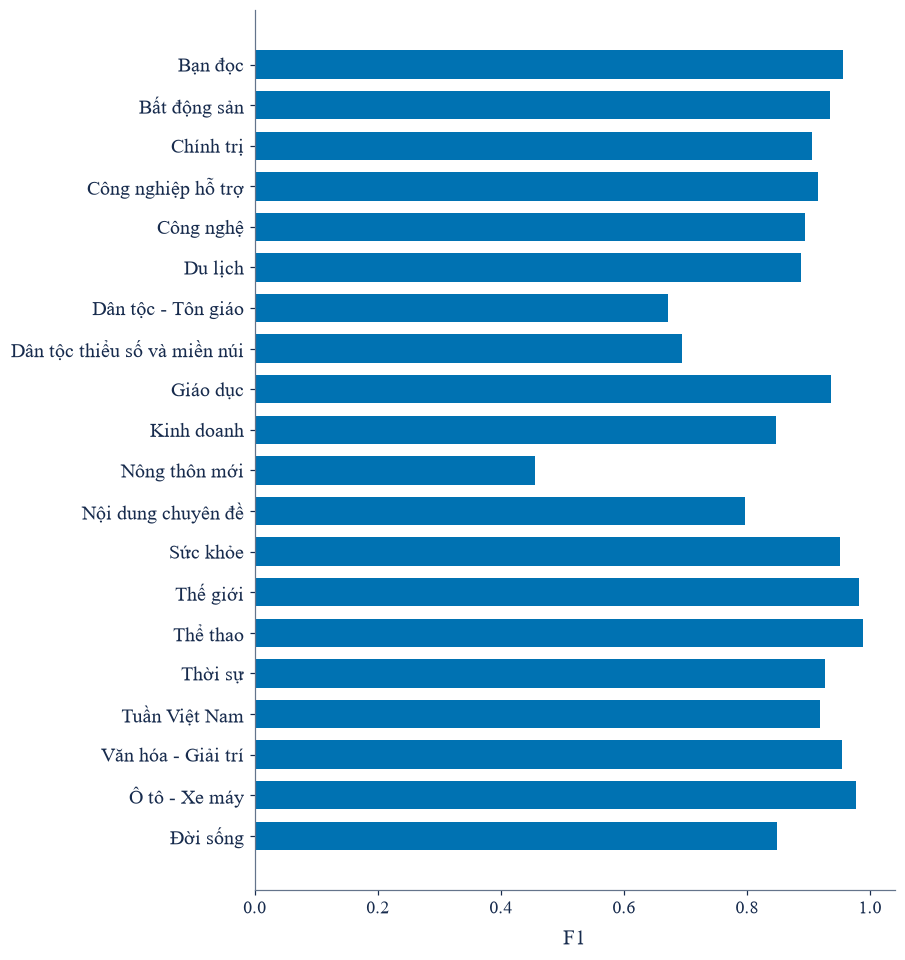

# Lưu kết quả: Xuất hình: f1 before


In [33]:
class_metric_figure(report_before, "f1-score", "evaluation/f1_before")

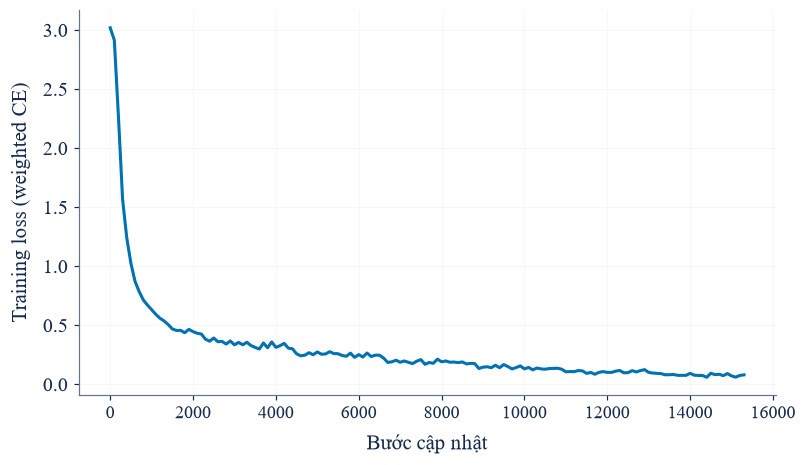

# Lưu kết quả: Xuất hình: train loss


In [34]:
history_figure(
    "loss", "training/train_loss", "Training loss (weighted CE)", xkey="step"
)

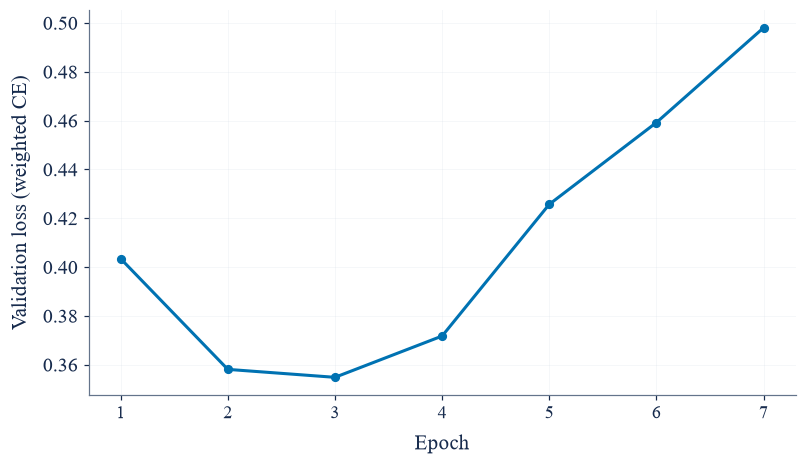

# Lưu kết quả: Xuất hình: eval loss


In [35]:
history_figure(
    "eval_loss", "training/eval_loss", "Validation loss (weighted CE)", xkey="epoch"
)

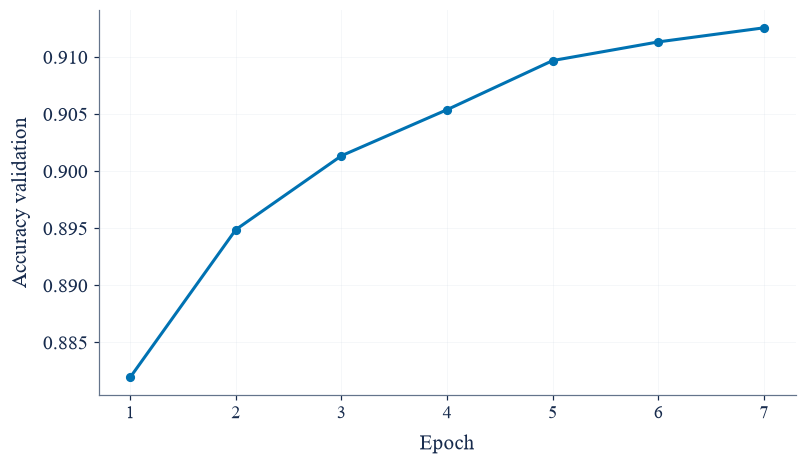

# Lưu kết quả: Xuất hình: eval accuracy


In [36]:
history_figure(
    "eval_accuracy", "training/eval_accuracy", "Accuracy validation", xkey="epoch"
)

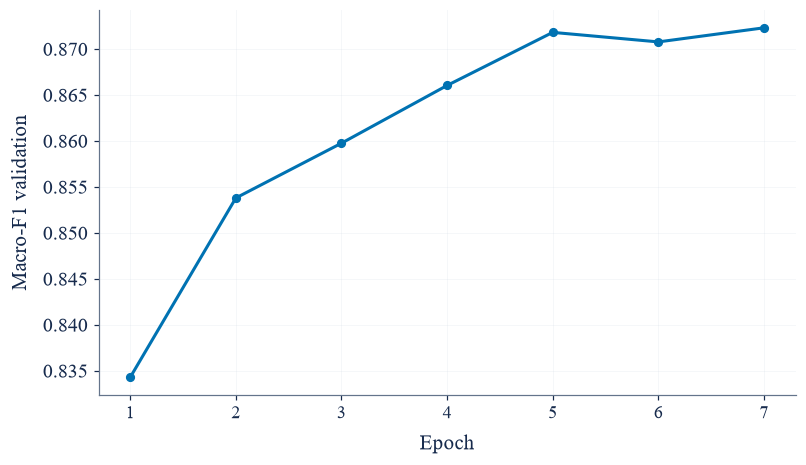

# Lưu kết quả: Xuất hình: eval macro f1


In [37]:
history_figure(
    "eval_f1_macro", "training/eval_macro_f1", "Macro-F1 validation", xkey="epoch"
)

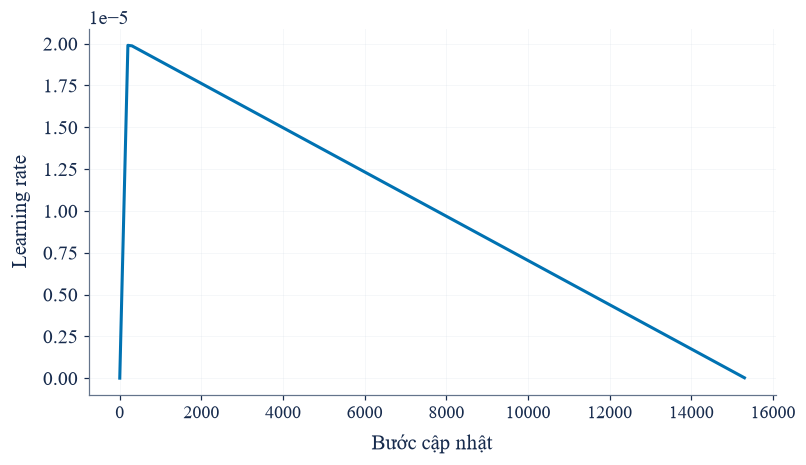

# Lưu kết quả: Xuất hình: learning rate


In [38]:
history_figure("learning_rate", "training/learning_rate", "Learning rate", xkey="step")

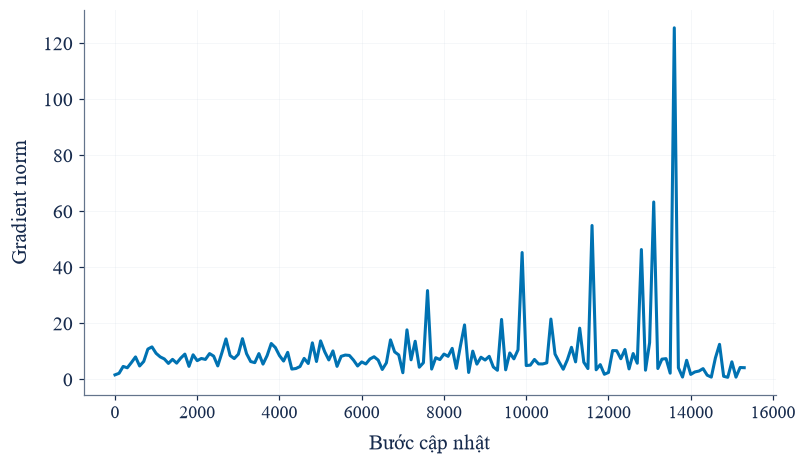

# Lưu kết quả: Xuất hình: gradient norm


In [39]:
history_figure("grad_norm", "training/gradient_norm", "Gradient norm", xkey="step")

In [40]:
# Tóm tắt kết quả
print(f"\n{'=' * 60}")
print(f"  KẾT QUẢ - PhoBERT Base v2 Head-Tail")
print(f"{'=' * 60}")
print(f"\n  [CẤU HÌNH MÔ HÌNH]")
print(f"    Model        : {MODEL_NAME}")
print(f"    Strategy     : Head-Tail (127 + 127 tokens)")
print(f"    Độ dài đầu vào: {MAX_LENGTH}")
print(
    f"    Batch (eff)  : {BATCH_SIZE} × {GPU_COUNT} GPU × {GRAD_ACCUM} = {EFFECTIVE_BATCH_SIZE}"
)
print(f"    LR           : {LR}  |  Epochs: {NUM_EPOCHS}  |  BF16: {BF16}")
print(f"    Trọng số class: balanced")
print(f"\n  [DỮ LIỆU]")
print(f"    Số chủ đề    : {N_CLASSES}")
print(f"    Train        : {len(y_train):,} bài  ({TRAIN_SIZE * 100:.0f}%)")
print(f"    Validation   : {len(y_val):,} bài   ({VAL_SIZE * 100:.0f}%)")
print(f"    Test         : {len(y_test):,} bài   ({TEST_SIZE * 100:.0f}%)")
if train_time_sec:
    print(
        f"    Train time   : {train_time_sec / 60:.1f} phút  ({train_time_sec / 3600:.2f} giờ)"
    )
print(f"\n  [HIỆU NĂNG TRÊN TEST ĐỘC LẬP]")
print(f"    Accuracy     : {model_acc:.4f}  ({model_acc * 100:.2f}%)")
print(f"    F1-weighted  : {model_f1w:.4f}")
print(f"    F1-macro     : {model_f1m:.4f}")
print(f"\n  [5 CHỦ ĐỀ KHÓ PHÂN LOẠI NHẤT]")
for _cls, _v in sorted(f1_per_class.items(), key=lambda x: x[1])[:5]:
    print(f"    {_cls:<38}  F1 = {_v:.4f}")
print(f"\n  [5 CHỦ ĐỀ DỄ PHÂN LOẠI NHẤT]")
for _cls, _v in sorted(f1_per_class.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"    {_cls:<38}  F1 = {_v:.4f}")

_cm2 = confusion_matrix(y_true_ids, y_pred_ids, labels=list(range(N_CLASSES)))
_confused = sorted(
    [
        (_cm2[i, j], classes[i], classes[j])
        for i in range(N_CLASSES)
        for j in range(N_CLASSES)
        if i != j and _cm2[i, j] > 0
    ],
    reverse=True,
)
print(f"\n  [TOP 5 CẶP CHỦ ĐỀ BỊ NHẦM NHIỀU NHẤT]")
for _cnt, _tr, _pr in _confused[:5]:
    print(f"    {_tr:<28} -> {_pr:<28}  {_cnt:>4} lần")


  KẾT QUẢ - PhoBERT Base v2 Head-Tail

  [CẤU HÌNH MÔ HÌNH]
    Model        : vinai/phobert-base-v2
    Strategy     : Head-Tail (127 + 127 tokens)
    Độ dài đầu vào: 256
    Batch (eff)  : 32 × 1 GPU × 2 = 64
    LR           : 2e-05  |  Epochs: 7  |  BF16: True
    Trọng số class: balanced

  [DỮ LIỆU]
    Số chủ đề    : 20
    Train        : 139,975 bài  (70%)
    Validation   : 29,995 bài   (15%)
    Test         : 29,995 bài   (15%)
    Train time   : 207.2 phút  (3.45 giờ)

  [HIỆU NĂNG TRÊN TEST ĐỘC LẬP]
    Accuracy     : 0.9108  (91.08%)
    F1-weighted  : 0.9112
    F1-macro     : 0.8722

  [5 CHỦ ĐỀ KHÓ PHÂN LOẠI NHẤT]
    Nông thôn mới                           F1 = 0.4557
    Dân tộc - Tôn giáo                      F1 = 0.6714
    Dân tộc thiểu số và miền núi            F1 = 0.6938
    Nội dung chuyên đề                      F1 = 0.7974
    Kinh doanh                              F1 = 0.8464

  [5 CHỦ ĐỀ DỄ PHÂN LOẠI NHẤT]
    Thể thao                                F1 

---
## Xuất cấu hình mô hình

Lưu `label_config.json` vào `model/` để phục vụ suy luận về sau.
Model và tokenizer đã được Trainer lưu tự động ở phần huấn luyện.


In [41]:
_label_config = {
    "model_name": MODEL_NAME,
    "strategy": "head_tail",
    "max_length": MAX_LENGTH,
    "n_classes": N_CLASSES,
    "classes": classes,
    "label2id": label2id,
    "id2label": {str(k): v for k, v in id2label.items()},
    "preprocessing": {
        "title_weight": 1,
        "lowercase": True,
        "remove_punct": True,
        "remove_digits": True,
        "tokenizer": "pyvi.ViTokenizer",
        "stopwords": False,
    },
}
with open(LABEL_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(_label_config, f, ensure_ascii=False, indent=2)
log("Đã lưu cấu hình suy luận.", "SAVE")

# Lưu kết quả: Đã lưu cấu hình suy luận.


## Đánh giá hiệu chỉnh trên test

Temperature và hệ số từng class được tối ưu **chỉ trên validation**, rồi giữ cố định.
Phần này đo tác động trên test độc lập theo quy tắc argmax(softmax(logits / temperature) / thresholds).
Hệ số lớn khiến class khó được chọn hơn; hệ số nhỏ khiến class dễ được chọn hơn.
Coordinate search tối ưu Macro-F1 validation, không đảm bảo chỉ số test tăng.


In [42]:
_THRESHOLD_PATH = os.path.join(MODEL_DIR, "thresholds.json")
_logits = raw_logits
_labels = np.array(y_true_ids)


def _nll_eval(temperature):
    p = temperature_probabilities(_logits, temperature)
    return float(-np.log(p[np.arange(len(_labels)), _labels] + 1e-10).mean())


_nll_before = _nll_eval(1.0)
_nll_after = _nll_eval(T_OPTIMAL)
_ece_before = expected_calibration_error(_logits, _labels)
_ece_after = expected_calibration_error(_logits, _labels, T_OPTIMAL)
print(f"# Nhiệt độ fit trên validation: {T_OPTIMAL:.4f}.")
print(
    f"# Test NLL: {_nll_before:.4f} → {_nll_after:.4f}; ECE: {_ece_before:.4f} → {_ece_after:.4f}."
)

# Nhiệt độ fit trên validation: 1.4551.
# Test NLL: 0.3839 → 0.3220; ECE: 0.0603 → 0.0251.


In [43]:
# Áp dụng tham số validation lên test, không tìm tham số trên test.
y_true_arr = np.array(y_true_ids)
probs = temperature_probabilities(raw_logits, T_OPTIMAL)
_base_preds = np.argmax(probs, axis=1)
_base_f1 = f1_score(
    y_true_arr, _base_preds, average=None, labels=range(N_CLASSES), zero_division=0
)
_cal_preds = np.argmax(probs / thresholds, axis=1)
_cal_f1 = f1_score(y_true_arr, _cal_preds, average=None, labels=list(range(N_CLASSES)))

cal_acc = accuracy_score(y_true_arr, _cal_preds)
cal_f1w = f1_score(y_true_arr, _cal_preds, average="weighted")
cal_f1m = f1_score(y_true_arr, _cal_preds, average="macro")

print(f"\n{'=' * 72}")
print(f"  {'Metric':<20}  {'Before':>10}  {'After':>10}  {'Delta':>8}")
print(f"  {'-' * 68}")
for _name, _before, _after in [
    ("Accuracy", model_acc, cal_acc),
    ("F1-weighted", model_f1w, cal_f1w),
    ("F1-macro", model_f1m, cal_f1m),
]:
    _delta = _after - _before
    _sign = "+" if _delta >= 0 else ""
    print(f"  {_name:<20}  {_before:>10.4f}  {_after:>10.4f}  {_sign}{_delta:>7.4f}")
print(f"{'=' * 72}")

print(
    f"\n  {'Class':<38}  {'Before':>7}  {'After':>7}  {'Delta':>7}  {'Threshold':>10}"
)
print(f"  {'-' * 72}")
for i, cls in enumerate(classes):
    _b = _base_f1[i]
    _a = _cal_f1[i]
    _d = _a - _b
    _sign = "+" if _d >= 0 else ""
    _mark = " ^" if _d > 0.005 else (" v" if _d < -0.005 else "")
    print(
        f"  {cls:<38}  {_b:>7.4f}  {_a:>7.4f}  {_sign}{_d:>6.4f}  {thresholds[i]:>10.4f}{_mark}"
    )


  Metric                    Before       After     Delta
  --------------------------------------------------------------------
  Accuracy                  0.9108      0.9113  + 0.0004
  F1-weighted               0.9112      0.9114  + 0.0003
  F1-macro                  0.8722      0.8725  + 0.0003

  Class                                    Before    After    Delta   Threshold
  ------------------------------------------------------------------------
  Bạn đọc                                  0.9563   0.9541  -0.0023      0.6055
  Bất động sản                             0.9343   0.9345  +0.0002      0.6377
  Chính trị                                0.9063   0.9054  -0.0010      0.9915
  Công nghiệp hỗ trợ                       0.9158   0.9127  -0.0031      0.9915
  Công nghệ                                0.8948   0.8924  -0.0024      0.9432
  Du lịch                                  0.8875   0.8890  +0.0015      1.0879
  Dân tộc - Tôn giáo                       0.6714   0.6759  +0.0

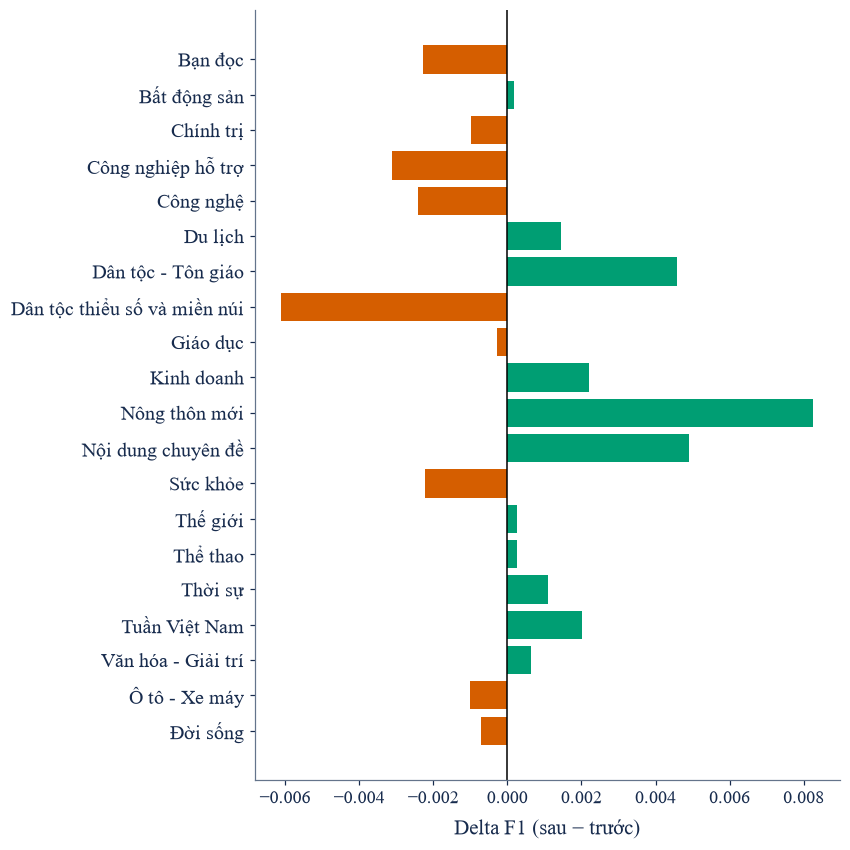

# Lưu kết quả: Xuất hình: delta f1


In [44]:
fig, ax = plt.subplots(figsize=(8, 8))
delta = _cal_f1 - _base_f1
ax.barh(
    range(N_CLASSES),
    delta,
    color=[
        CHART_COLORS["positive"] if x >= 0 else CHART_COLORS["comparison"]
        for x in delta
    ],
)
ax.set(yticks=range(N_CLASSES), yticklabels=classes, xlabel="Delta F1 (sau − trước)")
ax.invert_yaxis()
ax.axvline(0, color="black", lw=1)
save_fig(fig, "evaluation/delta_f1")

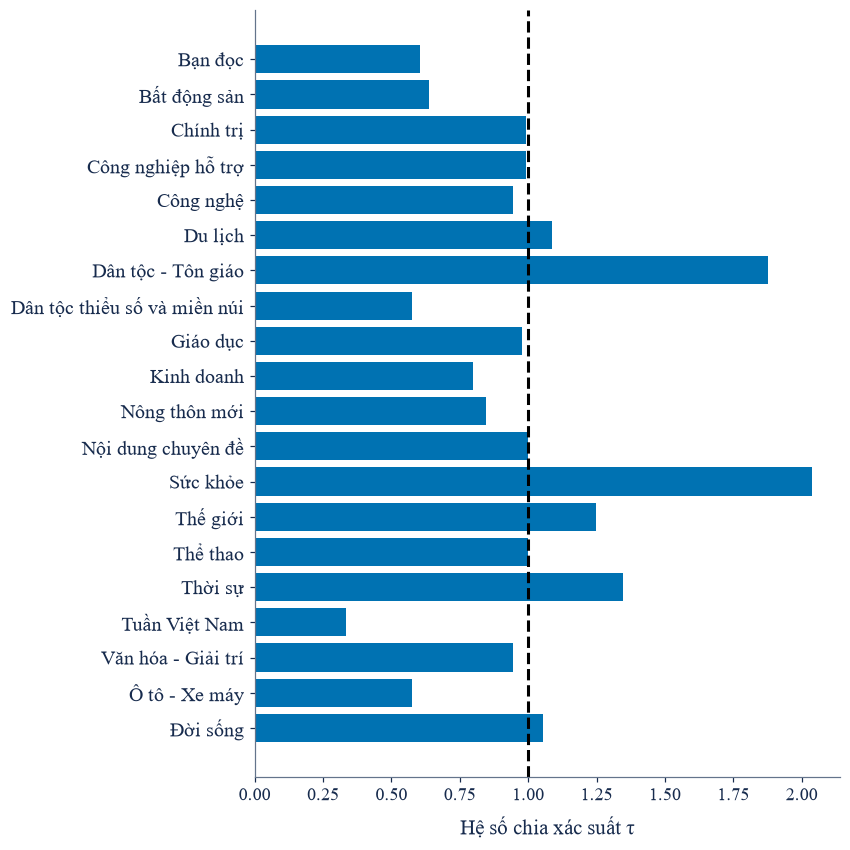

# Lưu kết quả: Xuất hình: class thresholds


In [45]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(range(N_CLASSES), thresholds, color=CHART_COLORS["primary"])
ax.set(yticks=range(N_CLASSES), yticklabels=classes, xlabel="Hệ số chia xác suất τ")
ax.invert_yaxis()
ax.axvline(1, color="black", ls="--")
save_fig(fig, "evaluation/class_thresholds")

In [46]:
_threshold_path = os.path.join(MODEL_DIR, "thresholds.json")
_threshold_config = {
    "temperature": T_OPTIMAL,
    "method": "macro_f1_coordinate_search",
    "search_range": [0.3, 3.5],
    "n_grid": 200,
    "n_passes": 3,
    "usage": "predict = argmax(softmax(logits / temperature) / thresholds)",
    "fit_split": "validation",
    "fit_samples": len(val_indices),
    "split_signature": _HT_SIGNATURE,
    "evaluation_split": "test",
    "thresholds": {cls: float(thresholds[i]) for i, cls in enumerate(classes)},
    "validation_metrics": validation_metrics,
    "metrics_before": {
        "accuracy": model_acc,
        "f1_weighted": model_f1w,
        "f1_macro": model_f1m,
    },
    "metrics_after": {"accuracy": cal_acc, "f1_weighted": cal_f1w, "f1_macro": cal_f1m},
}
_atomic_json(_threshold_path, _threshold_config)
log("Đã lưu tham số validation và kết quả test độc lập.", "SAVE")
# Cập nhật label_config.json để pipeline inference biết có threshold
with open(LABEL_CONFIG_PATH, "r", encoding="utf-8") as f:
    _lc = json.load(f)
_lc["threshold_file"] = "thresholds.json"
_lc["use_threshold_calibration"] = True
with open(LABEL_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(_lc, f, ensure_ascii=False, indent=2)
log("Đã cập nhật cấu hình suy luận và ngưỡng dự đoán", "SAVE")

print(f"\n  [THRESHOLDS PER CLASS]")
print(f"  {'Class':<38}  {'Threshold':>10}  {'Ý nghĩa'}")
print(f"  {'-' * 70}")
for i, cls in enumerate(classes):
    t = thresholds[i]
    if t > 1.2:
        meaning = "Giảm dự đoán quá mức"
    elif t < 0.8:
        meaning = "Giảm dự đoán thiếu"
    else:
        meaning = "Gần như không đổi"
    print(f"  {cls:<38}  {t:>10.4f}  {meaning}")

# Lưu kết quả: Đã lưu tham số validation và kết quả test độc lập.
# Lưu kết quả: Đã cập nhật cấu hình suy luận và ngưỡng dự đoán

  [THRESHOLDS PER CLASS]
  Class                                    Threshold  Ý nghĩa
  ----------------------------------------------------------------------
  Bạn đọc                                     0.6055  Giảm dự đoán thiếu
  Bất động sản                                0.6377  Giảm dự đoán thiếu
  Chính trị                                   0.9915  Gần như không đổi
  Công nghiệp hỗ trợ                          0.9915  Gần như không đổi
  Công nghệ                                   0.9432  Gần như không đổi
  Du lịch                                     1.0879  Gần như không đổi
  Dân tộc - Tôn giáo                          1.8759  Giảm dự đoán quá mức
  Dân tộc thiểu số và miền núi                0.5734  Giảm dự đoán thiếu
  Giáo dục                                    0.9754  Gần như không đổi
  Kinh doanh                                  0.7985  Gi

---
## Chẩn đoán mô hình

Phần này in ra các tín hiệu quan trọng để phân tích lỗi sau huấn luyện và calibration, từ đó hỗ trợ cải thiện mô hình ở vòng tiếp theo.


In [47]:
# Build before/after diagnostic table

_base_report = classification_report(
    y_true_ids,
    y_pred_ids,
    labels=list(range(N_CLASSES)),
    target_names=classes,
    digits=4,
    output_dict=True,
    zero_division=0,
)
_cal_report = classification_report(
    y_true_ids,
    _cal_preds,
    labels=list(range(N_CLASSES)),
    target_names=classes,
    digits=4,
    output_dict=True,
    zero_division=0,
)
_diag_df = pd.DataFrame(
    [
        {
            "class": cls,
            "support": int(_base_report[cls]["support"]),
            "precision_before": _base_report[cls]["precision"],
            "recall_before": _base_report[cls]["recall"],
            "f1_before": _base_report[cls]["f1-score"],
            "precision_after": _cal_report[cls]["precision"],
            "recall_after": _cal_report[cls]["recall"],
            "f1_after": _cal_report[cls]["f1-score"],
            "threshold": float(thresholds[classes.index(cls)]),
        }
        for cls in classes
    ]
)
_diag_df["delta_f1"] = _diag_df["f1_after"] - _diag_df["f1_before"]
_diag_df["pr_gap_after"] = _diag_df["recall_after"] - _diag_df["precision_after"]
_diag_df["support_pct"] = _diag_df["support"] / max(int(np.asarray(_diag_df["support"]).sum()), 1)

print(f"\n{'=' * 92}")
print("[TÓM TẮT CHẨN ĐOÁN PHOBERT]")
print(f"  F1-macro before : {model_f1m:.4f}")
print(f"  F1-macro after  : {cal_f1m:.4f}  ({cal_f1m - model_f1m:+.4f})")
print(f"  F1-weighted bef.: {model_f1w:.4f}")
print(f"  F1-weighted aft.: {cal_f1w:.4f}  ({cal_f1w - model_f1w:+.4f})")
print(f"  Accuracy before : {model_acc:.4f}")
print(f"  Accuracy after  : {cal_acc:.4f}  ({cal_acc - model_acc:+.4f})")
print(f"  Temperature     : {T_OPTIMAL:.4f}")
print(f"{'=' * 92}")

print("\n[5 CHỦ ĐỀ YẾU NHẤT SAU CALIBRATION]")
for r in (
    _diag_df.sort_values(["f1_after", "support"], ascending=[True, True])
    .head(5)
    .to_dict("records")
):
    print(
        f"  {r['class']:<30}  F1={r['f1_after']:.4f}  P={r['precision_after']:.4f}  R={r['recall_after']:.4f}  số mẫu={int(r['support'])}"
    )

print("\n[5 CHỦ ĐỀ ÍT MẪU NHẤT]")
for r in (
    _diag_df.sort_values(["support", "f1_after"], ascending=[True, True])
    .head(5)
    .to_dict("records")
):
    print(
        f"  {r['class']:<30}  số mẫu={int(r['support']):>5}  ({r['support_pct'] * 100:>5.2f}%)  F1 sau={r['f1_after']:.4f}"
    )

print("\n[5 CHỦ ĐỀ CẢI THIỆN NHIỀU NHẤT SAU CALIBRATION]")
for r in _diag_df.sort_values("delta_f1", ascending=False).head(5).to_dict("records"):
    print(
        f"  {r['class']:<30}  trước={r['f1_before']:.4f}  sau={r['f1_after']:.4f}  chênh lệch={r['delta_f1']:+.4f}  thr={r['threshold']:.4f}"
    )

print("\n[5 CHỦ ĐỀ GIẢM NHIỀU NHẤT SAU CALIBRATION]")
for r in _diag_df.sort_values("delta_f1", ascending=True).head(5).to_dict("records"):
    print(
        f"  {r['class']:<30}  trước={r['f1_before']:.4f}  sau={r['f1_after']:.4f}  chênh lệch={r['delta_f1']:+.4f}  thr={r['threshold']:.4f}"
    )

print("\n[CÁC CHỦ ĐỀ CÓ RECALL THẤP SAU CALIBRATION]")
for r in _diag_df.sort_values("pr_gap_after", ascending=True).head(5).to_dict("records"):
    print(
        f"  {r['class']:<30}  độ lệch={r['pr_gap_after']:+.4f}  P={r['precision_after']:.4f}  R={r['recall_after']:.4f}  thr={r['threshold']:.4f}"
    )

print("\n[CÁC CHỦ ĐỀ CÓ PRECISION THẤP SAU CALIBRATION]")
for r in _diag_df.sort_values("pr_gap_after", ascending=False).head(5).to_dict("records"):
    print(
        f"  {r['class']:<30}  độ lệch={r['pr_gap_after']:+.4f}  P={r['precision_after']:.4f}  R={r['recall_after']:.4f}  thr={r['threshold']:.4f}"
    )

# Top confusion pairs after calibration
_cm_cal = confusion_matrix(y_true_ids, _cal_preds, labels=list(range(N_CLASSES)))
_pairs = []
for i, true_cls in enumerate(classes):
    _support = max(int(_cm_cal[i].sum()), 1)
    for j, pred_cls in enumerate(classes):
        if i == j or _cm_cal[i, j] == 0:
            continue
        _pairs.append(
            {
                "count": int(_cm_cal[i, j]),
                "rate": float(_cm_cal[i, j] / _support),
                "true": true_cls,
                "pred": pred_cls,
            }
        )
_pairs_df = (
    pd.DataFrame(_pairs).sort_values(["count", "rate"], ascending=[False, False])
    if _pairs
    else pd.DataFrame(columns=["count", "rate", "true", "pred"])
)

print("\n[TOP 8 CẶP CHỦ ĐỀ BỊ NHẦM NHIỀU NHẤT SAU CALIBRATION]")
if len(_pairs_df) == 0:
    print("  Không có cặp nhầm lẫn ngoài đường chéo.")
else:
    for r in _pairs_df.head(8).to_dict("records"):
        print(
            f"  {r['true']:<28} -> {r['pred']:<28}  {int(r['count']):>4} lần  ({r['rate'] * 100:>5.2f}%)"
        )


[TÓM TẮT CHẨN ĐOÁN PHOBERT]
  F1-macro before : 0.8722
  F1-macro after  : 0.8725  (+0.0003)
  F1-weighted bef.: 0.9112
  F1-weighted aft.: 0.9114  (+0.0003)
  Accuracy before : 0.9108
  Accuracy after  : 0.9113  (+0.0004)
  Temperature     : 1.4551

[5 CHỦ ĐỀ YẾU NHẤT SAU CALIBRATION]
  Nông thôn mới                   F1=0.4639  P=0.4277  R=0.5068  số mẫu=146
  Dân tộc - Tôn giáo              F1=0.6759  P=0.6952  R=0.6577  số mẫu=555
  Dân tộc thiểu số và miền núi    F1=0.6877  P=0.6009  R=0.8037  số mẫu=163
  Nội dung chuyên đề              F1=0.8023  P=0.8047  R=0.8000  số mẫu=1885
  Đời sống                        F1=0.8485  P=0.8618  R=0.8357  số mẫu=1783

[5 CHỦ ĐỀ ÍT MẪU NHẤT]
  Nông thôn mới                   số mẫu=  146  ( 0.49%)  F1 sau=0.4639
  Dân tộc thiểu số và miền núi    số mẫu=  163  ( 0.54%)  F1 sau=0.6877
  Công nghiệp hỗ trợ              số mẫu=  194  ( 0.65%)  F1 sau=0.9127
  Dân tộc - Tôn giáo              số mẫu=  555  ( 1.85%)  F1 sau=0.6759
  Du lịch         

## Xuất kết quả và phân tích trực quan

Kết quả được tính từ dataset, ba tập, lịch sử huấn luyện và logits của lượt thực thi.
Mỗi hình hiển thị và xuất riêng. Ma trận sử dụng ID theo bảng nhãn.
Validation chọn checkpoint và fit tham số hiệu chỉnh; các bảng chỉ số và phân tích lỗi
bên dưới sử dụng **test độc lập**. Đường Precision–Recall đánh giá từng class theo
cơ chế một-chống-phần-còn-lại; không thay thế quyết định phân loại đa lớp.


In [48]:
audit, run_metrics = export_run(
    RUN_ROOT,
    df_raw,
    df,
    classes,
    train_indices,
    test_indices,
    _tlen,
    _cw_vals,
    raw_logits,
    log_history,
    train_time_sec,
    T_OPTIMAL,
    thresholds,
    RANDOM_STATE,
    TEST_SIZE,
    "bf16_autocast" if BF16 else "fp16_autocast",
    inference_seconds=inference_seconds,
    val_indices=val_indices,
    validation_logits=validation_logits,
    val_size=VAL_SIZE,
    split_manifest=split_manifest,
)
print("Đã xuất metrics, logits, predictions, audit, history, manifest và gói app.")

Đã xuất metrics, logits, predictions, audit, history, manifest và gói app.


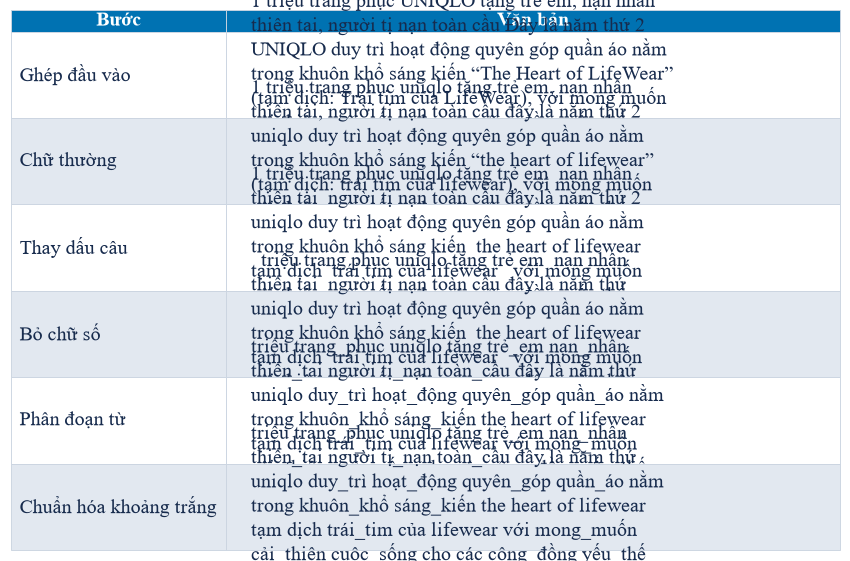

# Lưu kết quả: Xuất hình: preprocessing example


In [49]:
# Minh họa tiền xử lý trên trích đoạn của một bài trong dataset.
from pyvi import ViTokenizer
import textwrap

example_article = df_raw.iloc[0]
example_raw = example_article["title"] + " " + example_article["content"][:240]
example_lower = example_raw.lower()
example_punctuation = re.sub(r"[^\w\s]", " ", example_lower)
example_digits = re.sub(r"\d+", " ", example_punctuation)
example_segmented = ViTokenizer.tokenize(example_digits)
example_clean = re.sub(r"\s+", " ", example_segmented).strip()
trace = {
    "title": example_article["title"],
    "source_url": example_article["url"],
    "stages": {
        "Ghép đầu vào": example_raw,
        "Chữ thường": example_lower,
        "Thay dấu câu": example_punctuation,
        "Bỏ chữ số": example_digits,
        "Phân đoạn từ": example_segmented,
        "Chuẩn hóa khoảng trắng": example_clean,
    },
}
write_json(RUN_ROOT / "result/evaluation/preprocessing_examples.json", trace)
fig, ax = plt.subplots(figsize=(8, 8))
ax.axis("off")
rows = [
    [stage, textwrap.fill(text, width=49)] for stage, text in trace["stages"].items()
]
table = ax.table(
    cellText=rows,
    colLabels=["Bước", "Văn bản"],
    loc="center",
    cellLoc="left",
    colWidths=[0.26, 0.74],
)
table.auto_set_font_size(False)
table.set_fontsize(13)
for (row, column), cell in table.get_celld().items():
    cell.set_edgecolor(CHART_COLORS["grid"])
    cell.set_linewidth(0.6)
    if row == 0:
        cell.set_facecolor(CHART_COLORS["primary"])
        cell.get_text().set_color("white")
        cell.get_text().set_fontweight("bold")
        cell.set_height(0.07)
    else:
        line_count = max(value.count("\n") + 1 for value in rows[row - 1])
        cell.set_height(0.037 * line_count + 0.025)
        cell.set_facecolor("white" if row % 2 else CHART_COLORS["muted"])
        cell.PAD = 0.04
save_fig(fig, "dataset/preprocessing_example")

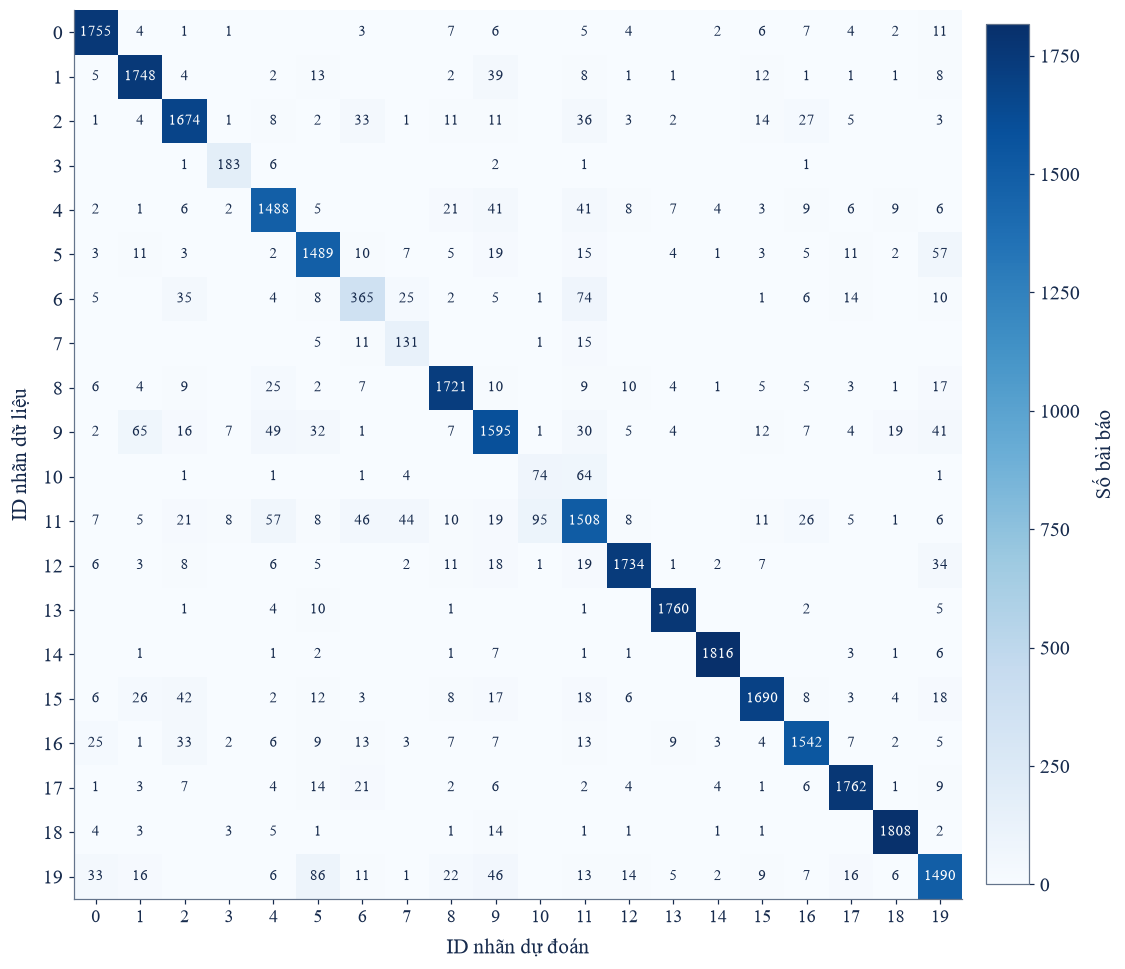

# Lưu kết quả: Xuất hình: confusion after


In [50]:
fig = matrix_figure(_cm_cal, normalized=False)
save_fig(fig, "evaluation/confusion_after")

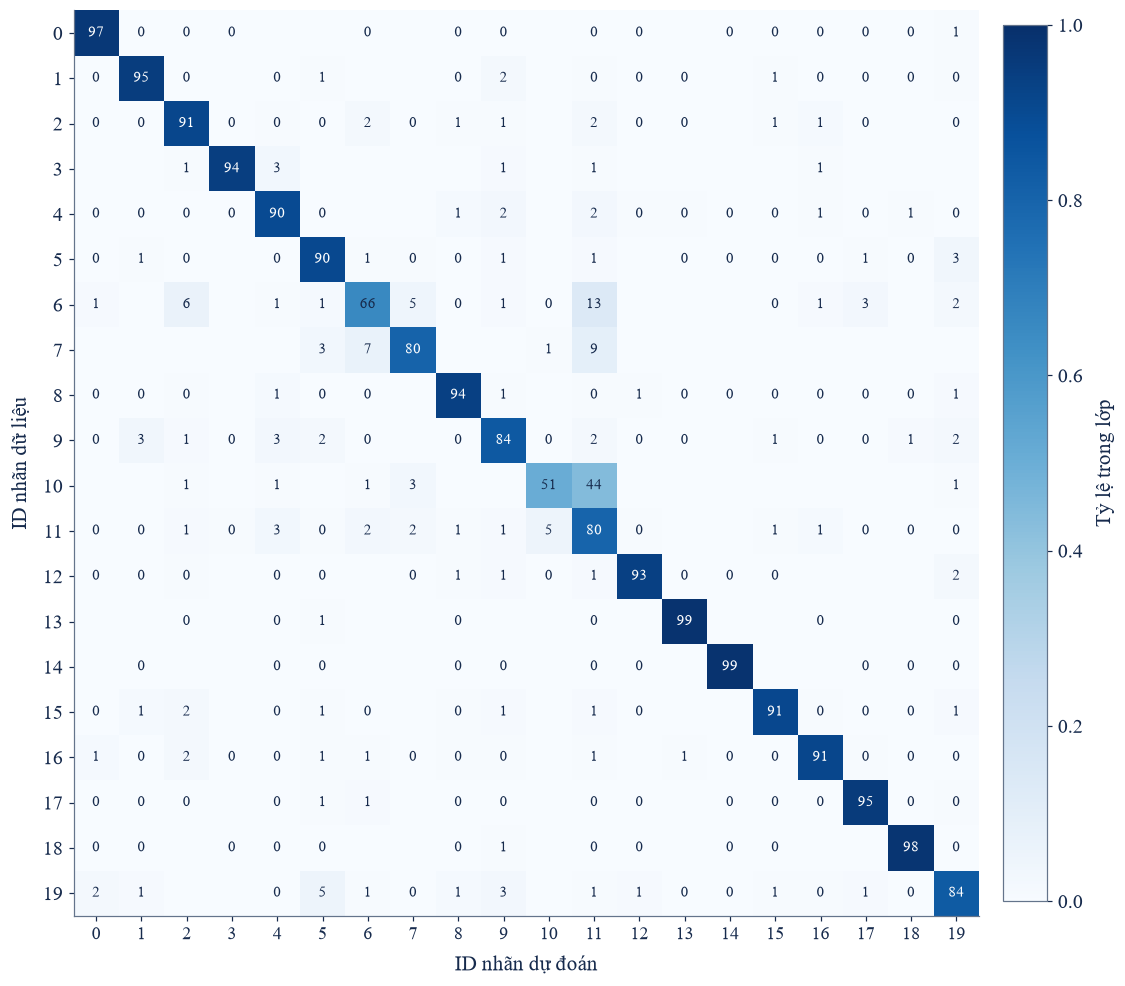

# Lưu kết quả: Xuất hình: confusion after normalized


In [51]:
fig = matrix_figure(_cm_cal, normalized=True)
save_fig(fig, "evaluation/confusion_after_normalized")

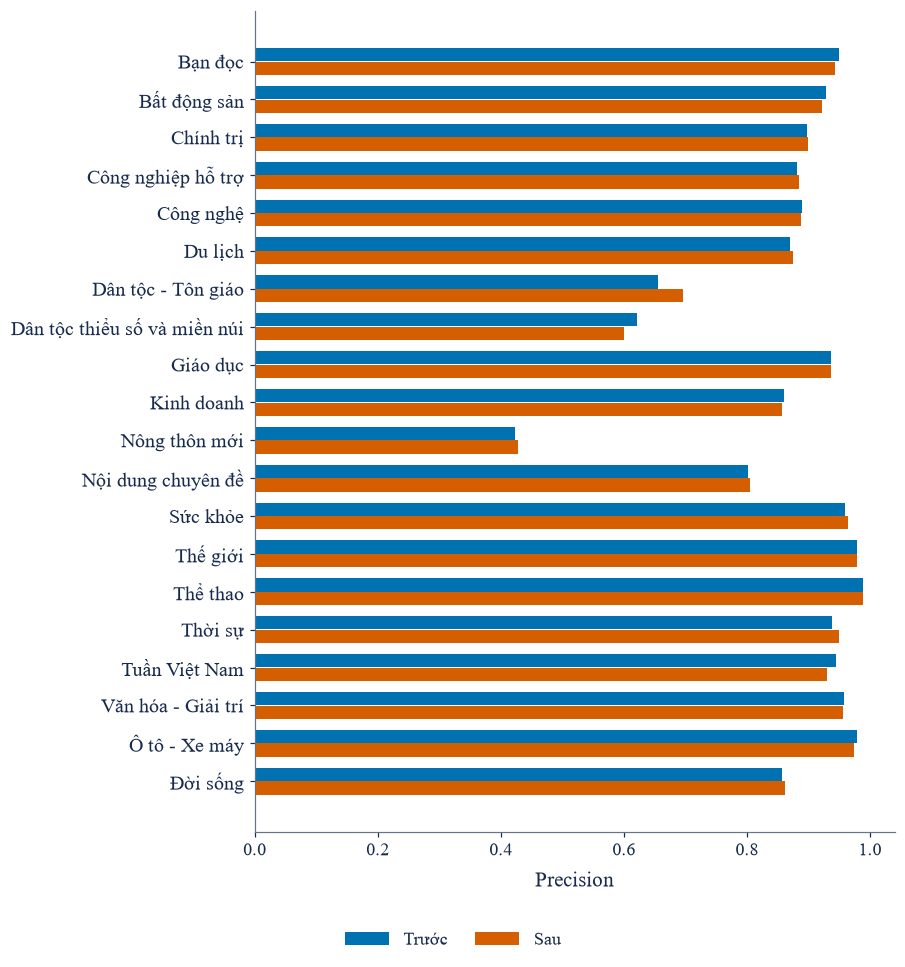

# Lưu kết quả: Xuất hình: per class precision


In [52]:
class_metric_figure(
    _base_report, "precision", "evaluation/per_class_precision", comparison=_cal_report
)

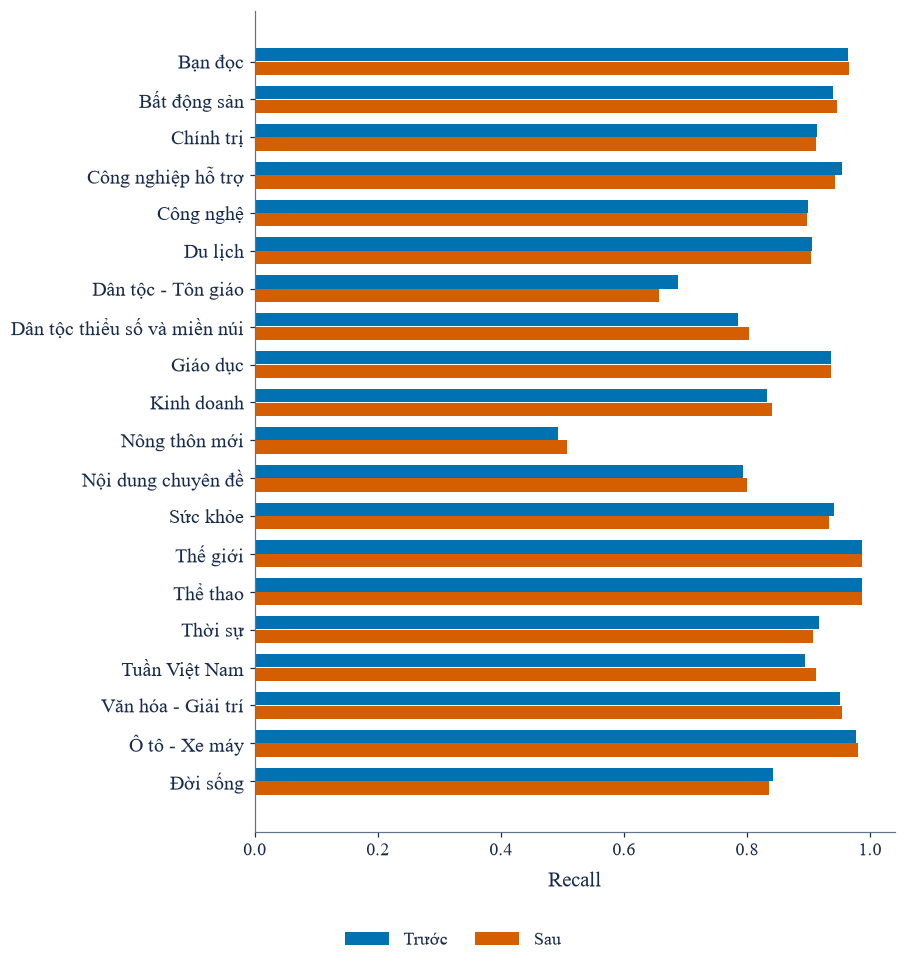

# Lưu kết quả: Xuất hình: per class recall


In [53]:
class_metric_figure(
    _base_report, "recall", "evaluation/per_class_recall", comparison=_cal_report
)

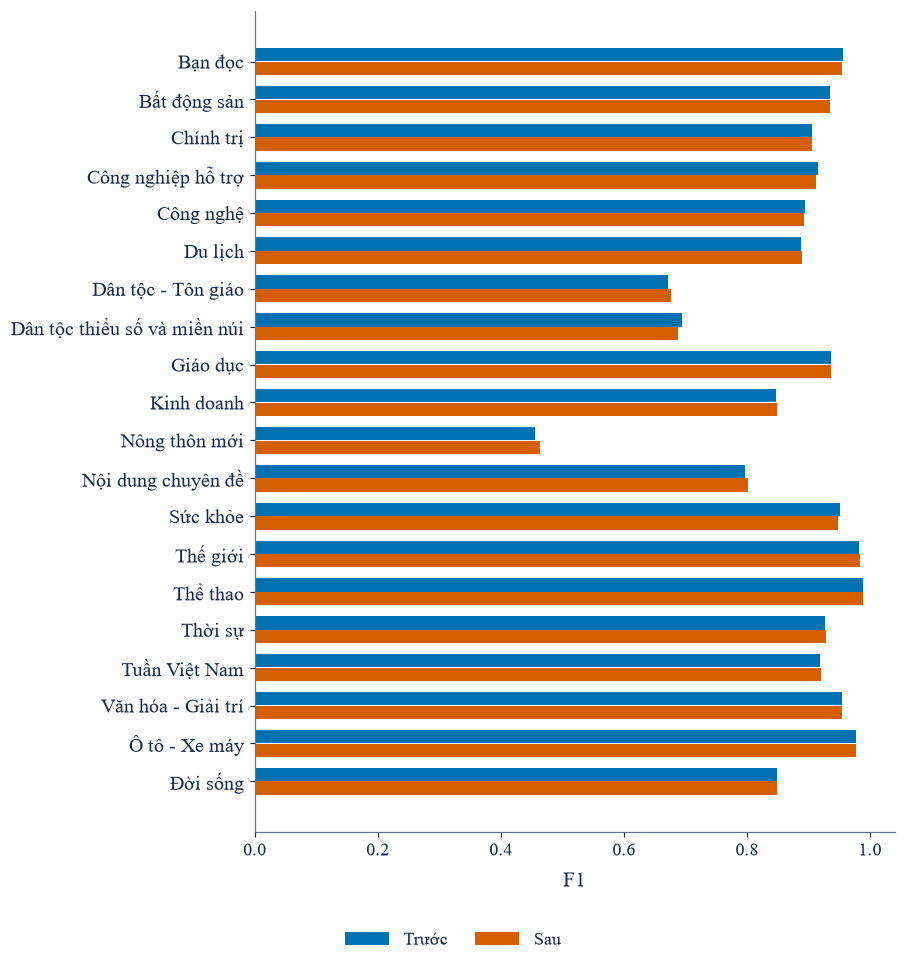

# Lưu kết quả: Xuất hình: per class f1


In [54]:
class_metric_figure(
    _base_report, "f1-score", "evaluation/per_class_f1", comparison=_cal_report
)

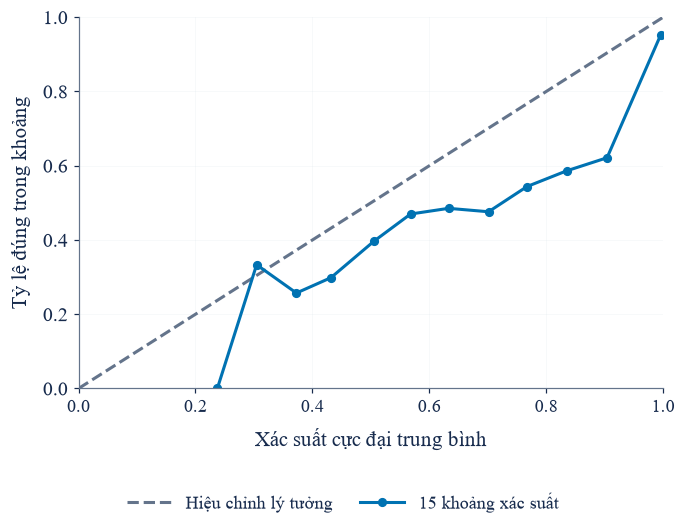

# Lưu kết quả: Xuất hình: reliability before


In [55]:
fig = reliability_figure(raw_logits, np.asarray(y_true_ids), 1.0)
save_fig(fig, "evaluation/reliability_before")

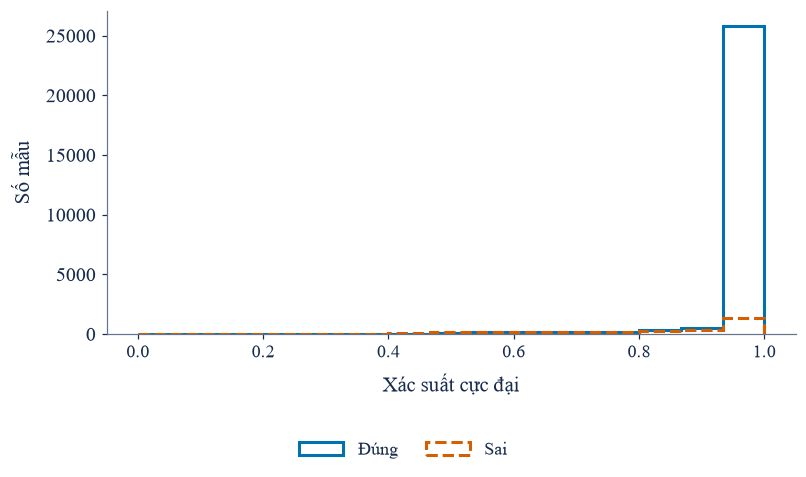

# Lưu kết quả: Xuất hình: confidence before


In [56]:
current_p = temperature_probabilities(raw_logits, 1.0)
conf = current_p.max(1)
correct = current_p.argmax(1) == np.asarray(y_true_ids)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(
    conf[correct],
    bins=np.linspace(0, 1, 16).tolist(),
    color=CHART_COLORS["primary"],
    histtype="step",
    linewidth=2,
    label="Đúng",
)
ax.hist(
    conf[~correct],
    bins=np.linspace(0, 1, 16).tolist(),
    color=CHART_COLORS["comparison"],
    histtype="step",
    linestyle="--",
    linewidth=2,
    label="Sai",
)
ax.set(xlabel="Xác suất cực đại", ylabel="Số mẫu")
ax.legend()
save_fig(fig, "evaluation/confidence_before")

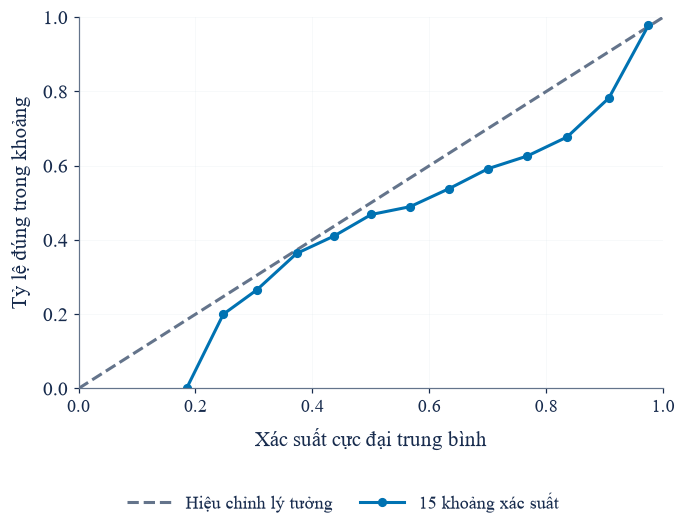

# Lưu kết quả: Xuất hình: reliability temperature


In [57]:
fig = reliability_figure(raw_logits, np.asarray(y_true_ids), T_OPTIMAL)
save_fig(fig, "evaluation/reliability_temperature")

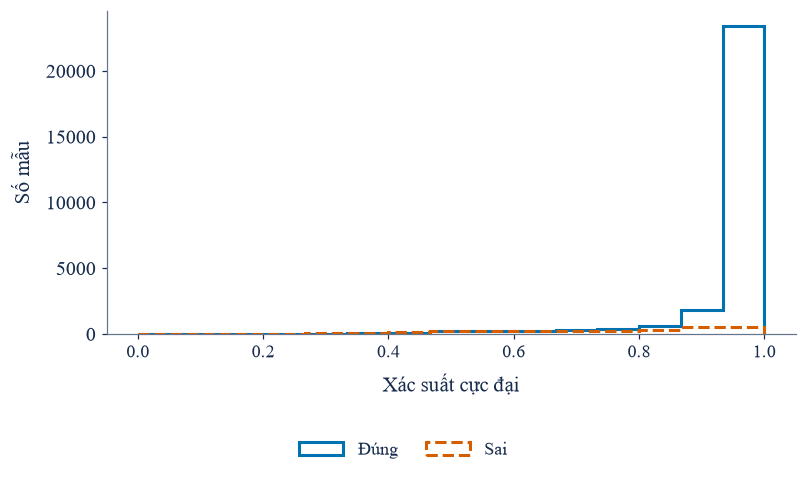

# Lưu kết quả: Xuất hình: confidence temperature


In [58]:
current_p = temperature_probabilities(raw_logits, T_OPTIMAL)
conf = current_p.max(1)
correct = current_p.argmax(1) == np.asarray(y_true_ids)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(
    conf[correct],
    bins=np.linspace(0, 1, 16).tolist(),
    color=CHART_COLORS["primary"],
    histtype="step",
    linewidth=2,
    label="Đúng",
)
ax.hist(
    conf[~correct],
    bins=np.linspace(0, 1, 16).tolist(),
    color=CHART_COLORS["comparison"],
    histtype="step",
    linestyle="--",
    linewidth=2,
    label="Sai",
)
ax.set(xlabel="Xác suất cực đại", ylabel="Số mẫu")
ax.legend()
save_fig(fig, "evaluation/confidence_temperature")

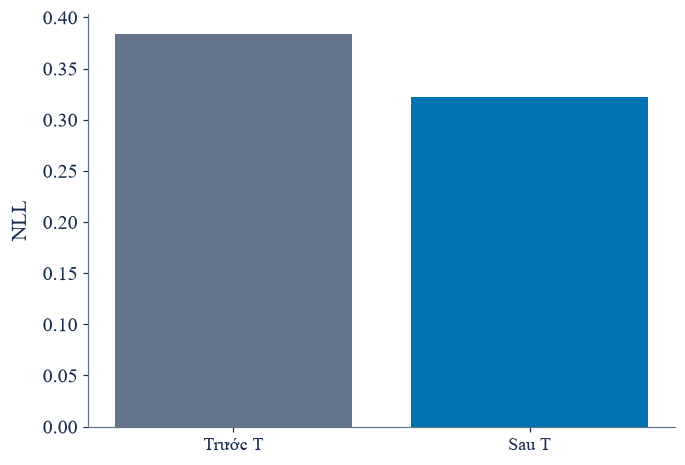

# Lưu kết quả: Xuất hình: nll comparison


In [59]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(
    ["Trước T", "Sau T"],
    [
        run_metrics["calibration"]["nll_before"],
        run_metrics["calibration"]["nll_after_temperature"],
    ],
    color=[CHART_COLORS["neutral"], CHART_COLORS["primary"]],
)
ax.set(ylabel="NLL")
save_fig(fig, "evaluation/nll_comparison")

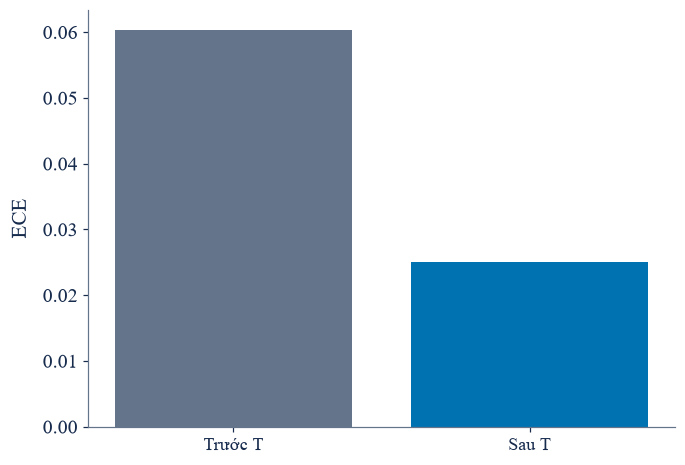

# Lưu kết quả: Xuất hình: ece comparison


In [60]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(
    ["Trước T", "Sau T"],
    [
        run_metrics["calibration"]["ece_before"],
        run_metrics["calibration"]["ece_after_temperature"],
    ],
    color=[CHART_COLORS["neutral"], CHART_COLORS["primary"]],
)
ax.set(ylabel="ECE")
save_fig(fig, "evaluation/ece_comparison")

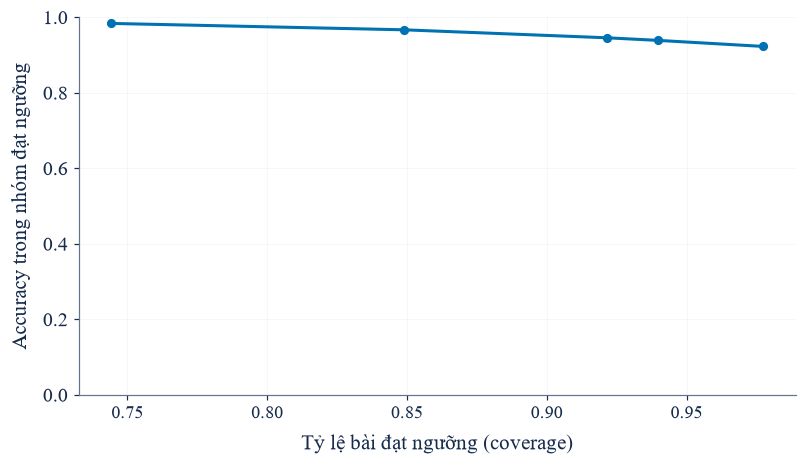

# Lưu kết quả: Xuất hình: coverage accuracy
 threshold  count  coverage  accuracy
      0.50  29316  0.977363  0.922670
      0.68  28186  0.939690  0.938693
      0.75  27644  0.921620  0.945485
      0.90  25464  0.848941  0.966659
      0.95  22322  0.744191  0.983604
      0.99      0  0.000000       NaN


In [61]:
prob = temperature_probabilities(raw_logits, T_OPTIMAL)
selected = prob[np.arange(len(prob)), _cal_preds]
routing = []
for value in [0.50, 0.68, 0.75, 0.90, 0.95, 0.99]:
    mask = selected >= value
    routing.append(
        {
            "threshold": value,
            "count": int(mask.sum()),
            "coverage": float(mask.mean()),
            "accuracy": float((_cal_preds[mask] == np.asarray(y_true_ids)[mask]).mean())
            if mask.any()
            else None,
        }
    )
write_json(RUN_ROOT / "result/evaluation/routing_simulation.json", routing)
valid = [r for r in routing if r["accuracy"] is not None]
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.plot(
    [r["coverage"] for r in valid],
    [r["accuracy"] for r in valid],
    "o-",
    color=CHART_COLORS["primary"],
)
ax.set(
    xlabel="Tỷ lệ bài đạt ngưỡng (coverage)",
    ylabel="Accuracy trong nhóm đạt ngưỡng",
    ylim=(0, 1),
)
if not valid:
    ax.text(
        0.5,
        0.5,
        "Không có mẫu đạt các ngưỡng đang xét",
        ha="center",
        va="center",
        transform=ax.transAxes,
    )
ax.grid(alpha=0.2)
save_fig(fig, "evaluation/coverage_accuracy")
print(pd.DataFrame(routing).to_string(index=False))

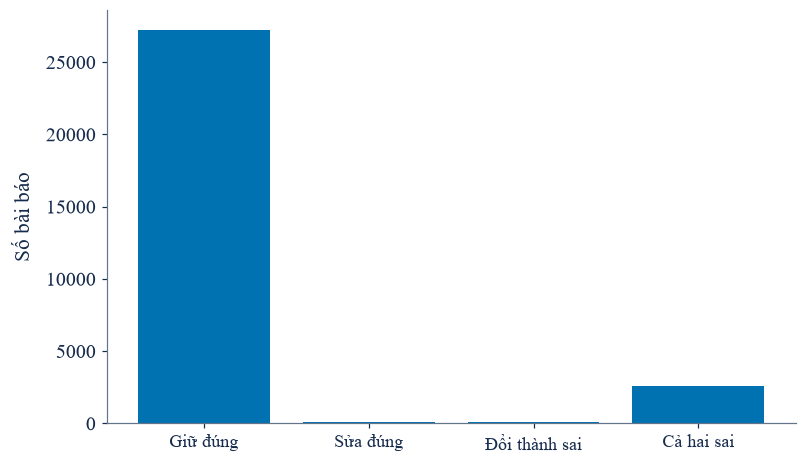

# Lưu kết quả: Xuất hình: decision transitions


In [62]:
true = np.asarray(y_true_ids)
base = np.asarray(y_pred_ids)
cal = np.asarray(_cal_preds)
transitions = {
    "Giữ đúng": int(((base == true) & (cal == true)).sum()),
    "Sửa đúng": int(((base != true) & (cal == true)).sum()),
    "Đổi thành sai": int(((base == true) & (cal != true)).sum()),
    "Cả hai sai": int(((base != true) & (cal != true)).sum()),
}
write_json(RUN_ROOT / "result/evaluation/decision_transitions.json", transitions)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.bar(list(transitions), list(transitions.values()), color=CHART_COLORS["primary"])
ax.set(ylabel="Số bài báo")
save_fig(fig, "evaluation/decision_transitions")

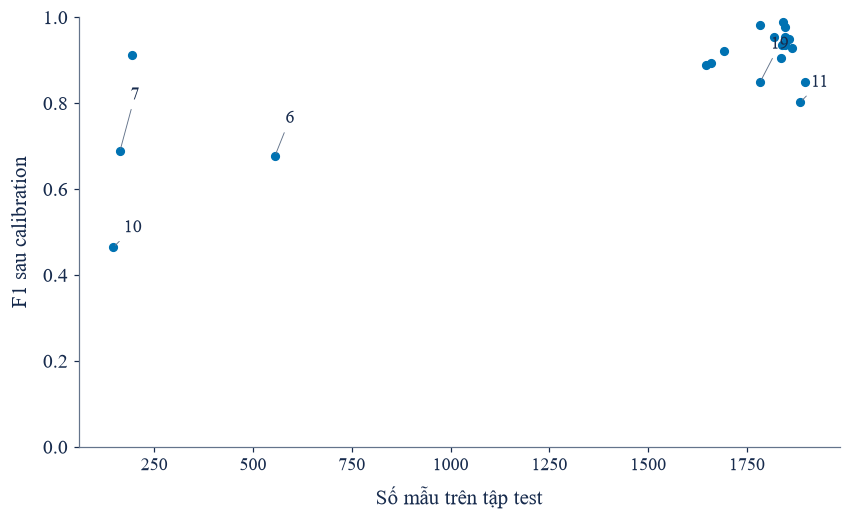

# Lưu kết quả: Xuất hình: support vs f1


In [63]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    [_cal_report[c]["support"] for c in classes],
    [_cal_report[c]["f1-score"] for c in classes],
    color=CHART_COLORS["primary"],
)
_marked_points = set()
for rank, (i, c) in enumerate(
    sorted(enumerate(classes), key=lambda pair: _cal_report[pair[1]]["f1-score"])[:5]
):
    point = (_cal_report[c]["support"], _cal_report[c]["f1-score"])
    if point not in _marked_points:
        ax.annotate(
            str(i),
            point,
            xytext=(7, 10 + 12 * (rank % 3)),
            textcoords="offset points",
            fontsize=12,
            arrowprops={"arrowstyle": "-", "color": CHART_COLORS["neutral"], "lw": 0.6},
        )
        _marked_points.add(point)
ax.set(xlabel="Số mẫu trên tập test", ylabel="F1 sau calibration", ylim=(0, 1))
save_fig(fig, "evaluation/support_vs_f1")

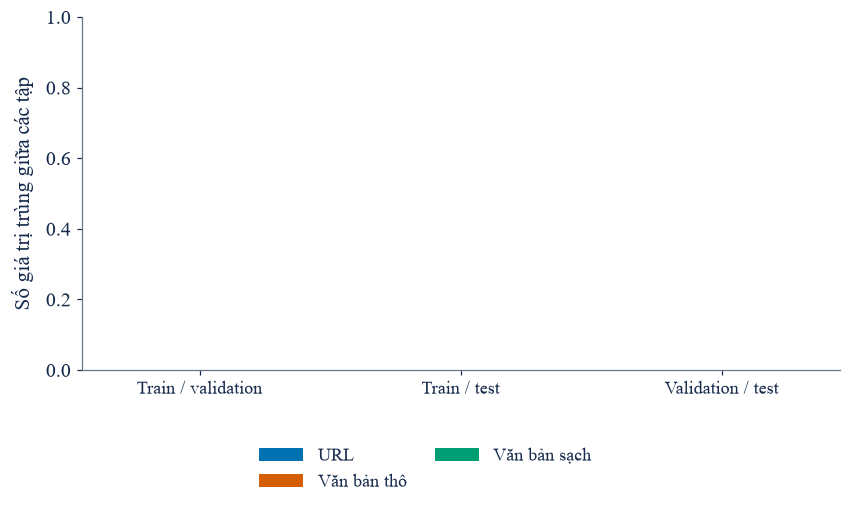

# Lưu kết quả: Xuất hình: train test overlap


In [64]:
pairs = audit["split_overlap"]
fig, ax = plt.subplots(figsize=(8, 4.8))
names = ["Train / validation", "Train / test", "Validation / test"]
positions = np.arange(len(names))
for offset, key, label, color in [
    (-0.22, "url", "URL", "primary"),
    (0, "raw_text", "Văn bản thô", "comparison"),
    (0.22, "clean_text", "Văn bản sạch", "positive"),
]:
    ax.bar(
        positions + offset,
        [pairs[p][key] for p in pairs],
        0.2,
        label=label,
        color=CHART_COLORS[color],
    )
ax.set(xticks=positions, xticklabels=names, ylabel="Số giá trị trùng giữa các tập")
ax.set_ylim(0, max(1, max(v for p in pairs.values() for v in p.values()) * 1.2))
ax.legend()
save_fig(fig, "dataset/train_test_overlap")

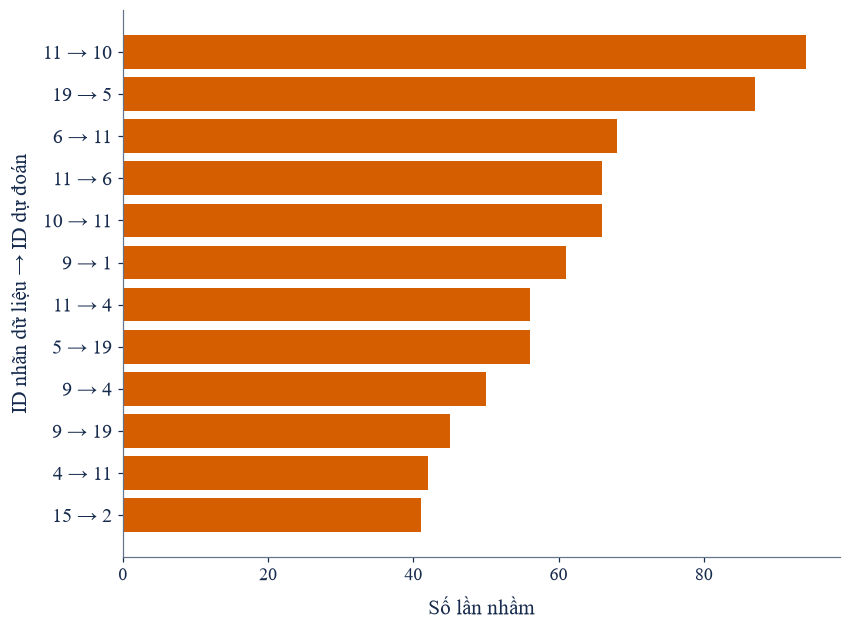

# Lưu kết quả: Xuất hình: top confusions before


In [65]:
errors = [
    (int(_cm[i, j]), i, j)
    for i in range(N_CLASSES)
    for j in range(N_CLASSES)
    if i != j and _cm[i, j] > 0
]
errors = sorted(errors, reverse=True)[:12][::-1]
fig, ax = plt.subplots(figsize=(8, 6))
if errors:
    ax.barh(
        [f"{i} → {j}" for _, i, j in errors],
        [n for n, _, _ in errors],
        color=CHART_COLORS["comparison"],
    )
else:
    ax.text(
        0.5, 0.5, "Không có lỗi ngoài đường chéo", ha="center", transform=ax.transAxes
    )
ax.set(xlabel="Số lần nhầm", ylabel="ID nhãn dữ liệu → ID dự đoán")
save_fig(fig, "evaluation/top_confusions_before")

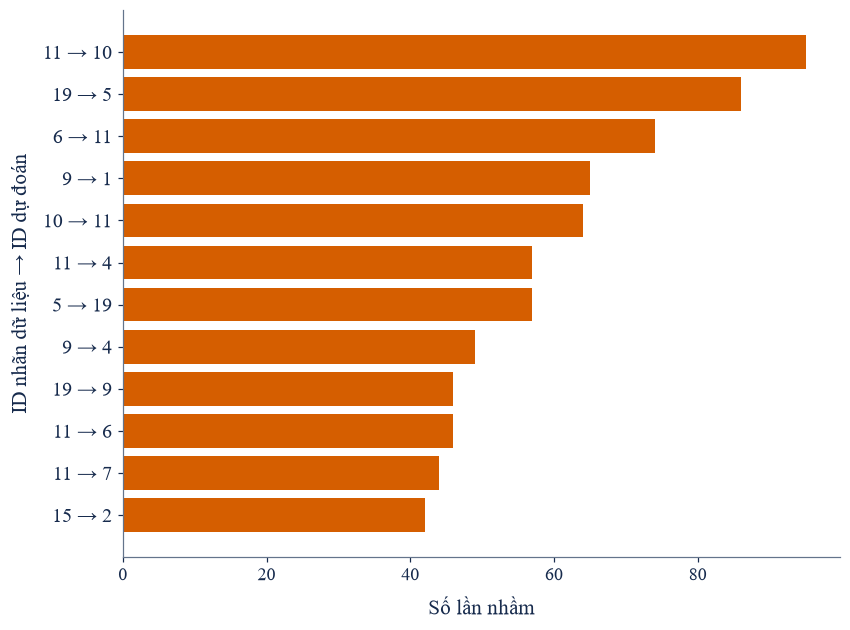

# Lưu kết quả: Xuất hình: top confusions after


In [66]:
errors = [
    (int(_cm_cal[i, j]), i, j)
    for i in range(N_CLASSES)
    for j in range(N_CLASSES)
    if i != j and _cm_cal[i, j] > 0
]
errors = sorted(errors, reverse=True)[:12][::-1]
fig, ax = plt.subplots(figsize=(8, 6))
if errors:
    ax.barh(
        [f"{i} → {j}" for _, i, j in errors],
        [n for n, _, _ in errors],
        color=CHART_COLORS["comparison"],
    )
else:
    ax.text(
        0.5, 0.5, "Không có lỗi ngoài đường chéo", ha="center", transform=ax.transAxes
    )
ax.set(xlabel="Số lần nhầm", ylabel="ID nhãn dữ liệu → ID dự đoán")
save_fig(fig, "evaluation/top_confusions_after")

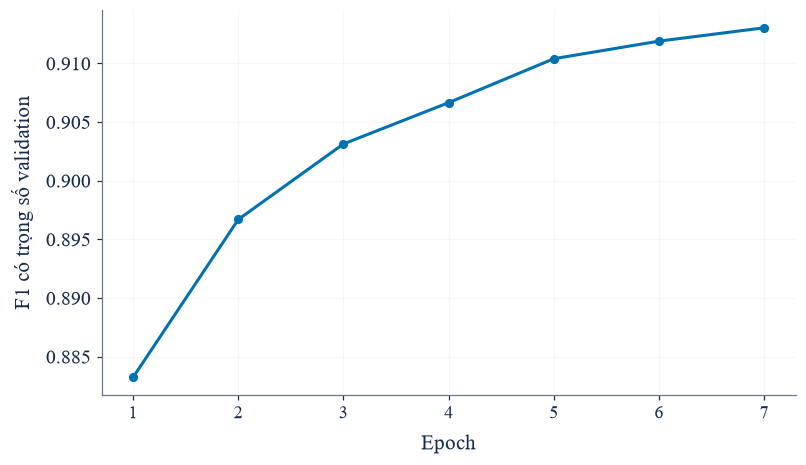

# Lưu kết quả: Xuất hình: eval weighted f1


In [67]:
history_figure(
    "eval_f1_weighted",
    "training/eval_weighted_f1",
    "F1 có trọng số validation",
    xkey="epoch",
)

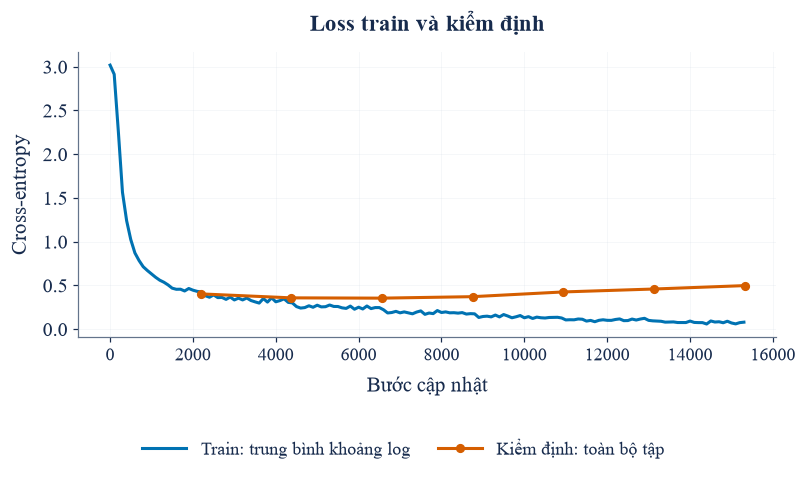

# Lưu kết quả: Xuất hình: train validation loss


In [68]:
# So sánh loss train và loss kiểm định trong một biểu đồ độc lập.
training_points = [
    point for point in log_history if "loss" in point and "eval_loss" not in point
]
evaluation_points = [point for point in log_history if "eval_loss" in point]
if training_points and evaluation_points:
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    ax.plot(
        [point["step"] for point in training_points],
        [point["loss"] for point in training_points],
        color=CHART_COLORS["primary"],
        label="Train: trung bình khoảng log",
    )
    ax.plot(
        [point["step"] for point in evaluation_points],
        [point["eval_loss"] for point in evaluation_points],
        "o-",
        color=CHART_COLORS["comparison"],
        label="Kiểm định: toàn bộ tập",
    )
    ax.set(
        xlabel="Bước cập nhật", ylabel="Cross-entropy", title="Loss train và kiểm định"
    )
    ax.legend()
    ax.grid(alpha=0.2)
    save_fig(fig, "training/train_validation_loss")

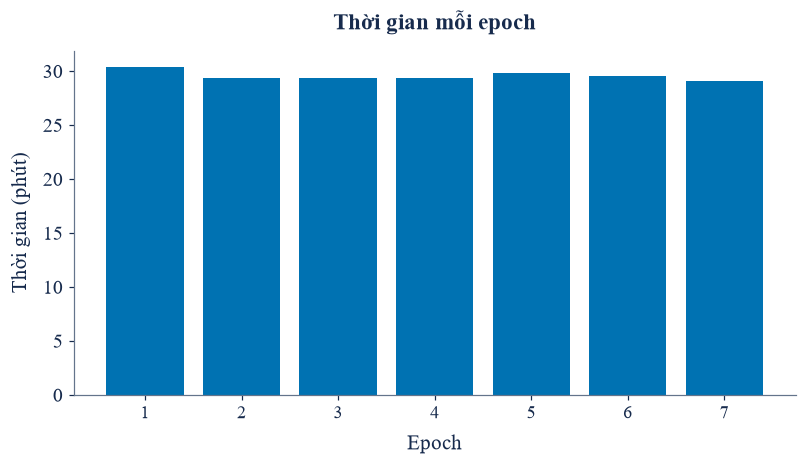

# Lưu kết quả: Xuất hình: epoch duration


In [69]:
# Thời gian mỗi epoch, gồm train và kiểm định.
epoch_timings = [point for point in log_history if "epoch_duration_seconds" in point]
if epoch_timings:
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    ax.bar(
        [point["epoch"] for point in epoch_timings],
        [point["epoch_duration_seconds"] / 60 for point in epoch_timings],
        color=CHART_COLORS["primary"],
    )
    ax.set(xlabel="Epoch", ylabel="Thời gian (phút)", title="Thời gian mỗi epoch")
    save_fig(fig, "training/epoch_duration")

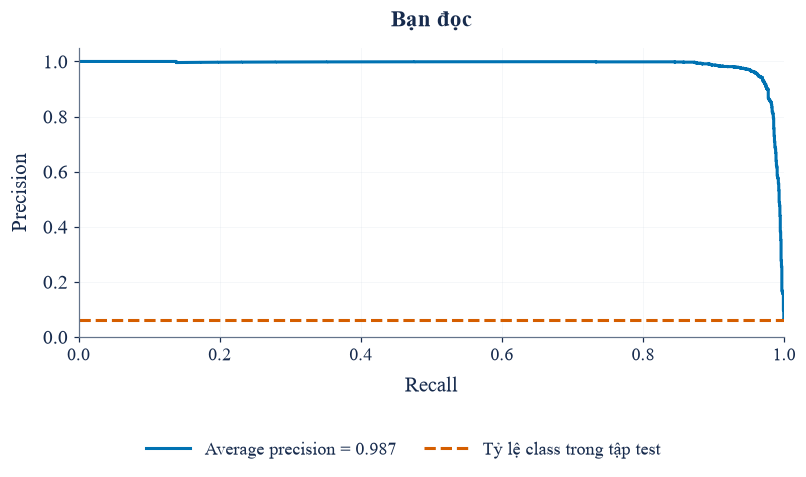

# Lưu kết quả: Xuất hình: ban-doc


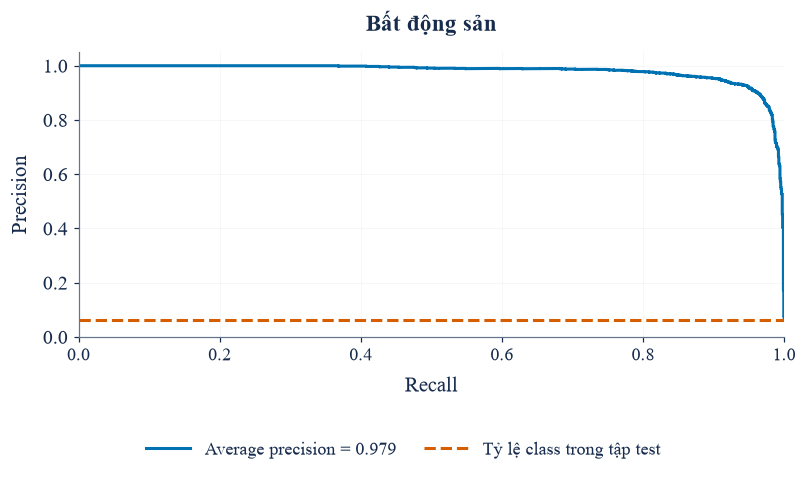

# Lưu kết quả: Xuất hình: bat-dong-san


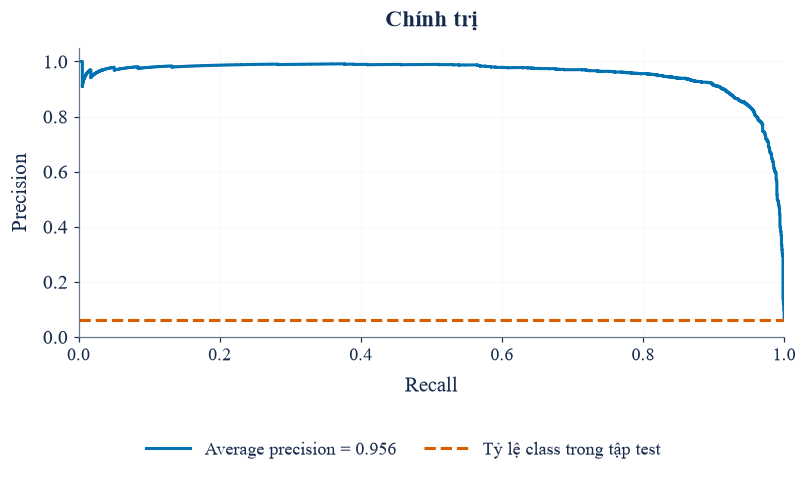

# Lưu kết quả: Xuất hình: chinh-tri


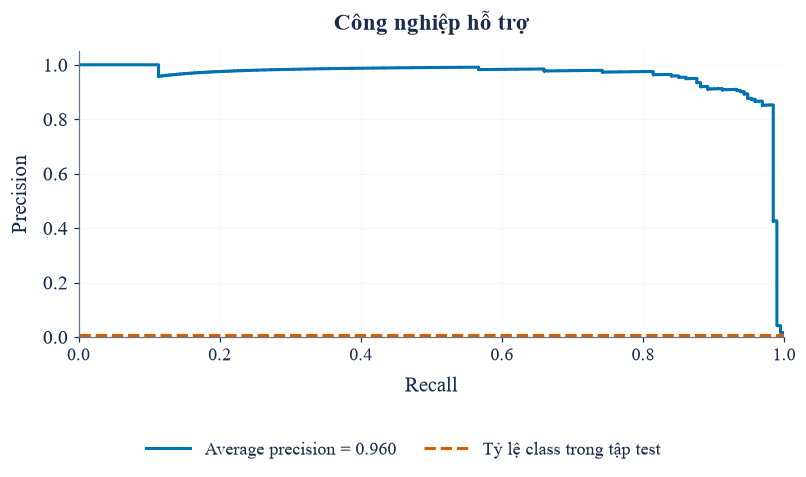

# Lưu kết quả: Xuất hình: cong-nghiep-ho-tro


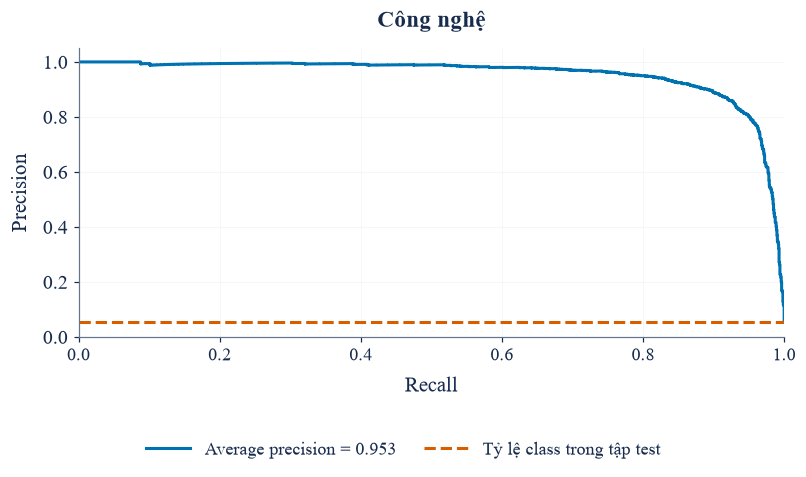

# Lưu kết quả: Xuất hình: cong-nghe


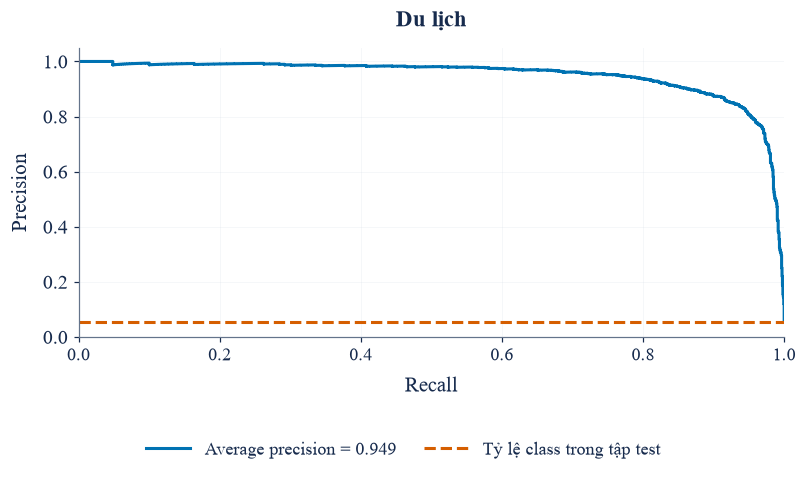

# Lưu kết quả: Xuất hình: du-lich


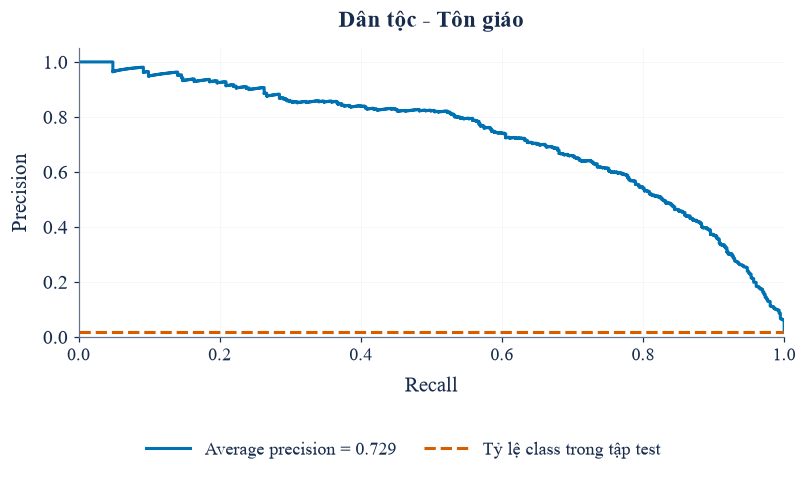

# Lưu kết quả: Xuất hình: dan-toc-ton-giao


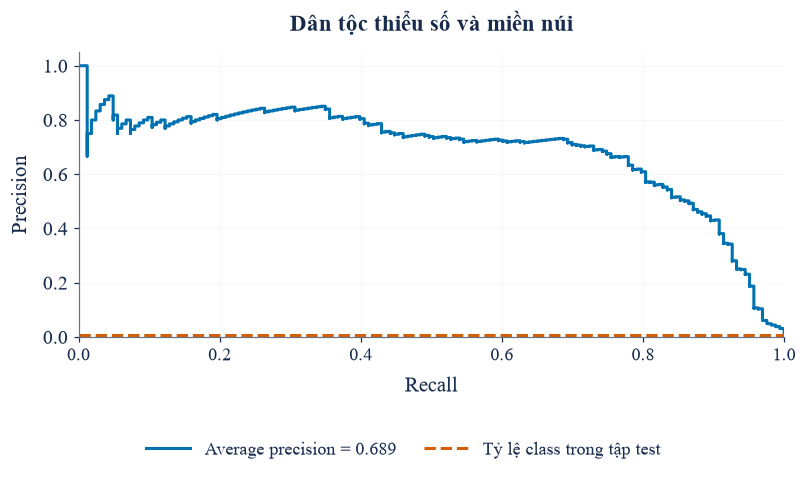

# Lưu kết quả: Xuất hình: dan-toc-thieu-so-va-mien-nui


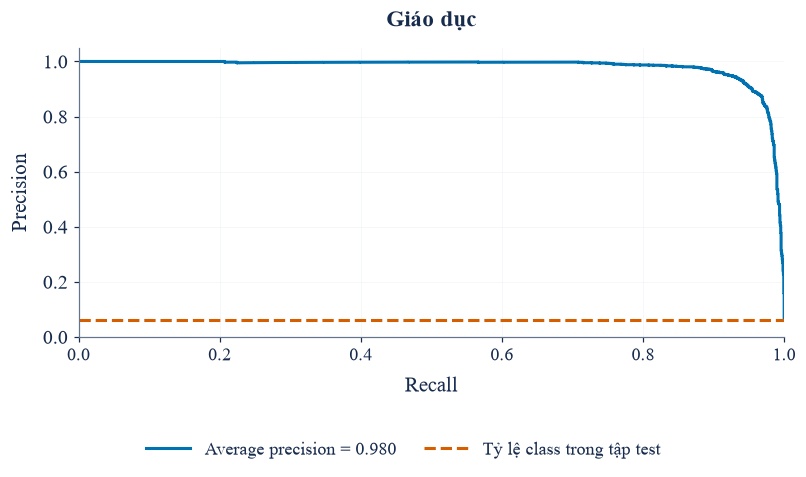

# Lưu kết quả: Xuất hình: giao-duc


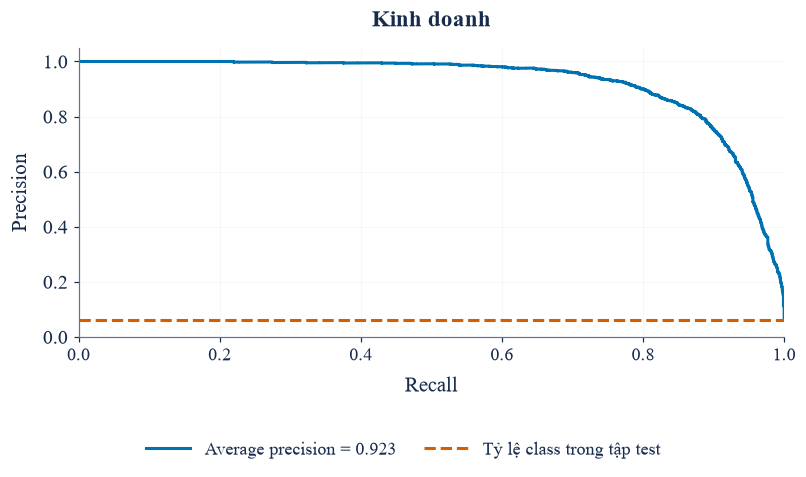

# Lưu kết quả: Xuất hình: kinh-doanh


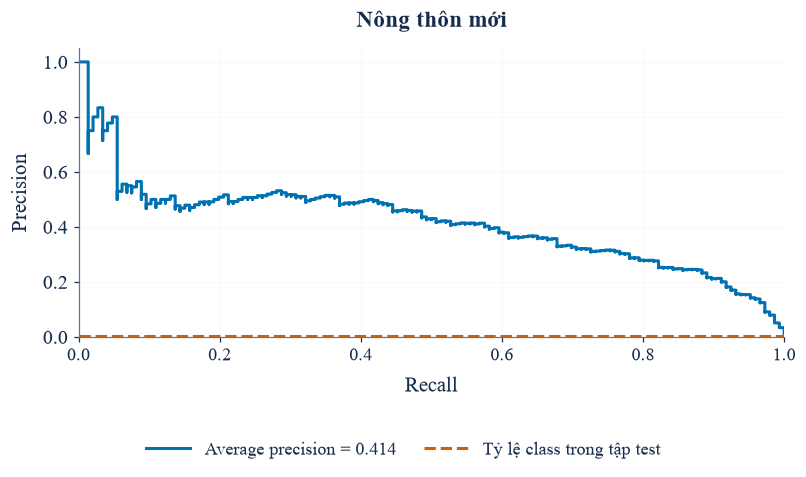

# Lưu kết quả: Xuất hình: nong-thon-moi


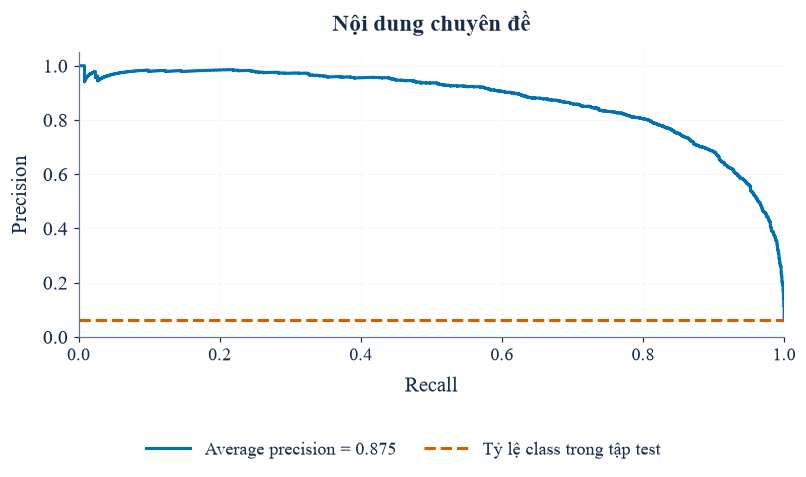

# Lưu kết quả: Xuất hình: noi-dung-chuyen-de


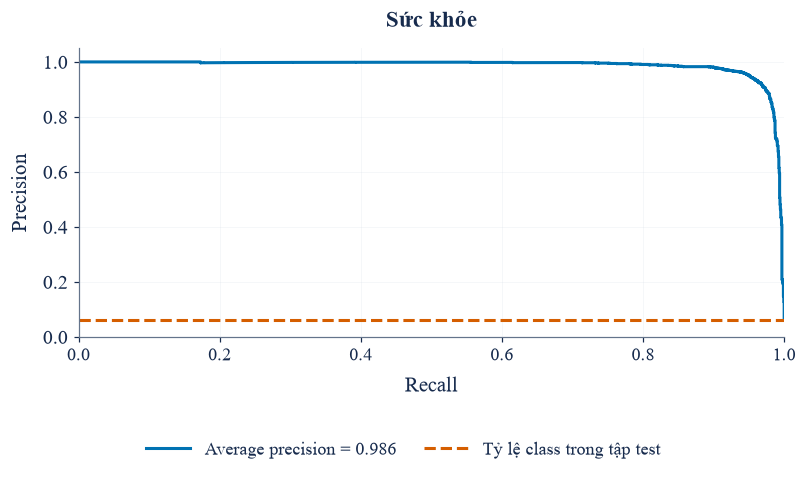

# Lưu kết quả: Xuất hình: suc-khoe


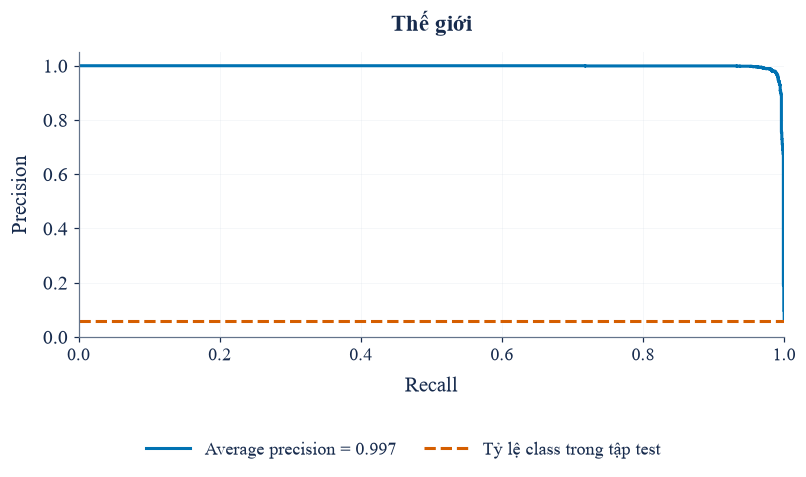

# Lưu kết quả: Xuất hình: the-gioi


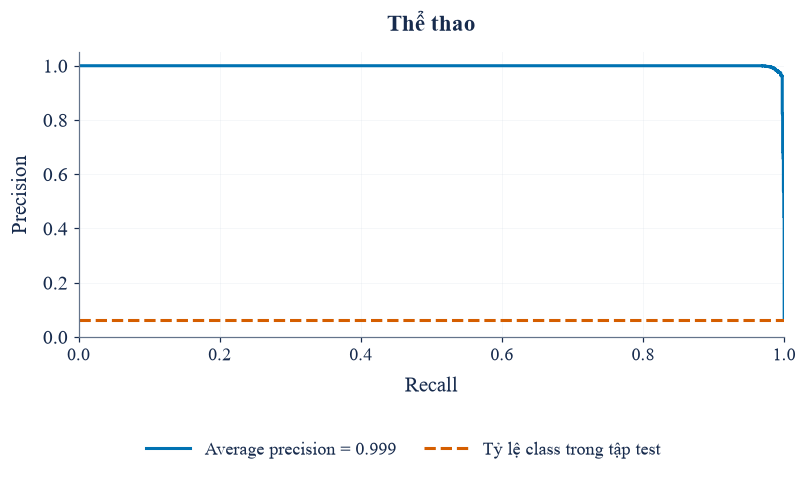

# Lưu kết quả: Xuất hình: the-thao


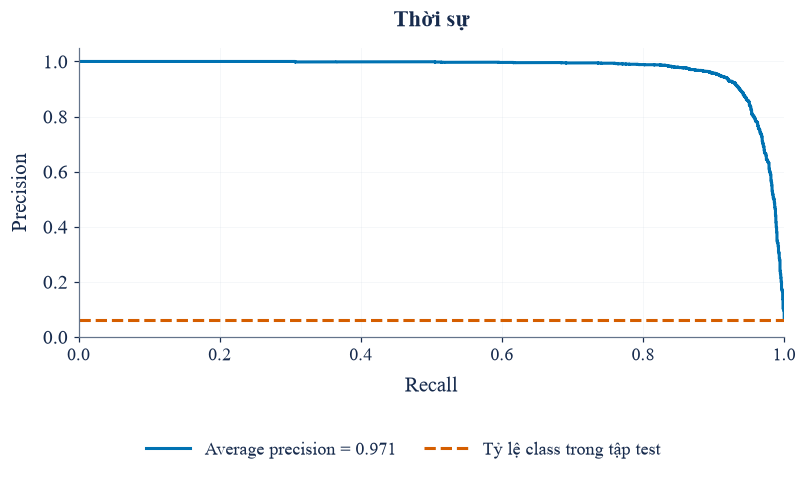

# Lưu kết quả: Xuất hình: thoi-su


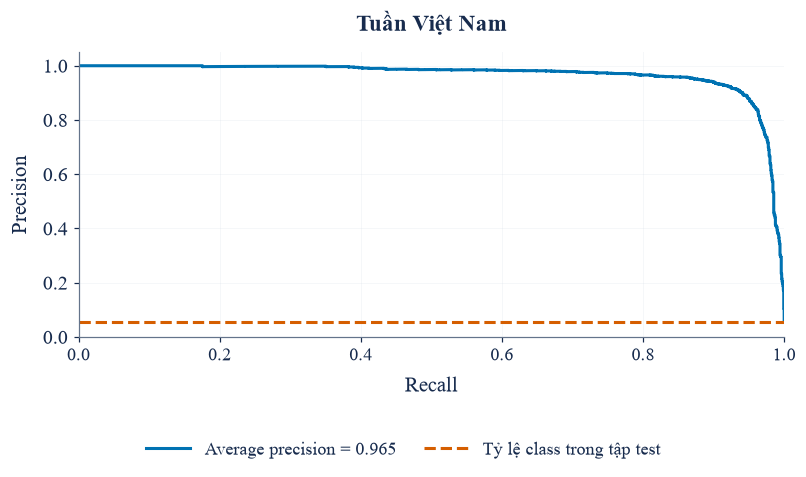

# Lưu kết quả: Xuất hình: tuan-viet-nam


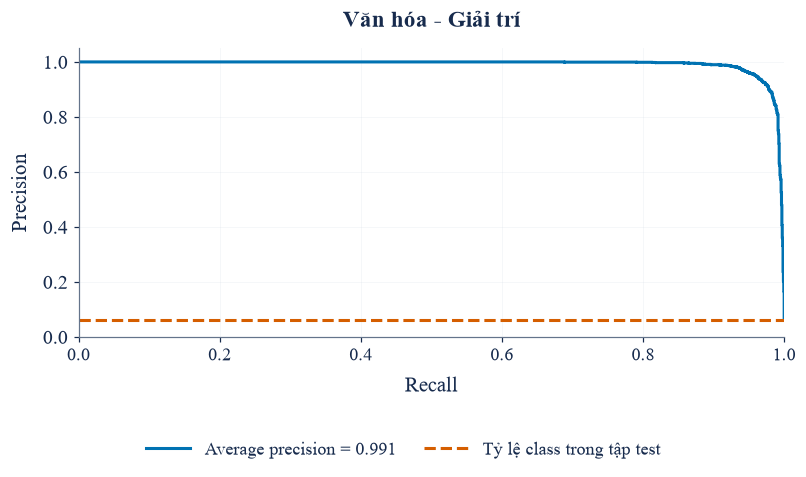

# Lưu kết quả: Xuất hình: van-hoa-giai-tri


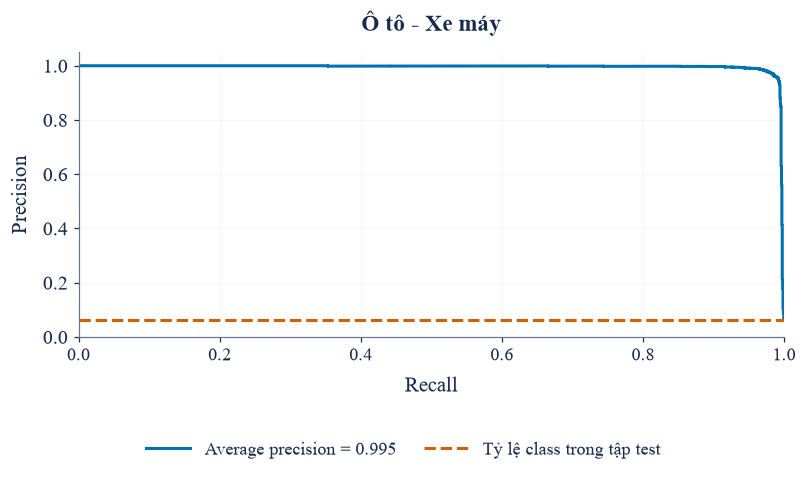

# Lưu kết quả: Xuất hình: oto-xe-may


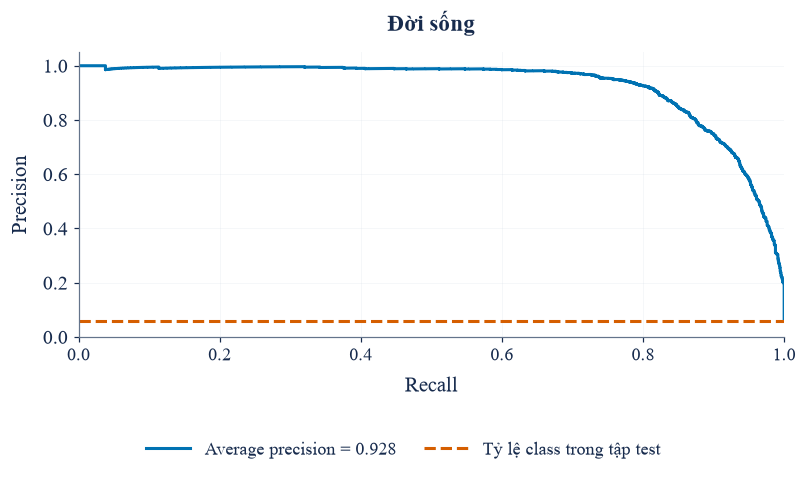

# Lưu kết quả: Xuất hình: doi-song


In [70]:
# Một đường Precision–Recall riêng cho mỗi class.
class_probabilities = temperature_probabilities(raw_logits, T_OPTIMAL)
label_categories = {label: category for category, label in CATEGORY_LABELS.items()}
for class_id, class_name in enumerate(classes):
    binary_labels = np.asarray(y_true_ids) == class_id
    precision_values, recall_values, _ = precision_recall_curve(
        binary_labels, class_probabilities[:, class_id]
    )
    average_precision = average_precision_score(
        binary_labels, class_probabilities[:, class_id]
    )
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    ax.step(
        recall_values,
        precision_values,
        where="post",
        color=CHART_COLORS["primary"],
        label=f"Average precision = {average_precision:.3f}",
    )
    ax.axhline(
        binary_labels.mean(),
        linestyle="--",
        color=CHART_COLORS["comparison"],
        label="Tỷ lệ class trong tập test",
    )
    ax.set(
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.05),
        title=textwrap.fill(class_name, width=48),
    )
    ax.legend()
    ax.grid(alpha=0.2)
    save_fig(fig, "evaluation/precision_recall/" + label_categories[class_name])

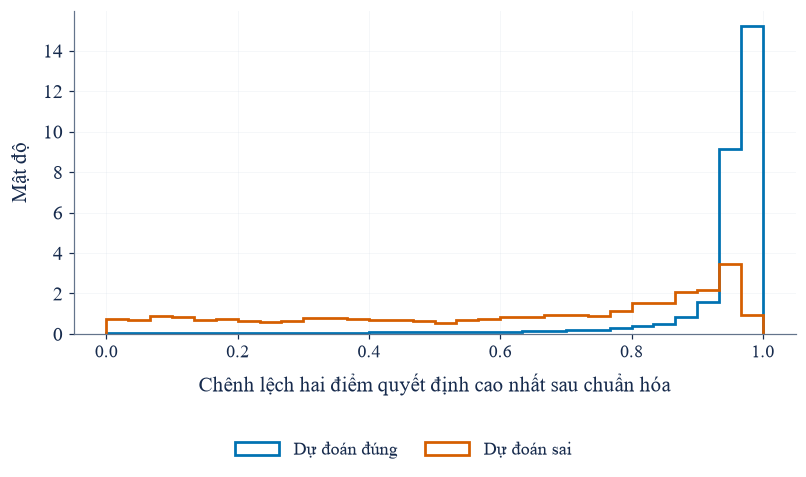

# Lưu kết quả: Xuất hình: decision margin


In [71]:
# So sánh độ cách biệt quyết định của bài dự đoán đúng và sai.
decision_scores = temperature_probabilities(raw_logits, T_OPTIMAL) / thresholds
normalized_scores = decision_scores / decision_scores.sum(axis=1, keepdims=True)
sorted_scores = np.sort(normalized_scores, axis=1)
decision_margin = sorted_scores[:, -1] - sorted_scores[:, -2]
prediction_correct = np.asarray(_cal_preds) == np.asarray(y_true_ids)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
for selected, label, color in [
    (prediction_correct, "Dự đoán đúng", CHART_COLORS["primary"]),
    (~prediction_correct, "Dự đoán sai", CHART_COLORS["comparison"]),
]:
    if selected.any():
        ax.hist(
            decision_margin[selected],
            bins=np.linspace(0, 1, 31).tolist(),
            density=True,
            histtype="step",
            linewidth=1.8,
            color=color,
            label=label,
        )
ax.set(xlabel="Chênh lệch hai điểm quyết định cao nhất sau chuẩn hóa", ylabel="Mật độ")
ax.legend()
ax.grid(alpha=0.2)
save_fig(fig, "evaluation/decision_margin")

In [72]:
update_manifest(RUN_ROOT)
figure_manifest = json.loads(
    (RUN_ROOT / "result/figure_manifest.json").read_text(encoding="utf-8")
)
print("# Huấn luyện, đánh giá và hiệu chỉnh PhoBERT hoàn tất.")
print(f"# Có {len(figure_manifest)} hình độc lập; mỗi hình là PNG 300 dpi.")
print("# Model, tokenizer, cấu hình suy luận và chỉ số đánh giá đã được lưu.")
print("# Thư mục kết quả: " + str(RUN_ROOT / "result"))


# Huấn luyện, đánh giá và hiệu chỉnh PhoBERT hoàn tất.
# Có 69 hình độc lập; mỗi hình là PNG 300 dpi.
# Model, tokenizer, cấu hình suy luận và chỉ số đánh giá đã được lưu.
# Thư mục kết quả: C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\result
